In [1]:
# CELL 1: INSTALL & IMPORT ALL LIBRARIES

!pip install plotly kaleido -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Pandas display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 1000)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# CELL 2: PROFESSIONAL VISUALIZATION STYLE

# --- Color Palette ---
COLORS = {
    'primary':    '#1B4965',   # Deep Navy
    'secondary':  '#5FA8D3',   # Sky Blue
    'accent':     '#CA6702',   # Burnt Orange
    'highlight':  '#AE2012',   # Crimson
    'success':    '#386641',   # Forest Green
    'purple':     '#7B2D8E',   # Royal Purple
    'teal':       '#2A9D8F',   # Teal
    'gold':       '#E9C46A',   # Gold
    'neutral':    '#6C757D',   # Gray
    'light_bg':   '#F0F4F8',   # Light Background
    'dark_text':  '#2D3436',   # Dark Text
}

PALETTE_8 = ['#1B4965', '#5FA8D3', '#CA6702', '#AE2012',
             '#386641', '#7B2D8E', '#2A9D8F', '#E9C46A']

PALETTE_GRADIENT = ['#0B3D5B', '#1B4965', '#2E6F95', '#5FA8D3',
                    '#89C4E1', '#B8DCF0', '#D4EAF7', '#EAF4FB']

HEATMAP_CMAP = 'YlOrRd'
DIVERGING_CMAP = 'RdBu_r'

# --- Matplotlib Global Style ---
plt.style.use('seaborn-v0_8-whitegrid')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#FAFBFC',
    'axes.edgecolor': '#DEE2E6',
    'axes.labelcolor': COLORS['dark_text'],
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlepad': 15,
    'axes.labelsize': 11,
    'axes.grid': True,
    'grid.color': '#E9ECEF',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'xtick.color': COLORS['neutral'],
    'ytick.color': COLORS['neutral'],
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'font.family': 'sans-serif',
    'font.size': 10,
    'legend.frameon': True,
    'legend.facecolor': 'white',
    'legend.edgecolor': '#DEE2E6',
    'legend.fontsize': 9,
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
})

# --- Seaborn Style ---
sns.set_palette(PALETTE_8)

# --- Helper Functions ---
def style_table(df, title=""):
    """Apply professional styling to pandas DataFrame"""
    styled = (df.style
        .set_table_styles([
            {'selector': 'th', 'props': [
                ('background-color', COLORS['primary']),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('padding', '8px 12px'),
                ('text-align', 'center'),
                ('font-size', '11px')
            ]},
            {'selector': 'td', 'props': [
                ('padding', '6px 12px'),
                ('border-bottom', '1px solid #E9ECEF'),
                ('font-size', '10px')
            ]},
            {'selector': 'tr:nth-child(even)', 'props': [
                ('background-color', '#F8F9FA')
            ]},
            {'selector': 'tr:hover', 'props': [
                ('background-color', '#E3F2FD')
            ]},
        ])
        .set_caption(f'📊 {title}')
        .set_properties(**{'text-align': 'center'})
    )
    return styled

def add_watermark(fig, text="E-Commerce Analytics"):
    """Add subtle watermark to matplotlib figure"""
    fig.text(0.99, 0.01, text,
             fontsize=7, color='#CED4DA',
             ha='right', va='bottom', style='italic')

def format_currency(x, pos):
    """Format axis ticks as currency"""
    if x >= 1_000_000:
        return f'${x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'${x/1_000:.0f}K'
    else:
        return f'${x:.0f}'

def format_number(x, pos):
    """Format axis ticks as numbers"""
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

print("✅ Professional style system loaded!")
print(f"   Primary Color: {COLORS['primary']}")
print(f"   Palette: {PALETTE_8[:4]}...")

✅ Professional style system loaded!
   Primary Color: #1B4965
   Palette: ['#1B4965', '#5FA8D3', '#CA6702', '#AE2012']...


In [3]:
# CELL 3: LOAD ALL CSV FILES & DATA PREPARATION

# --- Load CSVs ---
print("📂 Loading datasets...\n")

users = pd.read_csv('users.csv')
orders = pd.read_csv('orders.csv')
order_items = pd.read_csv('order_items.csv')
products = pd.read_csv('products.csv')
events = pd.read_csv('events.csv')
inventory = pd.read_csv('inventory_items.csv')
dist_centers = pd.read_csv('distribution_centers.csv')

# --- Parse Dates ---
date_cols_orders = ['created_at', 'shipped_at', 'delivered_at', 'returned_at']
date_cols_items = ['created_at', 'shipped_at', 'delivered_at', 'returned_at']
date_cols_events = ['created_at']
date_cols_inventory = ['created_at', 'sold_at']
date_cols_users = ['created_at']

for col in date_cols_orders:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

for col in date_cols_items:
    order_items[col] = pd.to_datetime(order_items[col], errors='coerce')

for col in date_cols_events:
    events[col] = pd.to_datetime(events[col], errors='coerce')

for col in date_cols_inventory:
    inventory[col] = pd.to_datetime(inventory[col], errors='coerce')

users['created_at'] = pd.to_datetime(users['created_at'], errors='coerce')

# --- Create Helper Columns ---
order_items['month'] = order_items['created_at'].dt.to_period('M')
order_items['year'] = order_items['created_at'].dt.year
order_items['year_month'] = order_items['created_at'].dt.strftime('%Y-%m')
order_items['date'] = order_items['created_at'].dt.date
order_items['is_valid'] = ~order_items['status'].isin(['Cancelled', 'Returned'])

orders['year_month'] = orders['created_at'].dt.strftime('%Y-%m')
orders['date'] = orders['created_at'].dt.date

events['date'] = events['created_at'].dt.date
events['month'] = events['created_at'].dt.to_period('M')

# --- Merged DataFrame (Most Used) ---
df = order_items.merge(products, left_on='product_id', right_on='id', suffixes=('', '_product'))
df = df.merge(users, left_on='user_id', right_on='id', suffixes=('', '_user'))

df_valid = df[df['is_valid']].copy()

# --- Print Summary ---
print("=" * 60)
print("📊 DATASET SUMMARY")
print("=" * 60)
datasets = {
    'Users': users, 'Orders': orders, 'Order Items': order_items,
    'Products': products, 'Events': events, 'Inventory': inventory,
    'Distribution Centers': dist_centers
}
for name, data in datasets.items():
    print(f"  {name:25s} → {data.shape[0]:>8,} rows × {data.shape[1]:>3} cols")

print(f"\n  Merged DataFrame (df)   → {df.shape[0]:>8,} rows × {df.shape[1]:>3} cols")
print(f"  Valid Orders Only       → {df_valid.shape[0]:>8,} rows")
print(f"\n  Date Range: {order_items['created_at'].min().date()} → {order_items['created_at'].max().date()}")
print("=" * 60)
print("✅ Data loaded and ready!")

📂 Loading datasets...

📊 DATASET SUMMARY
  Users                     →  100,000 rows ×  15 cols
  Orders                    →  125,226 rows ×  11 cols
  Order Items               →  181,759 rows ×  16 cols
  Products                  →   29,120 rows ×   9 cols
  Events                    → 2,431,963 rows ×  15 cols
  Inventory                 →  490,705 rows ×  12 cols
  Distribution Centers      →       10 rows ×   4 cols

  Merged DataFrame (df)   →  181,759 rows ×  40 cols
  Valid Orders Only       →  136,437 rows

  Date Range: 2019-01-06 → 2024-01-21
✅ Data loaded and ready!


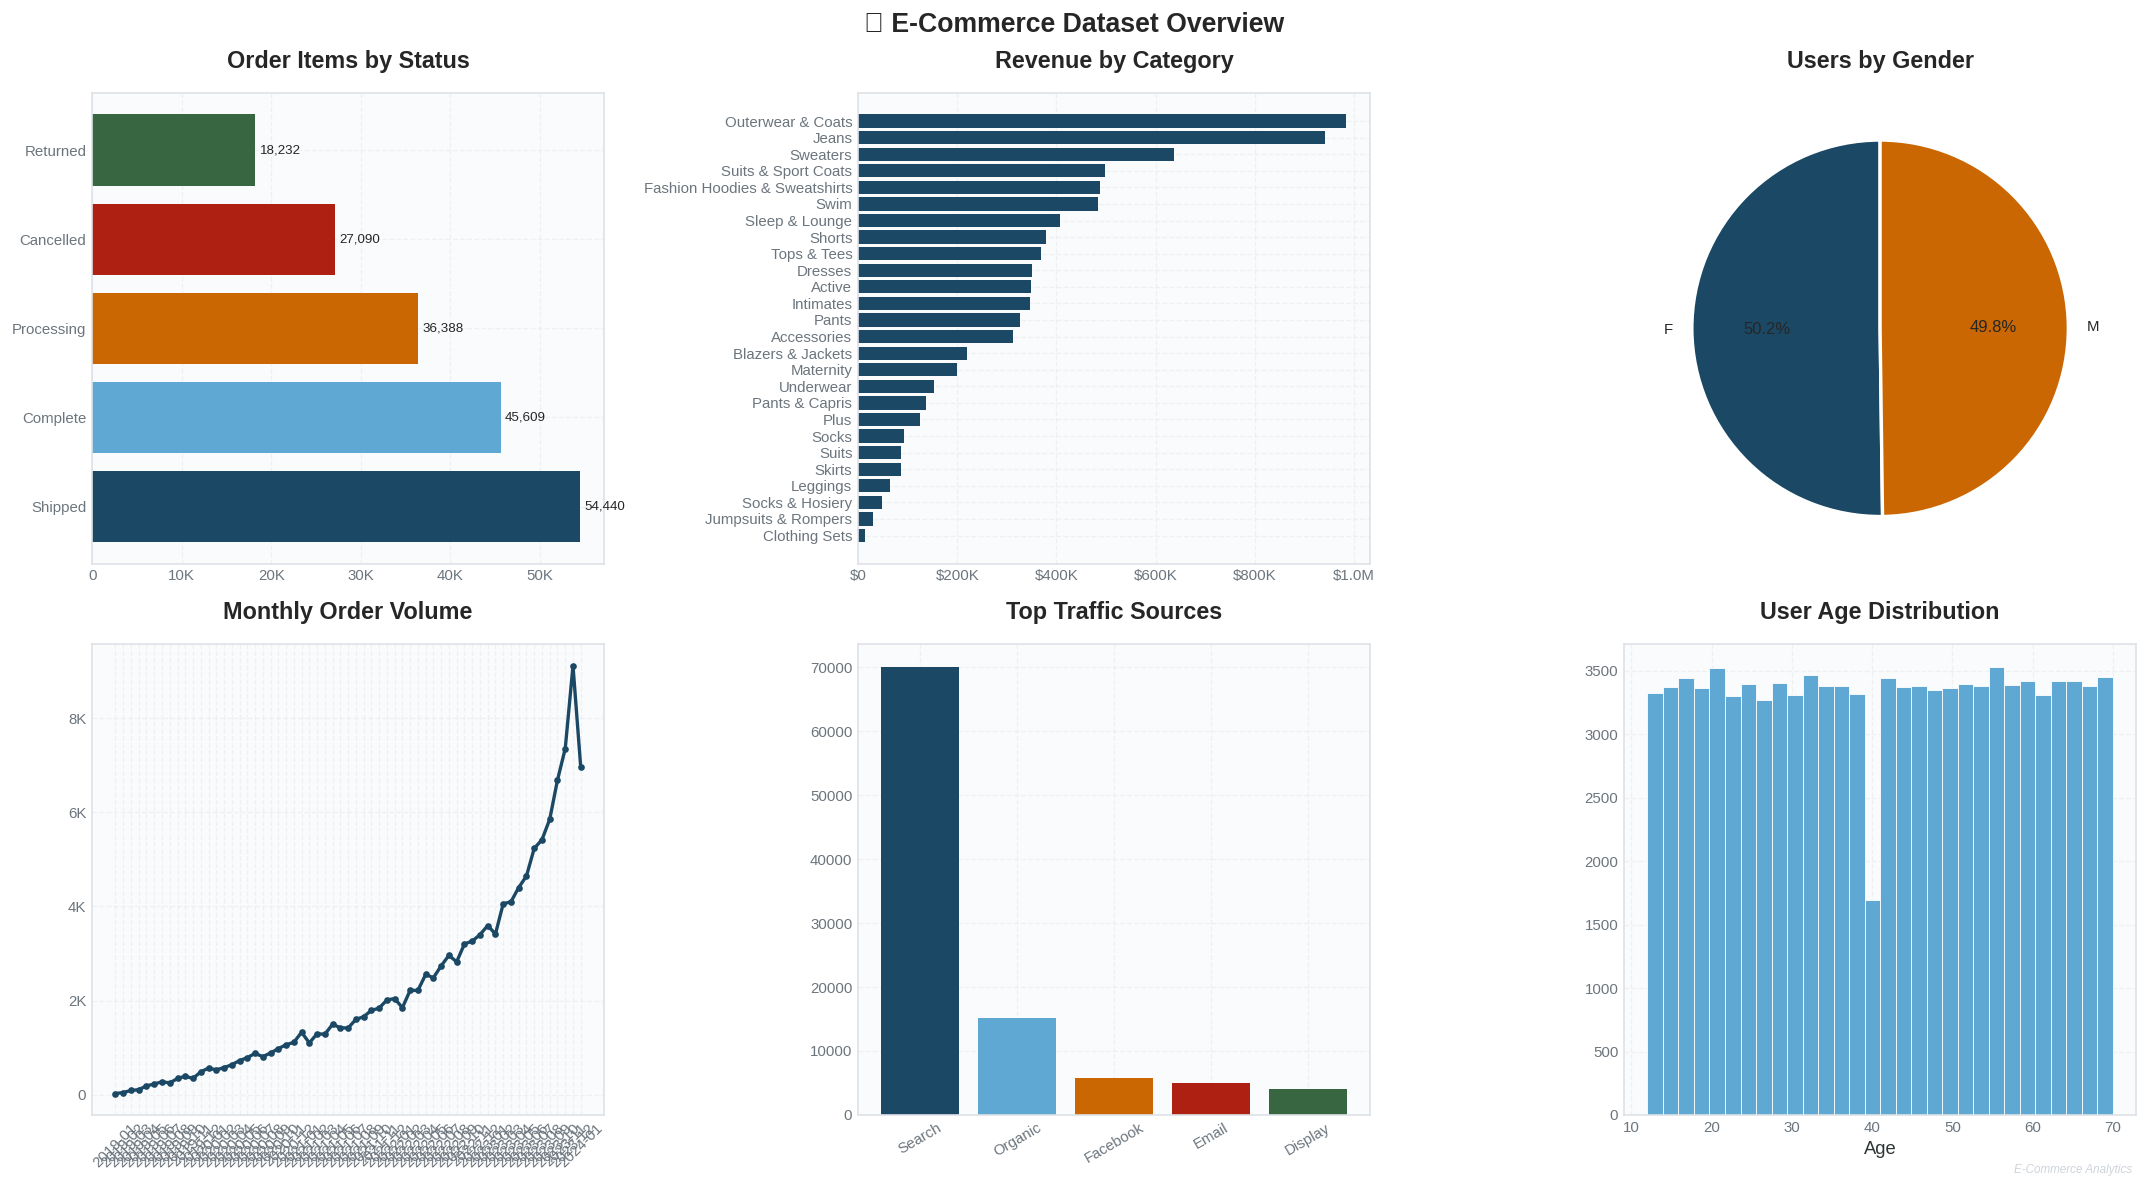

In [4]:
# CELL 4: EXPLORATORY DATA ANALYSIS OVERVIEW

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('📊 E-Commerce Dataset Overview', fontsize=16, fontweight='bold', y=0.98)

# 1. Orders by Status
status_counts = order_items['status'].value_counts()
axes[0,0].barh(status_counts.index, status_counts.values, color=PALETTE_8[:len(status_counts)])
axes[0,0].set_title('Order Items by Status')
axes[0,0].xaxis.set_major_formatter(mticker.FuncFormatter(format_number))
for i, v in enumerate(status_counts.values):
    axes[0,0].text(v + 500, i, f'{v:,}', va='center', fontsize=8)

# 2. Revenue by Category
cat_rev = df_valid.groupby('category')['sale_price'].sum().sort_values(ascending=True)
axes[0,1].barh(cat_rev.index, cat_rev.values, color=COLORS['primary'])
axes[0,1].set_title('Revenue by Category')
axes[0,1].xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))

# 3. Users by Gender
gender = users['gender'].value_counts()
axes[0,2].pie(gender.values, labels=gender.index, autopct='%1.1f%%',
              colors=[COLORS['primary'], COLORS['accent']], startangle=90,
              wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0,2].set_title('Users by Gender')

# 4. Monthly Order Trend
monthly_orders = df_valid.groupby('year_month').size().reset_index(name='count')
axes[1,0].plot(monthly_orders['year_month'], monthly_orders['count'],
               color=COLORS['primary'], linewidth=2, marker='o', markersize=3)
axes[1,0].set_title('Monthly Order Volume')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].yaxis.set_major_formatter(mticker.FuncFormatter(format_number))

# 5. Top Traffic Sources
traffic = users['traffic_source'].value_counts().head(5)
axes[1,1].bar(traffic.index, traffic.values, color=PALETTE_8[:5])
axes[1,1].set_title('Top Traffic Sources')
axes[1,1].tick_params(axis='x', rotation=30)

# 6. Age Distribution
axes[1,2].hist(users['age'].dropna(), bins=30, color=COLORS['secondary'],
               edgecolor='white', linewidth=0.5)
axes[1,2].set_title('User Age Distribution')
axes[1,2].set_xlabel('Age')

plt.tight_layout()
add_watermark(fig)
plt.show()

## **SECTION 1: REVENUE ANALYSIS**

,year_month,total_orders,unique_customers,total_revenue,avg_order_value
49,2023-02,2425,2393,203363.650000,59.550000
50,2023-03,2835,2787,243450.680000,60.020000
51,2023-04,2912,2848,235181.110000,57.380000
52,2023-05,3079,3018,258402.760000,58.700000
53,2023-06,3291,3200,273995.970000,58.970000
54,2023-07,3635,3543,316434.330000,60.470000
55,2023-08,3806,3694,330334.930000,60.970000
56,2023-09,4114,3996,362257.050000,61.900000
57,2023-10,4639,4465,411154.370000,61.500000
58,2023-11,5284,5027,429962.240000,58.470000


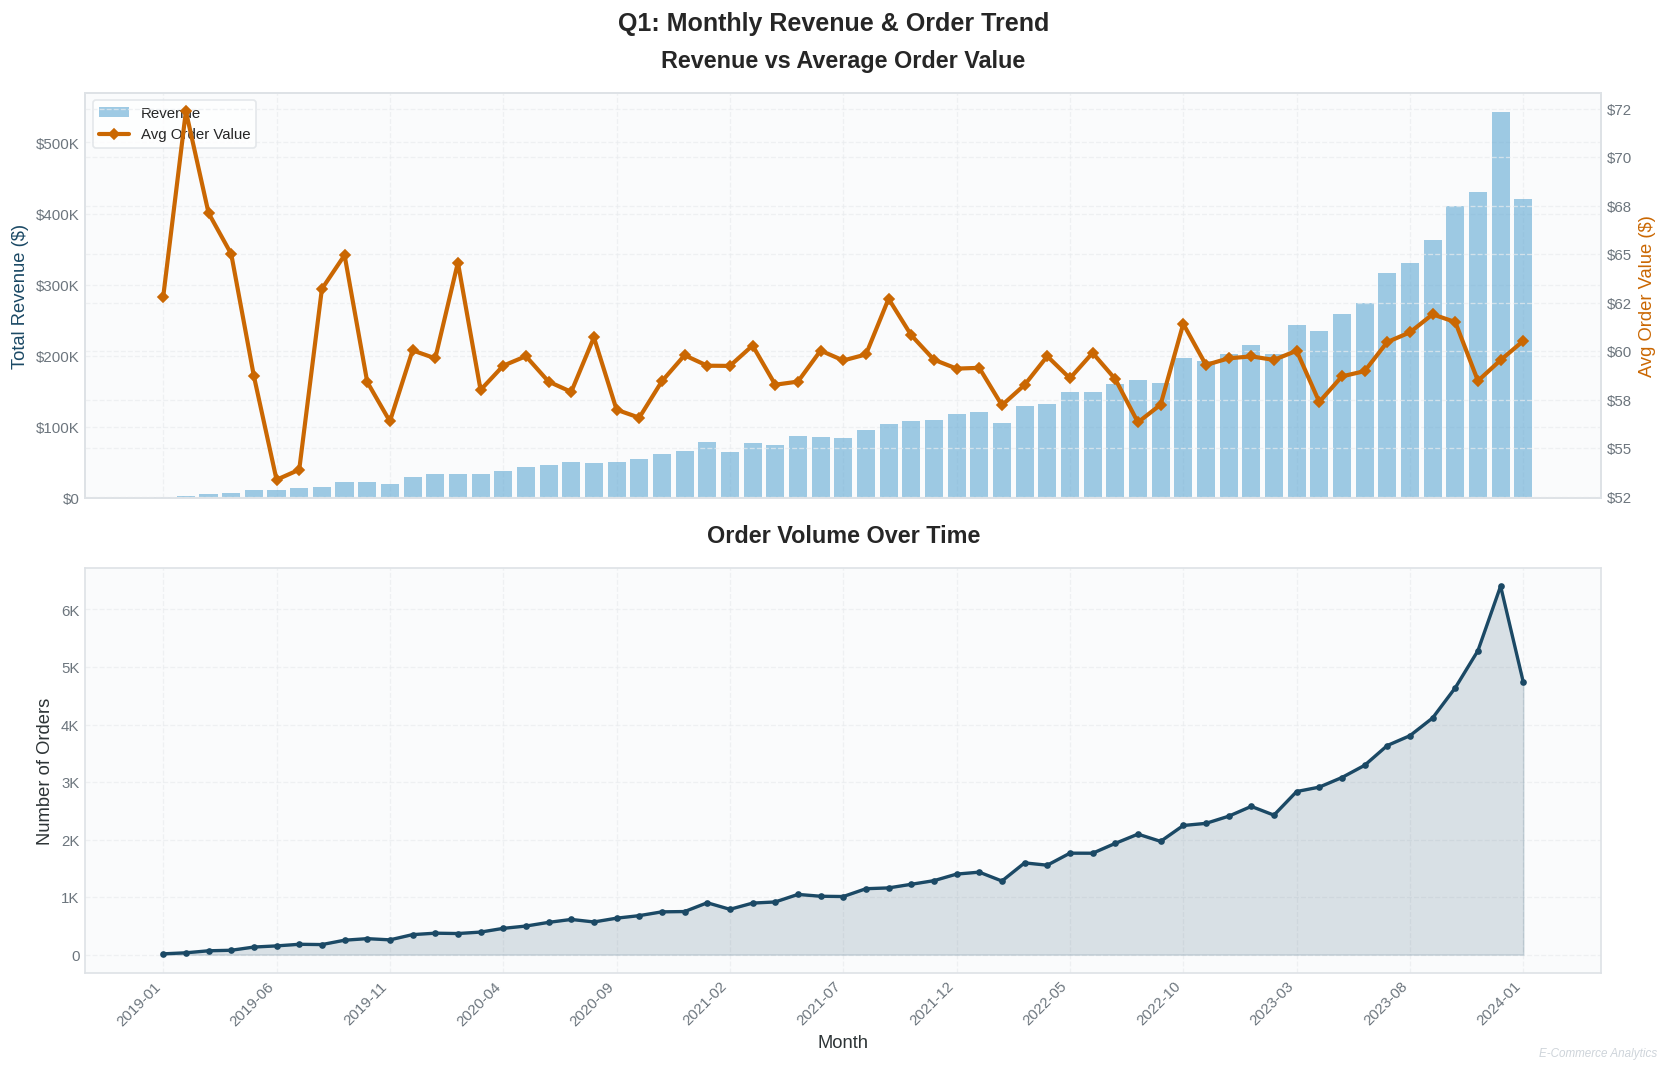

In [5]:
# Q1: MONTHLY REVENUE TREND
# Business Question: How is revenue trending month over month?

# --- Analysis ---
q1 = (df_valid.groupby('year_month')
      .agg(
          total_orders=('order_id', 'nunique'),
          unique_customers=('user_id', 'nunique'),
          total_revenue=('sale_price', 'sum'),
          avg_order_value=('sale_price', 'mean')
      )
      .reset_index()
      .sort_values('year_month'))

q1['total_revenue'] = q1['total_revenue'].round(2)
q1['avg_order_value'] = q1['avg_order_value'].round(2)

display(style_table(q1.tail(12), "Q1: Monthly Revenue Trend (Last 12 Months)"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Q1: Monthly Revenue & Order Trend', fontsize=15, fontweight='bold')

# Revenue bar + line
bars = ax1.bar(q1['year_month'], q1['total_revenue'],
               color=COLORS['secondary'], alpha=0.6, label='Revenue', zorder=2)
ax1_twin = ax1.twinx()
line = ax1_twin.plot(q1['year_month'], q1['avg_order_value'],
                     color=COLORS['accent'], linewidth=2.5, marker='D',
                     markersize=4, label='Avg Order Value', zorder=3)
ax1.set_ylabel('Total Revenue ($)', color=COLORS['primary'])
ax1_twin.set_ylabel('Avg Order Value ($)', color=COLORS['accent'])
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax1_twin.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax1.set_title('Revenue vs Average Order Value')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

# Order volume
ax2.fill_between(range(len(q1)), q1['total_orders'],
                 color=COLORS['primary'], alpha=0.15)
ax2.plot(range(len(q1)), q1['total_orders'],
         color=COLORS['primary'], linewidth=2, marker='o', markersize=3)
ax2.set_ylabel('Number of Orders')
ax2.set_xlabel('Month')
ax2.set_title('Order Volume Over Time')
ax2.set_xticks(range(0, len(q1), max(1, len(q1)//12)))
ax2.set_xticklabels(q1['year_month'].iloc[::max(1, len(q1)//12)], rotation=45, ha='right')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(format_number))

plt.tight_layout()
add_watermark(fig)
plt.show()

,year_month,revenue,running_total,moving_avg_3m
49,2023-02,203363.650000,4103745.850000,206889.120000
50,2023-03,243450.680000,4347196.530000,220475.540000
51,2023-04,235181.110000,4582377.640000,227331.810000
52,2023-05,258402.760000,4840780.410000,245678.180000
53,2023-06,273995.970000,5114776.380000,255859.950000
54,2023-07,316434.330000,5431210.710000,282944.350000
55,2023-08,330334.930000,5761545.640000,306921.740000
56,2023-09,362257.050000,6123802.690000,336342.100000
57,2023-10,411154.370000,6534957.060000,367915.450000
58,2023-11,429962.240000,6964919.300000,401124.550000


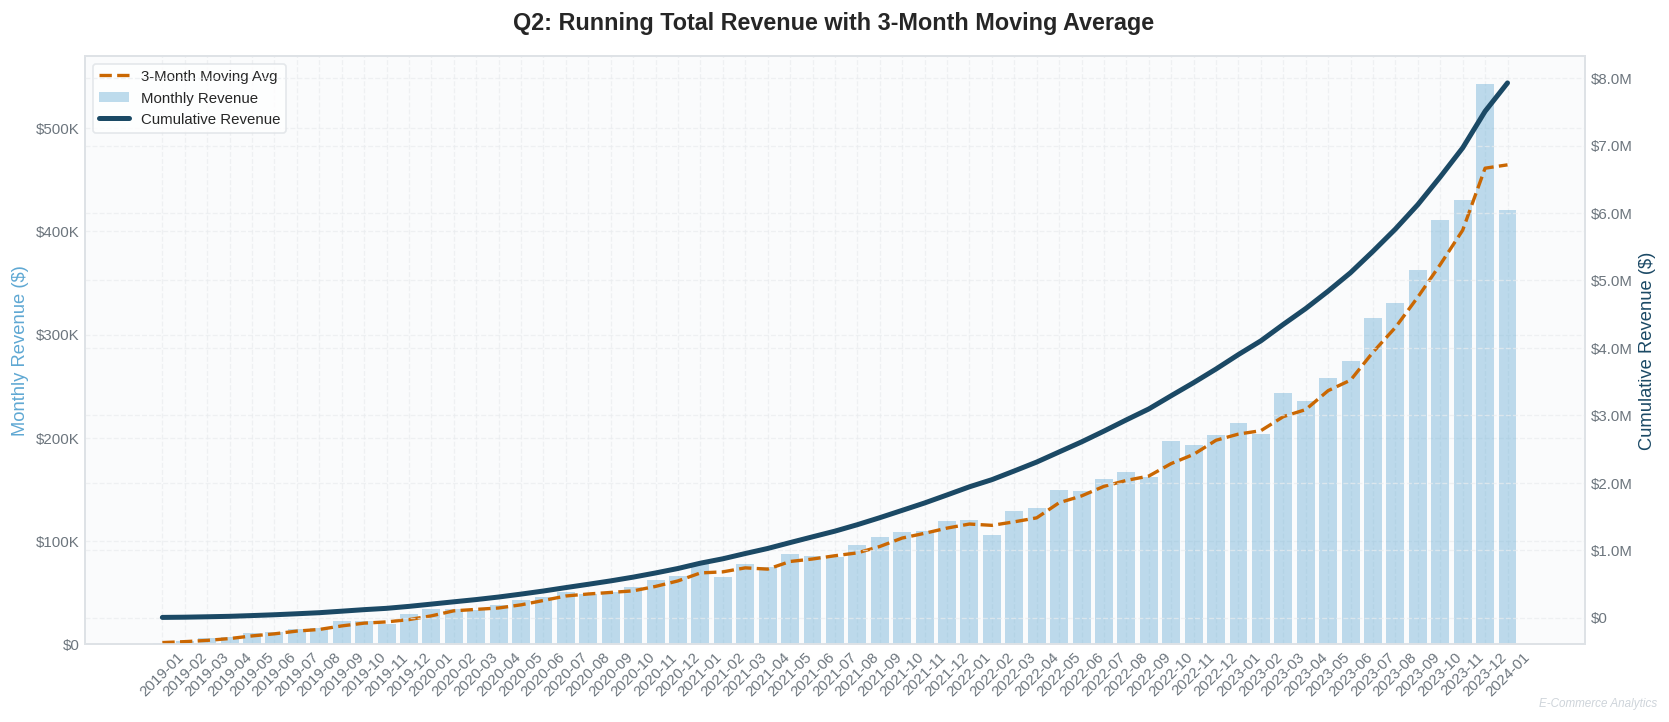

In [6]:
# Q2: RUNNING TOTAL & MOVING AVERAGE
# Business Question: What is the cumulative revenue over time?

# --- Analysis ---
monthly_rev = (df_valid.groupby('year_month')['sale_price']
               .sum().reset_index(name='revenue').sort_values('year_month'))

monthly_rev['running_total'] = monthly_rev['revenue'].cumsum().round(2)
monthly_rev['moving_avg_3m'] = monthly_rev['revenue'].rolling(3, min_periods=1).mean().round(2)
monthly_rev['revenue'] = monthly_rev['revenue'].round(2)

display(style_table(monthly_rev.tail(12), "Q2: Cumulative Revenue & 3-Month Moving Average"))

# --- Visualization ---
fig, ax1 = plt.subplots(figsize=(14, 6))
fig.suptitle('Q2: Running Total Revenue with 3-Month Moving Average',
             fontsize=14, fontweight='bold')

# Monthly revenue bars
ax1.bar(monthly_rev['year_month'], monthly_rev['revenue'],
        color=COLORS['secondary'], alpha=0.4, label='Monthly Revenue', zorder=2)

# Running total line
ax1_twin = ax1.twinx()
ax1_twin.plot(monthly_rev['year_month'], monthly_rev['running_total'],
              color=COLORS['primary'], linewidth=3, label='Cumulative Revenue', zorder=3)

# Moving average
ax1.plot(monthly_rev['year_month'], monthly_rev['moving_avg_3m'],
         color=COLORS['accent'], linewidth=2, linestyle='--',
         label='3-Month Moving Avg', zorder=4)

ax1.set_ylabel('Monthly Revenue ($)', color=COLORS['secondary'])
ax1_twin.set_ylabel('Cumulative Revenue ($)', color=COLORS['primary'])
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax1_twin.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax1.tick_params(axis='x', rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)

plt.tight_layout()
add_watermark(fig)
plt.show()

,year_month,revenue,prev_revenue,mom_growth_pct
49,2023-02,203363.650000,214612.300000,-5.240000
50,2023-03,243450.680000,203363.650000,19.710000
51,2023-04,235181.110000,243450.680000,-3.400000
52,2023-05,258402.760000,235181.110000,9.870000
53,2023-06,273995.970000,258402.760000,6.030000
54,2023-07,316434.330000,273995.970000,15.490000
55,2023-08,330334.930000,316434.330000,4.390000
56,2023-09,362257.050000,330334.930000,9.660000
57,2023-10,411154.370000,362257.050000,13.500000
58,2023-11,429962.240000,411154.370000,4.570000


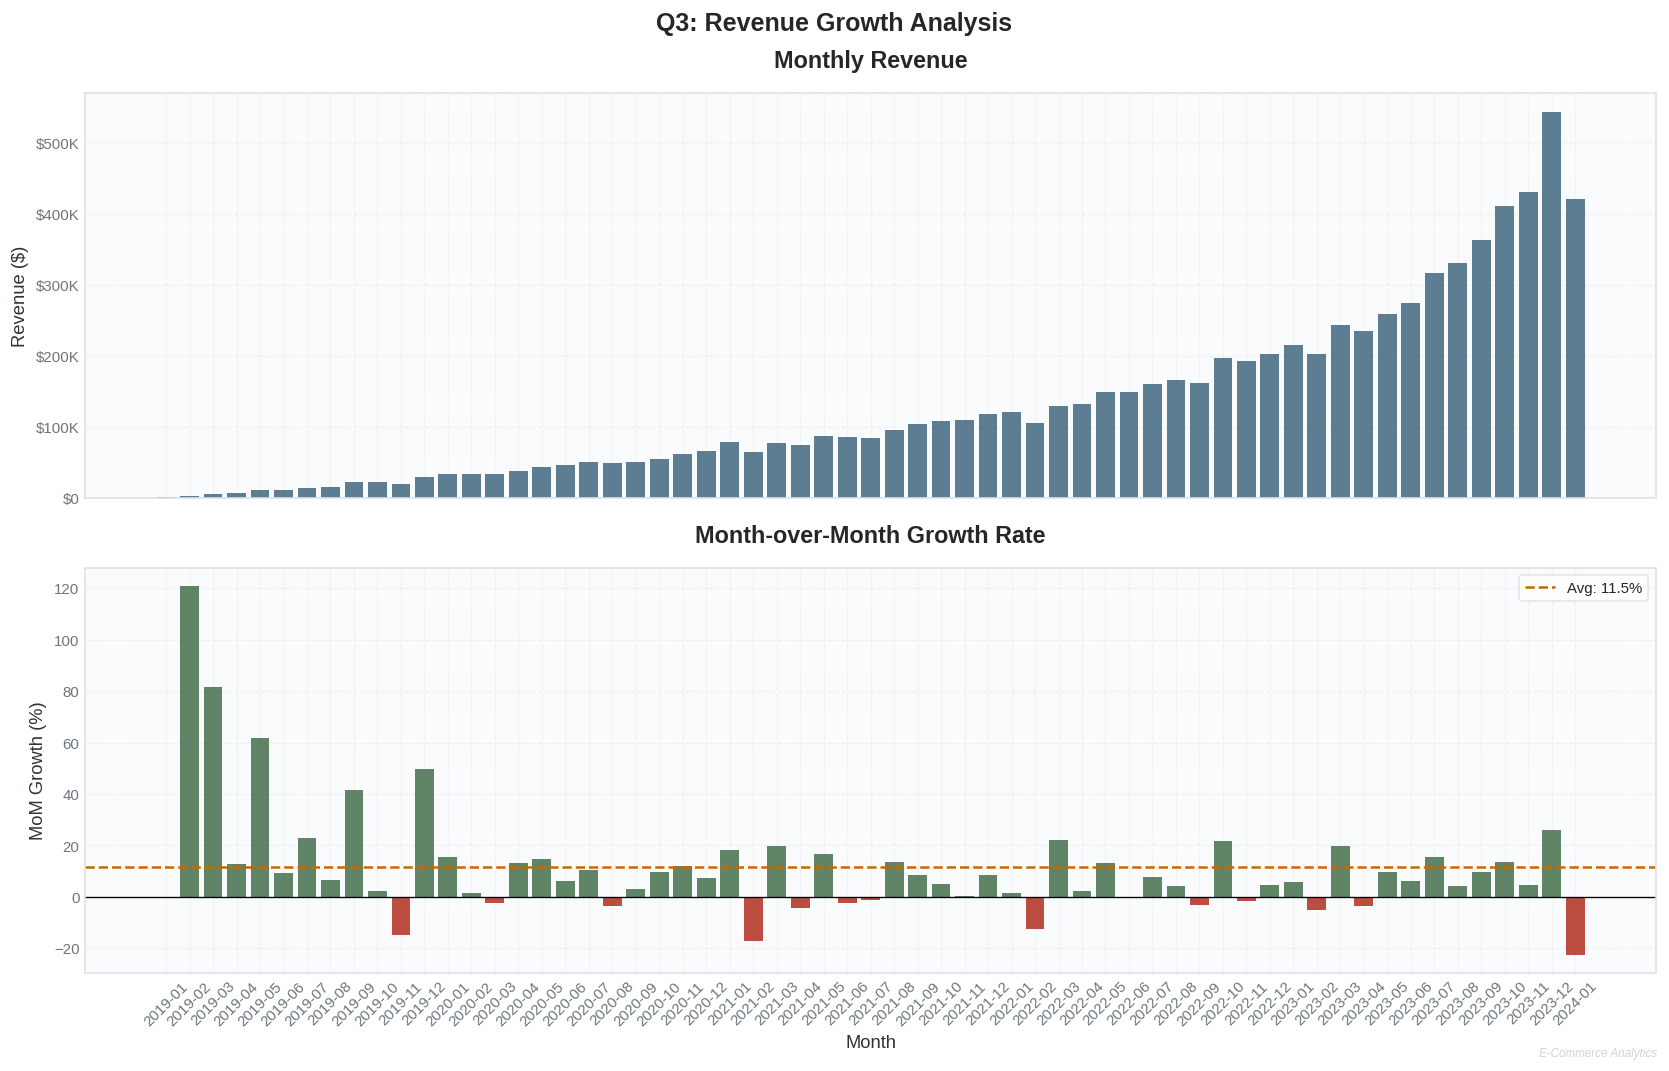

In [7]:
# Q3: MONTH-OVER-MONTH GROWTH RATE
# Business Question: How fast is revenue growing each month?

# --- Analysis ---
q3 = monthly_rev.copy()
q3['prev_revenue'] = q3['revenue'].shift(1)
q3['mom_growth_pct'] = ((q3['revenue'] - q3['prev_revenue']) / q3['prev_revenue'] * 100).round(2)

display(style_table(q3[['year_month', 'revenue', 'prev_revenue', 'mom_growth_pct']].tail(12),
                    "Q3: Month-over-Month Revenue Growth"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Q3: Revenue Growth Analysis', fontsize=15, fontweight='bold')

# Revenue bars
ax1.bar(q3['year_month'], q3['revenue'], color=COLORS['primary'], alpha=0.7)
ax1.set_ylabel('Revenue ($)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax1.set_title('Monthly Revenue')

# Growth rate with color coding
colors_growth = [COLORS['success'] if x >= 0 else COLORS['highlight']
                 for x in q3['mom_growth_pct'].fillna(0)]
ax2.bar(q3['year_month'], q3['mom_growth_pct'].fillna(0), color=colors_growth, alpha=0.8)
ax2.axhline(y=0, color='black', linewidth=0.8)
ax2.axhline(y=q3['mom_growth_pct'].mean(), color=COLORS['accent'],
            linewidth=1.5, linestyle='--', label=f"Avg: {q3['mom_growth_pct'].mean():.1f}%")
ax2.set_ylabel('MoM Growth (%)')
ax2.set_xlabel('Month')
ax2.set_title('Month-over-Month Growth Rate')
ax2.legend()
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
add_watermark(fig)
plt.show()

category,Accessories,Active,Blazers & Jackets,Clothing Sets,Dresses,Fashion Hoodies & Sweatshirts,Intimates,Jeans,Jumpsuits & Rompers,Leggings,Maternity,Outerwear & Coats,Pants,Pants & Capris,Plus,Shorts,Skirts,Sleep & Lounge,Socks,Socks & Hosiery,Suits,Suits & Sport Coats,Sweaters,Swim,Tops & Tees,Underwear
year_month,,,,,,,,,,,,,,,,,,,,,,,,,,
2023-08,227364.000000,246006.000000,152639.000000,9233.000000,246486.000000,342927.000000,244766.000000,674390.000000,21700.000000,44204.000000,145686.000000,690952.000000,229691.000000,96381.000000,91187.000000,271307.000000,61188.000000,289133.000000,65616.000000,34405.000000,61319.000000,350075.000000,447347.000000,346043.000000,263624.000000,107878.000000
2023-09,239400.000000,260344.000000,163626.000000,9750.000000,262698.000000,366498.000000,259927.000000,713862.000000,23218.000000,46858.000000,154639.000000,739336.000000,244235.000000,101643.000000,96570.000000,286831.000000,64701.000000,306332.000000,68918.000000,36103.000000,64715.000000,372141.000000,477263.000000,369941.000000,279727.000000,114527.000000
2023-10,255393.000000,281362.000000,174086.000000,10443.000000,283965.000000,392928.000000,277625.000000,763259.000000,24852.000000,50735.000000,162880.000000,787465.000000,261316.000000,109590.000000,102276.000000,306455.000000,68290.000000,326458.000000,74180.000000,38148.000000,68616.000000,398122.000000,505999.000000,392346.000000,296695.000000,121473.000000
2023-11,272362.000000,297724.000000,185628.000000,11583.000000,302332.000000,418197.000000,296725.000000,812946.000000,26182.000000,54952.000000,172307.000000,838461.000000,277985.000000,118747.000000,108605.000000,327052.000000,73991.000000,348870.000000,78740.000000,40588.000000,74041.000000,421061.000000,539734.000000,418049.000000,317149.000000,130906.000000
2023-12,291940.000000,322583.000000,201543.000000,12159.000000,323980.000000,449994.000000,319881.000000,875826.000000,27804.000000,59740.000000,186212.000000,904475.000000,300662.000000,127321.000000,115763.000000,350595.000000,78829.000000,375458.000000,85032.000000,43641.000000,80519.000000,457405.000000,587190.000000,446968.000000,339521.000000,142553.000000
2024-01,305738.000000,341135.000000,214776.000000,12959.000000,340788.000000,477176.000000,337052.000000,919643.000000,29541.000000,63217.000000,195686.000000,959284.000000,317848.000000,134807.000000,122135.000000,370168.000000,84065.000000,396777.000000,90723.000000,45842.000000,84998.000000,482030.000000,620716.000000,471327.000000,360177.000000,149872.000000


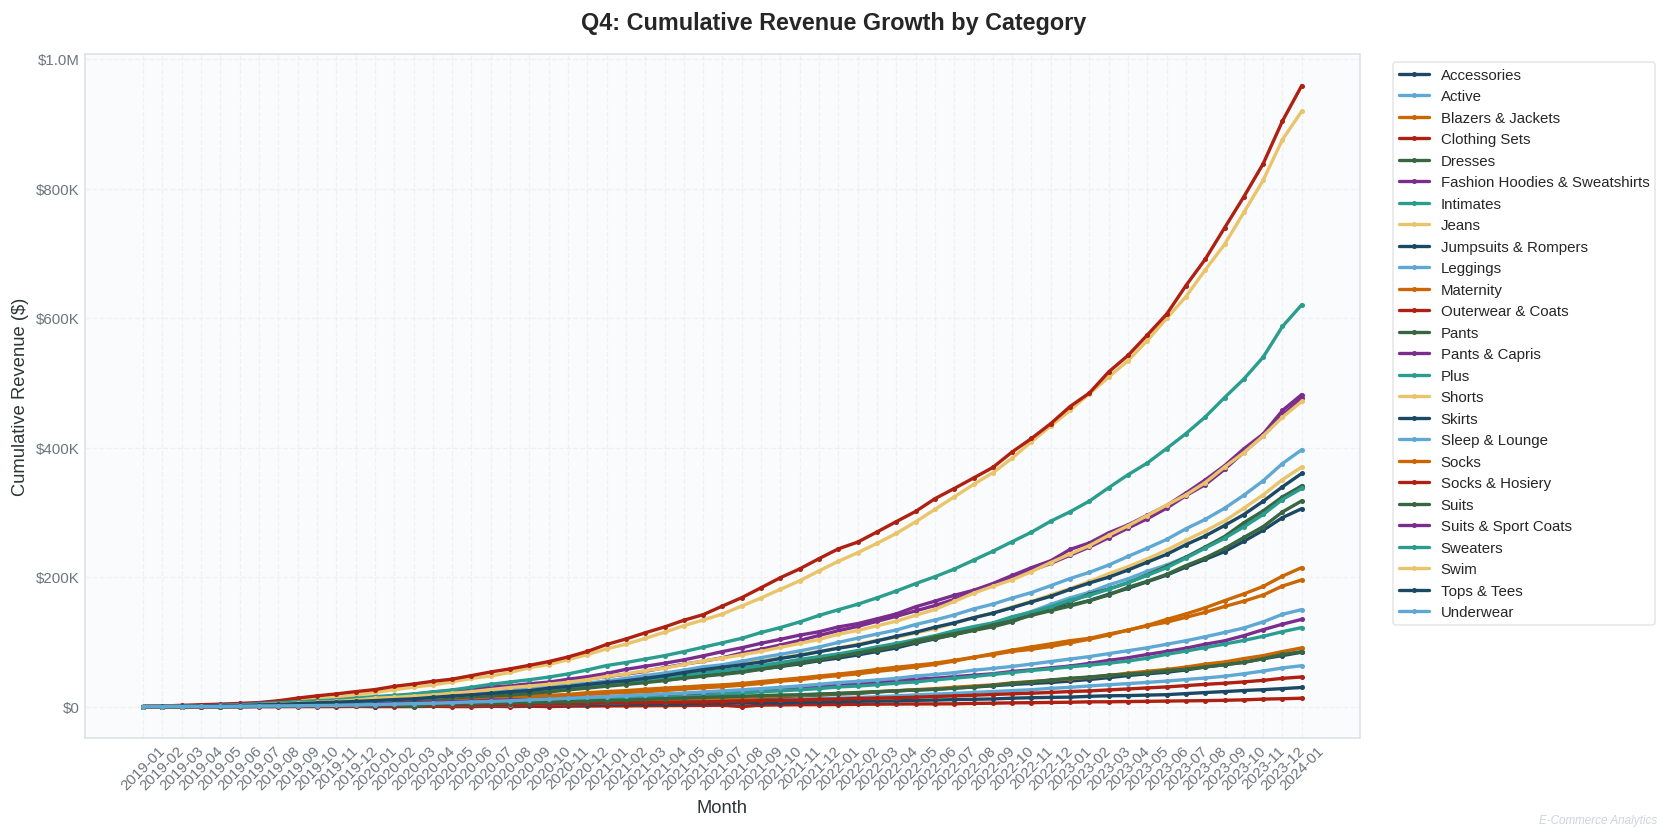

In [8]:
# Q4: CUMULATIVE REVENUE BY CATEGORY
# Business Question: How does each category grow over time?

# --- Analysis ---
cat_monthly = (df_valid.groupby(['category', 'year_month'])['sale_price']
               .sum().reset_index(name='revenue').sort_values(['category', 'year_month']))

cat_monthly['cumulative_revenue'] = (cat_monthly.groupby('category')['revenue']
                                     .cumsum().round(2))

pivot_cum = cat_monthly.pivot(index='year_month', columns='category',
                               values='cumulative_revenue').fillna(0)

display(style_table(pivot_cum.tail(6).round(0), "Q4: Cumulative Revenue by Category (Last 6 Months)"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 7))
fig.suptitle('Q4: Cumulative Revenue Growth by Category', fontsize=14, fontweight='bold')

for i, col in enumerate(pivot_cum.columns):
    ax.plot(pivot_cum.index, pivot_cum[col],
            color=PALETTE_8[i % len(PALETTE_8)], linewidth=2,
            label=col, marker='o', markersize=2)

ax.set_ylabel('Cumulative Revenue ($)')
ax.set_xlabel('Month')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
add_watermark(fig)
plt.show()

,category,revenue,contribution_pct,cumulative_pct
11,Outerwear & Coats,983391.899374,12.100000,12.100000
7,Jeans,941800.611532,11.590000,23.690000
22,Sweaters,637020.430201,7.840000,31.530000
21,Suits & Sport Coats,497929.799460,6.130000,37.660000
5,Fashion Hoodies & Sweatshirts,488461.310351,6.010000,43.670000
23,Swim,483074.140558,5.940000,49.610000
17,Sleep & Lounge,408091.291099,5.020000,54.630000
15,Shorts,378403.491210,4.660000,59.290000
24,Tops & Tees,369301.621208,4.540000,63.830000
4,Dresses,349628.690837,4.300000,68.130000


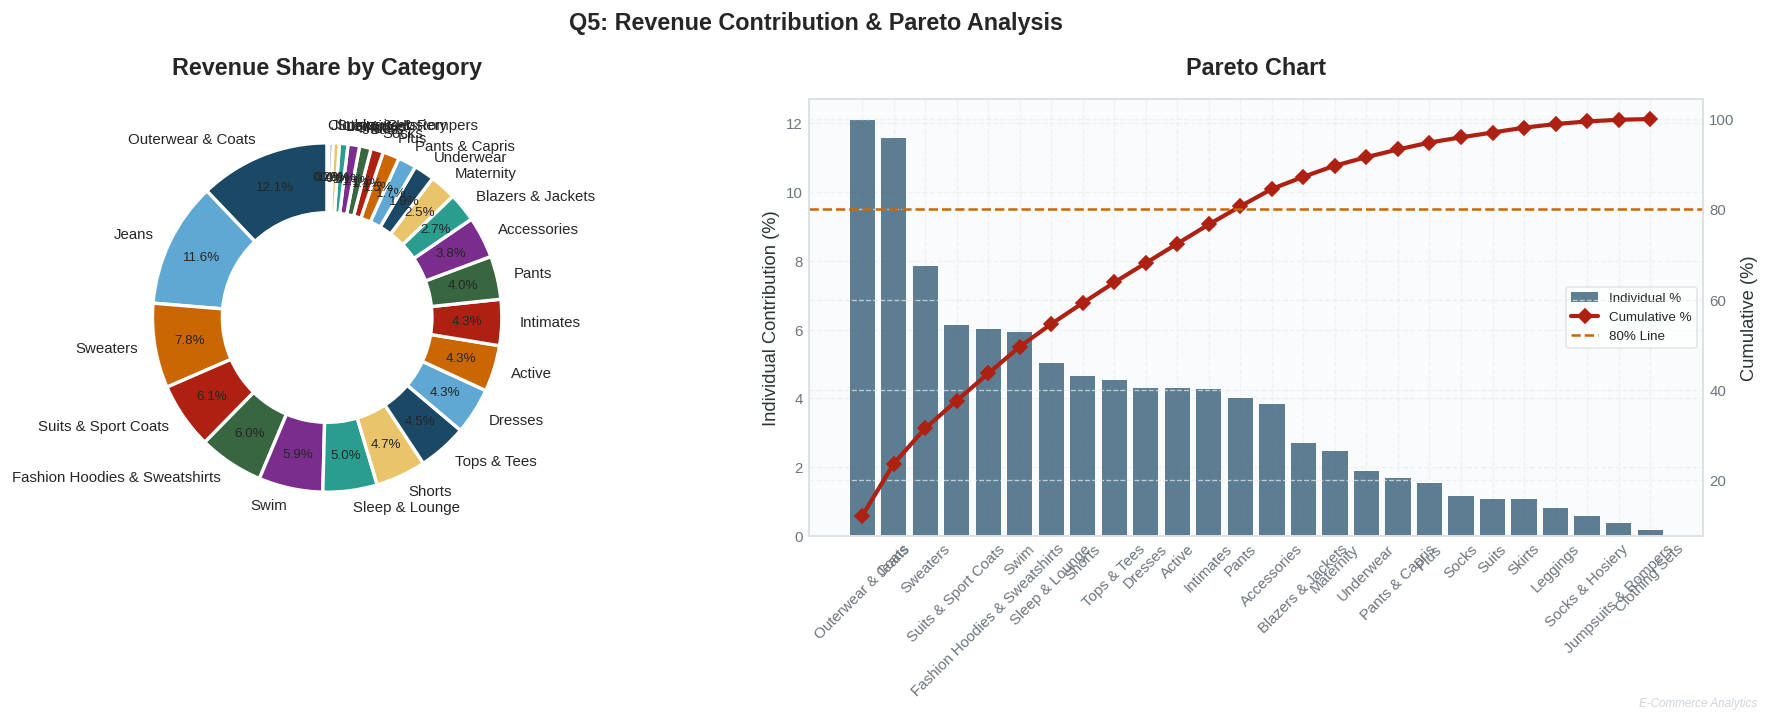

In [9]:
# Q5: REVENUE CONTRIBUTION % BY CATEGORY
# Business Question: Which categories drive the most revenue?

# --- Analysis ---
cat_rev = (df_valid.groupby('category')['sale_price']
           .sum().reset_index(name='revenue')
           .sort_values('revenue', ascending=False))

cat_rev['contribution_pct'] = (cat_rev['revenue'] / cat_rev['revenue'].sum() * 100).round(2)
cat_rev['cumulative_pct'] = cat_rev['contribution_pct'].cumsum().round(2)

display(style_table(cat_rev, "Q5: Revenue Contribution by Category"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Q5: Revenue Contribution & Pareto Analysis', fontsize=14, fontweight='bold')

# Donut chart
wedges, texts, autotexts = ax1.pie(
    cat_rev['revenue'], labels=cat_rev['category'],
    autopct='%1.1f%%', colors=PALETTE_8[:len(cat_rev)],
    startangle=90, pctdistance=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4}
)
for t in autotexts:
    t.set_fontsize(8)
ax1.set_title('Revenue Share by Category')

# Pareto chart
ax2_twin = ax2.twinx()
bars = ax2.bar(cat_rev['category'], cat_rev['contribution_pct'],
               color=COLORS['primary'], alpha=0.7, label='Individual %')
ax2_twin.plot(cat_rev['category'], cat_rev['cumulative_pct'],
              color=COLORS['highlight'], linewidth=2.5, marker='D',
              markersize=6, label='Cumulative %')
ax2_twin.axhline(y=80, color=COLORS['accent'], linestyle='--', linewidth=1.5, label='80% Line')
ax2.set_ylabel('Individual Contribution (%)')
ax2_twin.set_ylabel('Cumulative (%)')
ax2.set_title('Pareto Chart')
ax2.tick_params(axis='x', rotation=45)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=8)

plt.tight_layout()
add_watermark(fig)
plt.show()

## **SECTION 2: CUSTOMER ANALYTICS**

Rows before NaT removal: 136,437
Rows after NaT removal:  133,106
NaT rows removed:        3,331



,M0,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11,M12
cohort,,,,,,,,,,,,,
2019-01,100.000000,nan,nan,nan,nan,nan,nan,nan,7.100000,nan,nan,nan,nan
2019-02,100.000000,6.200000,nan,nan,6.200000,6.200000,6.200000,nan,6.200000,nan,nan,nan,3.100000
2019-03,100.000000,3.100000,nan,1.500000,1.500000,1.500000,1.500000,3.100000,1.500000,nan,7.700000,1.500000,nan
2019-04,100.000000,8.100000,1.400000,1.400000,nan,2.700000,1.400000,nan,1.400000,2.700000,1.400000,1.400000,nan
2019-05,100.000000,4.000000,0.800000,1.600000,0.800000,0.800000,nan,1.600000,1.600000,nan,0.800000,0.800000,nan
2019-06,100.000000,1.400000,2.800000,0.700000,0.700000,0.700000,1.400000,0.700000,1.400000,0.700000,1.400000,0.700000,nan
2019-07,100.000000,2.300000,1.200000,1.200000,nan,1.200000,3.500000,1.200000,0.600000,1.200000,2.300000,0.600000,1.200000
2019-08,100.000000,0.600000,1.200000,0.600000,0.600000,1.200000,1.900000,0.600000,nan,3.100000,1.900000,1.900000,1.900000
2019-09,100.000000,4.100000,2.100000,1.200000,2.100000,0.800000,1.700000,2.100000,0.400000,0.800000,1.700000,3.300000,1.200000


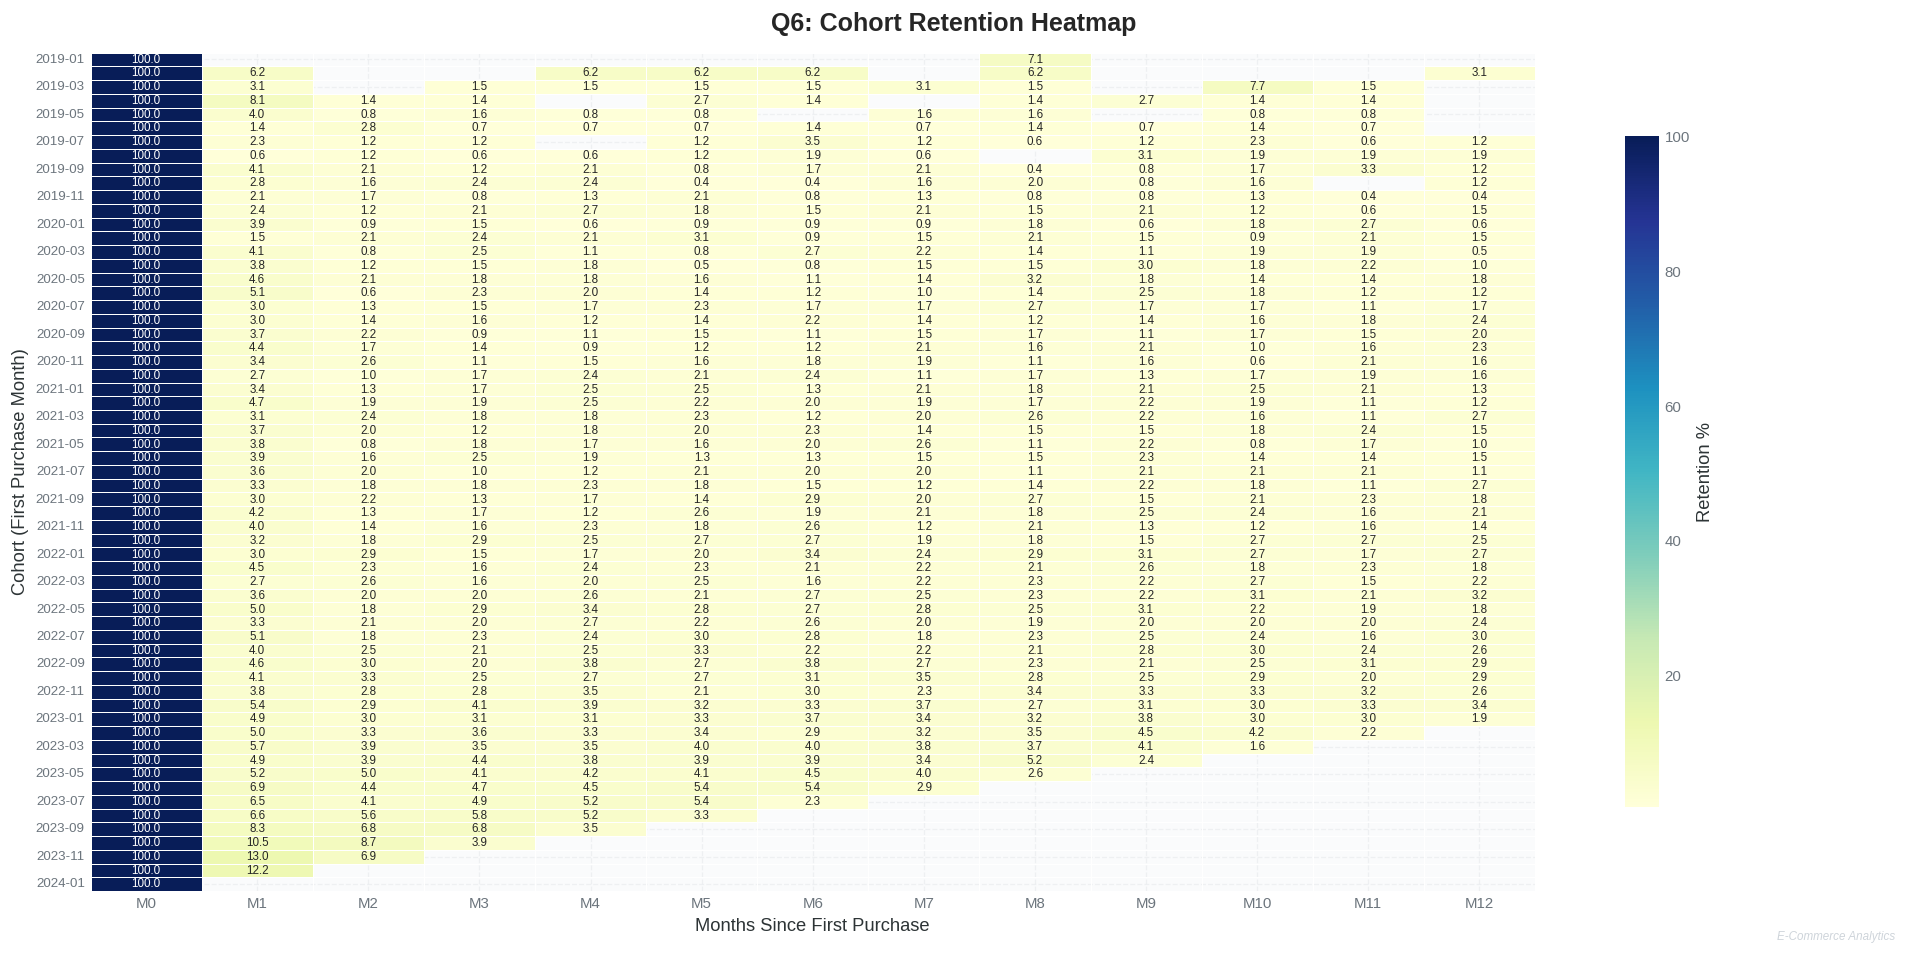

In [11]:
# Q6: COHORT RETENTION ANALYSIS (FIXED)
# Business Question: How well do we retain customers over time?

# --- FIX: Remove rows with missing dates BEFORE analysis ---
df_cohort = df_valid.dropna(subset=['created_at']).copy()
print(f"Rows before NaT removal: {len(df_valid):,}")
print(f"Rows after NaT removal:  {len(df_cohort):,}")
print(f"NaT rows removed:        {len(df_valid) - len(df_cohort):,}\n")

# --- Analysis ---
# Step 1: First purchase month per user
user_first = (df_cohort.groupby('user_id')['created_at']
              .min().dt.to_period('M').reset_index(name='cohort'))

# Step 2: Activity months (unique user-month pairs only)
user_activity = (df_cohort[['user_id', 'created_at']]
                 .drop_duplicates()
                 .copy())
user_activity['activity_month'] = user_activity['created_at'].dt.to_period('M')

# Step 3: Merge and calculate month number
cohort_data = user_activity.merge(user_first, on='user_id')

# --- FIX: Drop any remaining NaT before .n extraction ---
cohort_data = cohort_data.dropna(subset=['activity_month', 'cohort'])

cohort_data['month_number'] = (
    cohort_data['activity_month'] - cohort_data['cohort']
).apply(lambda x: x.n)

# Step 4: Cohort table
cohort_table = (cohort_data.groupby(['cohort', 'month_number'])['user_id']
                .nunique().reset_index(name='users'))

cohort_size = cohort_table[cohort_table['month_number'] == 0][['cohort', 'users']]
cohort_size.columns = ['cohort', 'cohort_size']

cohort_data_full = cohort_table.merge(cohort_size, on='cohort')
cohort_data_full['retention_pct'] = (
    cohort_data_full['users'] / cohort_data_full['cohort_size'] * 100
).round(1)

# Pivot for heatmap
cohort_pivot = cohort_data_full.pivot(
    index='cohort', columns='month_number', values='retention_pct'
)
cohort_pivot = cohort_pivot.iloc[:, :13]  # First 12 months

# Convert index to string for cleaner display
cohort_pivot.index = cohort_pivot.index.astype(str)
cohort_pivot.columns = [f"M{int(c)}" for c in cohort_pivot.columns]

display(style_table(
    cohort_pivot.round(1).head(10),
    "Q6: Cohort Retention (%) — First 10 Cohorts"
))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(16, 8))
fig.suptitle('Q6: Cohort Retention Heatmap', fontsize=15, fontweight='bold')

sns.heatmap(
    cohort_pivot,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar_kws={'label': 'Retention %', 'shrink': 0.8},
    annot_kws={'size': 7}
)

ax.set_xlabel('Months Since First Purchase', fontsize=11)
ax.set_ylabel('Cohort (First Purchase Month)', fontsize=11)
ax.set_title('')
ax.tick_params(axis='y', labelsize=8)

plt.tight_layout()
add_watermark(fig)
plt.show()

,user_id,total_orders,total_spent,avg_order_value,lifespan_days,projected_clv_2yr,clv_quintile
38880,58623,2,1021.000000,510.500000,0.000000,745330.000000,Q5-High
13604,20434,1,999.000000,999.000000,0.000000,729270.000000,Q5-High
39708,59868,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
40138,60511,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
41299,62285,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
41294,62277,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
61435,92737,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
61541,92908,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
36141,54555,1,903.000000,903.000000,0.000000,659190.000000,Q5-High
43390,65455,1,903.000000,903.000000,0.000000,659190.000000,Q5-High


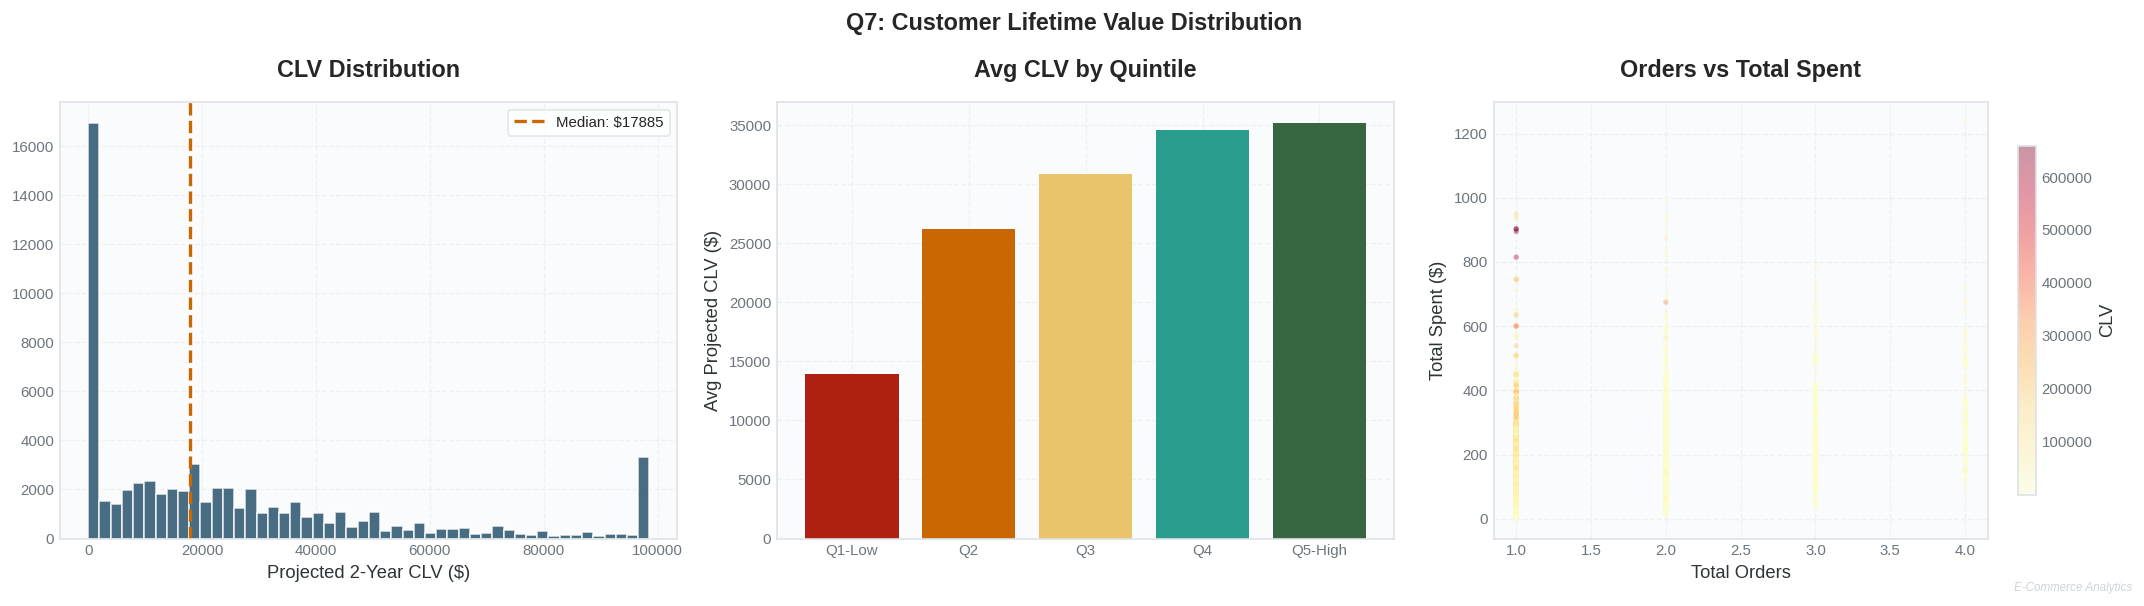

In [12]:
# Q7: CUSTOMER LIFETIME VALUE
# Business Question: What is each customer's projected value?

# --- Analysis ---
clv = (df_valid.groupby('user_id')
       .agg(
           total_orders=('order_id', 'nunique'),
           total_spent=('sale_price', 'sum'),
           avg_order_value=('sale_price', 'mean'),
           first_purchase=('created_at', 'min'),
           last_purchase=('created_at', 'max')
       ).reset_index())

clv['lifespan_days'] = (clv['last_purchase'] - clv['first_purchase']).dt.days
clv['purchase_freq'] = clv['total_orders'] / clv['lifespan_days'].clip(lower=1) * 365
clv['projected_clv_2yr'] = (clv['avg_order_value'] * clv['purchase_freq'] * 2).round(2)
clv['clv_quintile'] = pd.qcut(clv['total_spent'], 5, labels=['Q1-Low', 'Q2', 'Q3', 'Q4', 'Q5-High'])

clv_display = clv[['user_id', 'total_orders', 'total_spent', 'avg_order_value',
                    'lifespan_days', 'projected_clv_2yr', 'clv_quintile']].round(2)

display(style_table(clv_display.sort_values('projected_clv_2yr', ascending=False).head(10),
                    "Q7: Top 10 Customers by Projected CLV"))

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Q7: Customer Lifetime Value Distribution', fontsize=14, fontweight='bold')

# CLV Distribution
axes[0].hist(clv['projected_clv_2yr'].clip(upper=clv['projected_clv_2yr'].quantile(0.95)),
             bins=50, color=COLORS['primary'], edgecolor='white', alpha=0.8)
axes[0].axvline(clv['projected_clv_2yr'].median(), color=COLORS['accent'],
                linewidth=2, linestyle='--', label=f"Median: ${clv['projected_clv_2yr'].median():.0f}")
axes[0].set_title('CLV Distribution')
axes[0].set_xlabel('Projected 2-Year CLV ($)')
axes[0].legend()

# CLV by Quintile
quintile_clv = clv.groupby('clv_quintile', observed=True)['projected_clv_2yr'].mean()
axes[1].bar(quintile_clv.index.astype(str), quintile_clv.values,
            color=[COLORS['highlight'], COLORS['accent'], COLORS['gold'],
                   COLORS['teal'], COLORS['success']])
axes[1].set_title('Avg CLV by Quintile')
axes[1].set_ylabel('Avg Projected CLV ($)')

# Orders vs Spend scatter
sample = clv.sample(min(5000, len(clv)), random_state=42)
scatter = axes[2].scatter(sample['total_orders'], sample['total_spent'],
                          c=sample['projected_clv_2yr'], cmap='YlOrRd',
                          alpha=0.4, s=10, edgecolors='none')
axes[2].set_title('Orders vs Total Spent')
axes[2].set_xlabel('Total Orders')
axes[2].set_ylabel('Total Spent ($)')
plt.colorbar(scatter, ax=axes[2], label='CLV', shrink=0.8)

plt.tight_layout()
add_watermark(fig)
plt.show()

,count,avg_monetary
segment,,
At Risk,13911,127.370000
Other,12873,121.610000
Champion,12609,190.740000
Lost,11907,84.880000
New Customer,8812,88.380000
Loyal,4537,87.440000


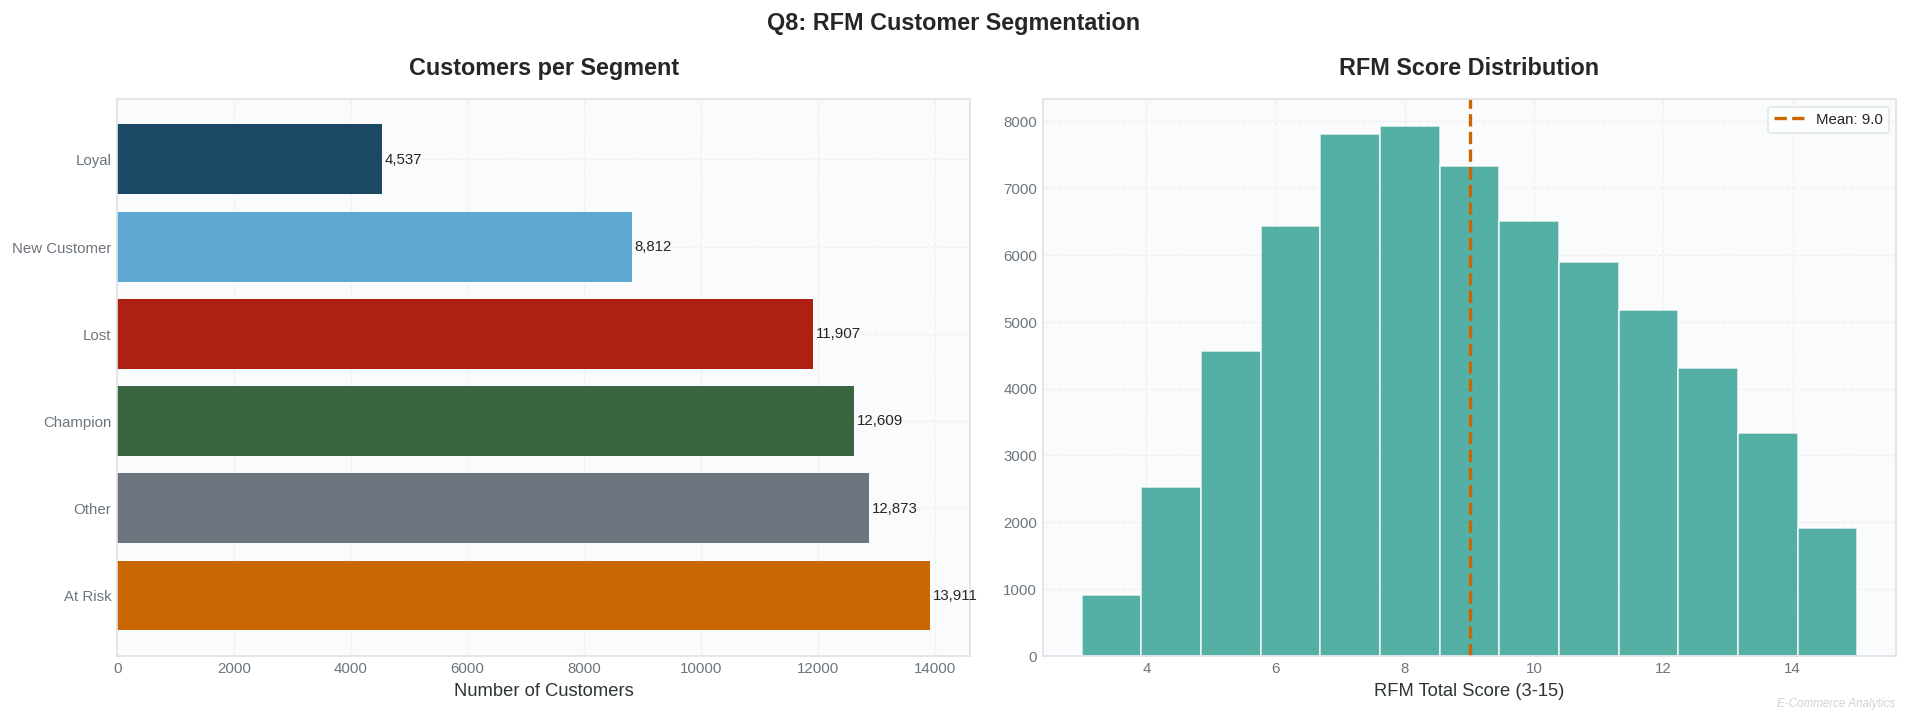

In [14]:

# Q8: RFM SEGMENTATION (FIXED)
# Business Question: How to segment customers by behavior?

# --- Analysis ---
reference_date = df_valid['created_at'].max()

rfm = (df_valid.groupby('user_id')
       .agg(
           recency=('created_at', lambda x: (reference_date - x.max()).days),
           frequency=('order_id', 'nunique'),
           monetary=('sale_price', 'sum')
       ).reset_index())

# --- FIX 1: Drop rows with NaN recency ---
rfm = rfm.dropna(subset=['recency', 'frequency', 'monetary']).copy()

# --- FIX 2: Use duplicates='drop' to handle identical values ---
# --- FIX 3: Fill any remaining NaN scores before astype(int) ---

rfm['R_score'] = (
    pd.qcut(rfm['recency'], q=5, labels=[5, 4, 3, 2, 1], duplicates='drop')
    .astype(float)          # NaN safe
    .fillna(3)              # assign middle score to edge cases
    .astype(int)
)

rfm['F_score'] = (
    pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5], duplicates='drop')
    .astype(float)
    .fillna(3)
    .astype(int)
)

rfm['M_score'] = (
    pd.qcut(rfm['monetary'], q=5, labels=[1, 2, 3, 4, 5], duplicates='drop')
    .astype(float)
    .fillna(3)
    .astype(int)
)

rfm['RFM_total'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']

def segment_rfm(row):
    if row['R_score'] >= 4 and row['F_score'] >= 4: return 'Champion'
    if row['R_score'] >= 4 and row['F_score'] >= 3: return 'Loyal'
    if row['R_score'] >= 4 and row['F_score'] <= 2: return 'New Customer'
    if row['R_score'] <= 2 and row['F_score'] >= 3: return 'At Risk'
    if row['R_score'] <= 2 and row['F_score'] <= 2: return 'Lost'
    return 'Other'

rfm['segment'] = rfm.apply(segment_rfm, axis=1)

seg_summary = (rfm.groupby('segment')
               .agg(count=('user_id', 'count'), avg_monetary=('monetary', 'mean'))
               .round(2).sort_values('count', ascending=False))

display(style_table(seg_summary, "Q8: RFM Customer Segments"))

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Q8: RFM Customer Segmentation', fontsize=14, fontweight='bold')

# Segment distribution
seg_colors = {'Champion': COLORS['success'], 'Loyal': COLORS['primary'],
              'New Customer': COLORS['secondary'], 'At Risk': COLORS['accent'],
              'Lost': COLORS['highlight'], 'Other': COLORS['neutral']}
colors_list = [seg_colors.get(s, COLORS['neutral']) for s in seg_summary.index]

axes[0].barh(seg_summary.index, seg_summary['count'], color=colors_list)
axes[0].set_title('Customers per Segment')
axes[0].set_xlabel('Number of Customers')
for i, v in enumerate(seg_summary['count']):
    axes[0].text(v + 50, i, f'{v:,}', va='center', fontsize=9)

# RFM Score Distribution
axes[1].hist(rfm['RFM_total'], bins=13, color=COLORS['teal'],
             edgecolor='white', alpha=0.8)
axes[1].axvline(rfm['RFM_total'].mean(), color=COLORS['accent'],
                linewidth=2, linestyle='--', label=f"Mean: {rfm['RFM_total'].mean():.1f}")
axes[1].set_title('RFM Score Distribution')
axes[1].set_xlabel('RFM Total Score (3-15)')
axes[1].legend()

plt.tight_layout()
add_watermark(fig)
plt.show()

,customer_type,customer_count,pct
0,One-Time,45808,69.140000
1,Repeat (2-3),18865,28.470000
2,Loyal (4-6),1581,2.390000


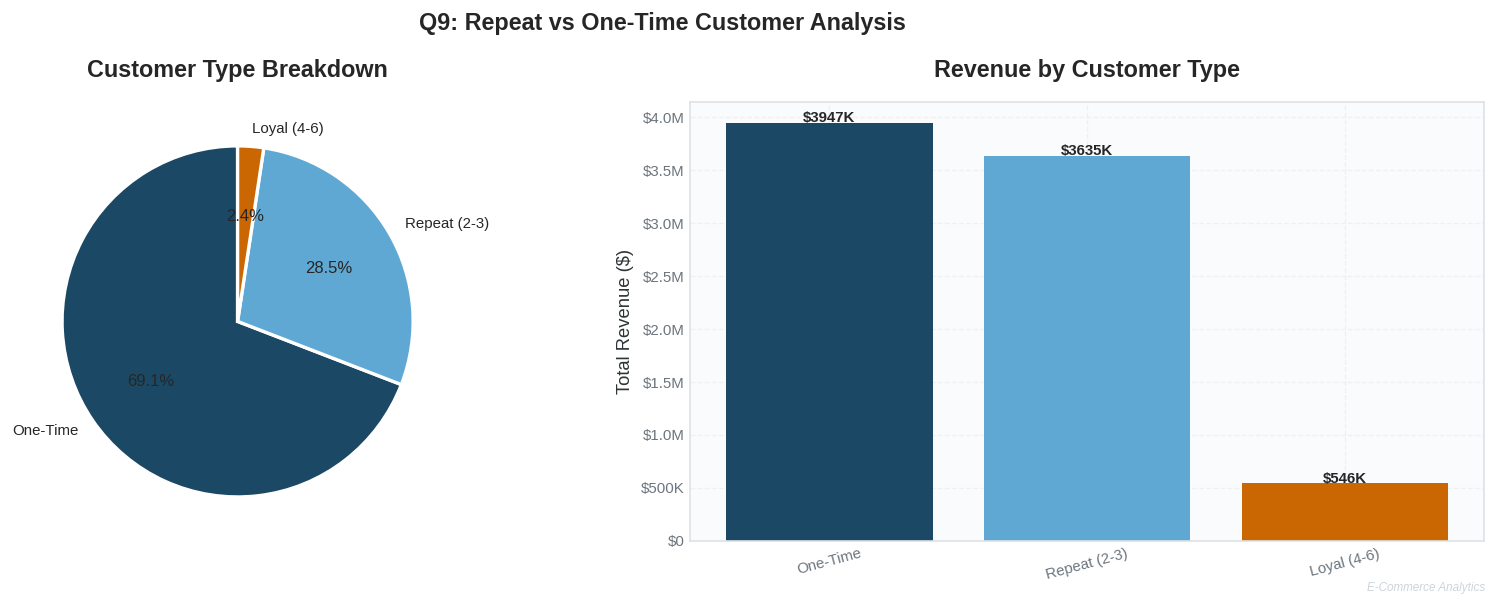

In [15]:
# Q9: REPEAT VS ONE-TIME CUSTOMERS
# Business Question: What % of customers come back?

# --- Analysis ---
cust_orders = df_valid.groupby('user_id')['order_id'].nunique().reset_index(name='order_count')

cust_orders['customer_type'] = pd.cut(
    cust_orders['order_count'],
    bins=[0, 1, 3, 6, float('inf')],
    labels=['One-Time', 'Repeat (2-3)', 'Loyal (4-6)', 'VIP (7+)']
)

q9 = (cust_orders.groupby('customer_type', observed=True)
      .agg(customer_count=('user_id', 'count'))
      .reset_index())
q9['pct'] = (q9['customer_count'] / q9['customer_count'].sum() * 100).round(2)

display(style_table(q9, "Q9: Customer Type Distribution"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Q9: Repeat vs One-Time Customer Analysis', fontsize=14, fontweight='bold')

# Pie
ax1.pie(q9['customer_count'], labels=q9['customer_type'],
        autopct='%1.1f%%', colors=PALETTE_8[:4],
        startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax1.set_title('Customer Type Breakdown')

# Revenue contribution by type
type_rev = (df_valid.merge(cust_orders[['user_id', 'customer_type']], on='user_id')
            .groupby('customer_type', observed=True)['sale_price'].sum())
bars = ax2.bar(type_rev.index.astype(str), type_rev.values, color=PALETTE_8[:4])
ax2.set_title('Revenue by Customer Type')
ax2.set_ylabel('Total Revenue ($)')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax2.tick_params(axis='x', rotation=15)
for bar, val in zip(bars, type_rev.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
             f'${val/1000:.0f}K', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
add_watermark(fig)
plt.show()

,churn_status,customers,avg_spend,pct
0,Active,6058,146.720000,9.400000
1,Warm,8802,137.010000,13.600000
2,Cold,9236,133.760000,14.300000
3,Churned,40553,113.390000,62.700000


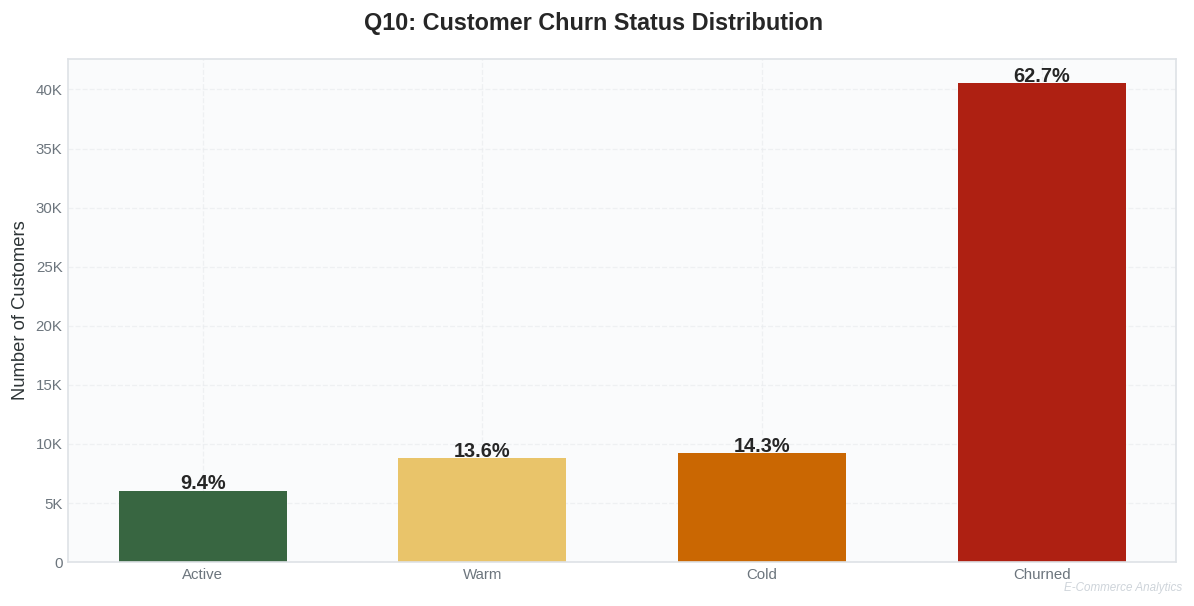

In [16]:
# Q10: CHURN IDENTIFICATION
# Business Question: Which customers are at risk of churning?

# --- Analysis ---
last_purchase = (df_valid.groupby('user_id')
                 .agg(
                     last_purchase_date=('created_at', 'max'),
                     total_orders=('order_id', 'nunique'),
                     total_spent=('sale_price', 'sum')
                 ).reset_index())

last_purchase['days_since'] = (reference_date - last_purchase['last_purchase_date']).dt.days

last_purchase['churn_status'] = pd.cut(
    last_purchase['days_since'],
    bins=[-1, 30, 90, 180, float('inf')],
    labels=['Active', 'Warm', 'Cold', 'Churned']
)

q10 = (last_purchase.groupby('churn_status', observed=True)
       .agg(customers=('user_id', 'count'), avg_spend=('total_spent', 'mean'))
       .round(2).reset_index())
q10['pct'] = (q10['customers'] / q10['customers'].sum() * 100).round(1)

display(style_table(q10, "Q10: Customer Churn Status"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Q10: Customer Churn Status Distribution', fontsize=14, fontweight='bold')

churn_colors = {'Active': COLORS['success'], 'Warm': COLORS['gold'],
                'Cold': COLORS['accent'], 'Churned': COLORS['highlight']}
colors = [churn_colors[s] for s in q10['churn_status']]

bars = ax.bar(q10['churn_status'].astype(str), q10['customers'], color=colors, width=0.6)
for bar, pct in zip(bars, q10['pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{pct}%', ha='center', fontsize=12, fontweight='bold')

ax.set_ylabel('Number of Customers')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_number))

plt.tight_layout()
add_watermark(fig)
plt.show()

## **SECTION 3: PRODUCT ANALYTICS**

,category,name,revenue,units_sold,rank
348,Accessories,DOLCE & GABBANA DG4167 501/8G BLACK GRAY GRADIENT 5917,2916.000000,12,1.000000
902,Accessories,Oakley Men's Racing Jacket Oval Sunglasses,2560.000000,10,2.000000
1257,Accessories,Tom Ford Marko FT0144 Sunglasses - 18V Shiny Rhodium (Blue Lens) - 58mm,2379.100000,8,3.000000
1601,Active,Canada Goose Women's Solaris,9730.000000,14,1.000000
2588,Active,The North Face Apex Bionic Soft Shell Jacket - Men's,8127.000000,9,2.000000
1600,Active,Canada Goose Women's Mystique,6000.000000,8,3.000000
3064,Blazers & Jackets,BCBGMAXAZRIA Women's Bowie Tuxedo Jacket,3679.920000,18,1.000000
3225,Blazers & Jackets,McGinn Women's Sasha Tweed Jacket,3575.000000,11,2.000000
3226,Blazers & Jackets,MiH Jeans Women's Aztec Jacket,2970.000000,6,3.000000
3424,Clothing Sets,Ulla Popken Plus Size Floral 3-Piece Pant Set,1521.000000,9,1.000000


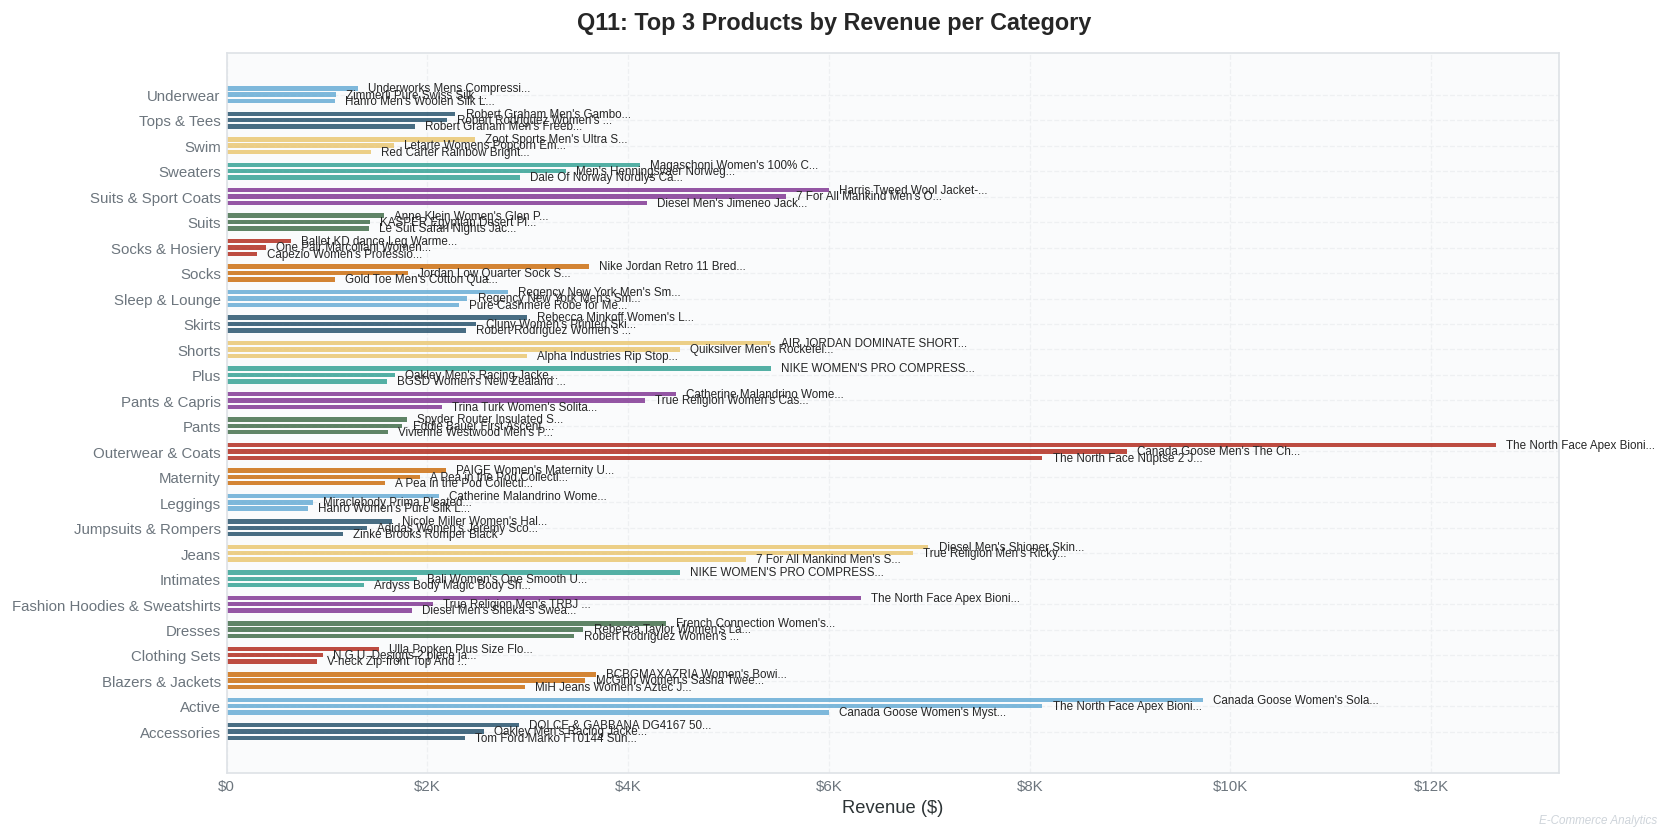

In [17]:
# Q11: TOP 3 PRODUCTS PER CATEGORY
# Business Question: Which products lead each category?

# --- Analysis ---
prod_rev = (df_valid.groupby(['category', 'name'])
            .agg(revenue=('sale_price', 'sum'), units_sold=('id', 'count'))
            .reset_index())

prod_rev['rank'] = prod_rev.groupby('category')['revenue'].rank(ascending=False, method='dense')
top3 = prod_rev[prod_rev['rank'] <= 3].sort_values(['category', 'rank'])
top3['revenue'] = top3['revenue'].round(2)

display(style_table(top3[['category', 'name', 'revenue', 'units_sold', 'rank']].head(15),
                    "Q11: Top 3 Products per Category"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 7))
fig.suptitle('Q11: Top 3 Products by Revenue per Category', fontsize=14, fontweight='bold')

categories = top3['category'].unique()
for i, cat in enumerate(categories):
    cat_data = top3[top3['category'] == cat].sort_values('revenue')
    y_pos = [i * 4 + j for j in range(len(cat_data))]
    bars = ax.barh(y_pos, cat_data['revenue'],
                   color=PALETTE_8[i % len(PALETTE_8)], alpha=0.8, height=0.7)
    for bar, name in zip(bars, cat_data['name']):
        short_name = name[:25] + '...' if len(name) > 25 else name
        ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
                short_name, va='center', fontsize=7)

ax.set_yticks([i * 4 + 1 for i in range(len(categories))])
ax.set_yticklabels(categories)
ax.set_xlabel('Revenue ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))

plt.tight_layout()
add_watermark(fig)
plt.show()

,category_a,category_b,times_together
153,Jeans,Tops & Tees,566
103,Fashion Hoodies & Sweatshirts,Jeans,538
120,Fashion Hoodies & Sweatshirts,Tops & Tees,528
144,Jeans,Shorts,525
146,Jeans,Sleep & Lounge,523
271,Sweaters,Tops & Tees,515
151,Jeans,Sweaters,504
152,Jeans,Swim,501
86,Dresses,Intimates,500
119,Fashion Hoodies & Sweatshirts,Swim,493


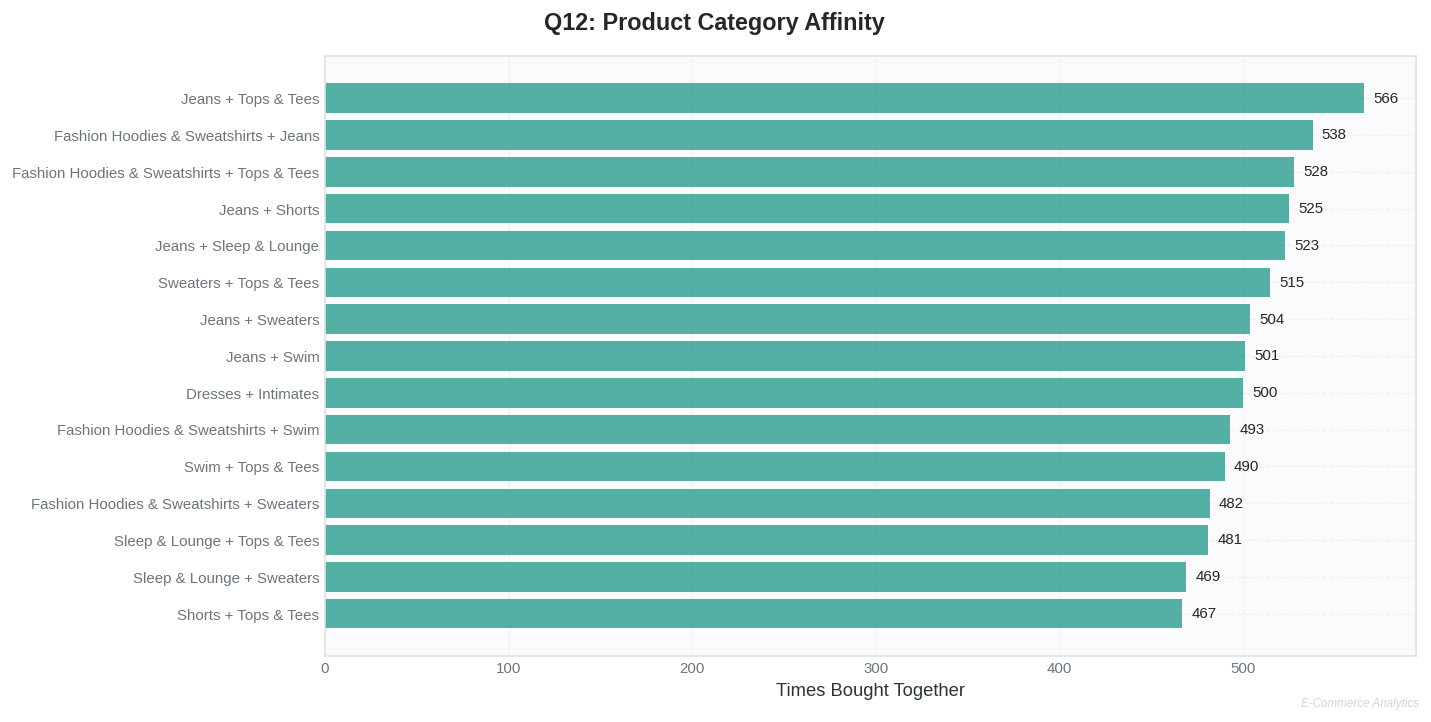

In [18]:

# Q12: PRODUCT AFFINITY ANALYSIS
# Business Question: Which products are frequently bought together?

# --- Analysis ---
order_cats = (df_valid[['order_id', 'category']].drop_duplicates())

# Self-join on order_id
pairs = order_cats.merge(order_cats, on='order_id', suffixes=('_a', '_b'))
pairs = pairs[pairs['category_a'] < pairs['category_b']]

affinity = (pairs.groupby(['category_a', 'category_b'])
            .size().reset_index(name='times_together')
            .sort_values('times_together', ascending=False).head(15))

display(style_table(affinity, "Q12: Top Product Category Pairs Bought Together"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(12, 6))
fig.suptitle('Q12: Product Category Affinity', fontsize=14, fontweight='bold')

affinity['label'] = affinity['category_a'] + ' + ' + affinity['category_b']
bars = ax.barh(affinity['label'].iloc[::-1], affinity['times_together'].iloc[::-1],
               color=COLORS['teal'], alpha=0.8)
ax.set_xlabel('Times Bought Together')
for bar, val in zip(bars, affinity['times_together'].iloc[::-1]):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=9)

plt.tight_layout()
add_watermark(fig)
plt.show()

,product_category,product_name,total_stock,sold_count,unsold_pct,avg_days_to_sell
11350,Maternity,Fit2BMom Women's Maternity Bliss Yoga Capri Pant,20,3,85.000000,28.300000
25445,Swim,Womens Delta Burke Plus Size Tankini Swimsuit Skirtini Swimwear Black/White or Purple/Turq/Black 18-24,13,2,84.600000,38.500000
4293,Dresses,Trina Turk Women's Inga Dress,17,3,82.400000,28.700000
13014,Outerwear & Coats,Polo Ralph Lauren Men's Perry Jacket Coat,17,3,82.400000,26.700000
3915,Dresses,Jax Women's Lace Dress With Cap Sleeve,11,2,81.800000,16.000000
24913,Swim,Rip Curl Women's Love and Surf Cross Back Top,11,2,81.800000,24.000000
23207,Sweaters,Plus Long Two Pocket Sweater Cardigan,11,2,81.800000,40.500000
12212,Outerwear & Coats,Carhartt Men's Big-Tall Sandstone Hooded Active Vest Quilt Lined,11,2,81.800000,42.000000
6048,Fashion Hoodies & Sweatshirts,Volcom Juniors Carpel Basic Hoodie,11,2,81.800000,7.000000
26132,Tops & Tees,Eddie Bauer Relaxed Fit Wrinkle-Free Oxford Cloth Shirt - Pattern,11,2,81.800000,32.500000


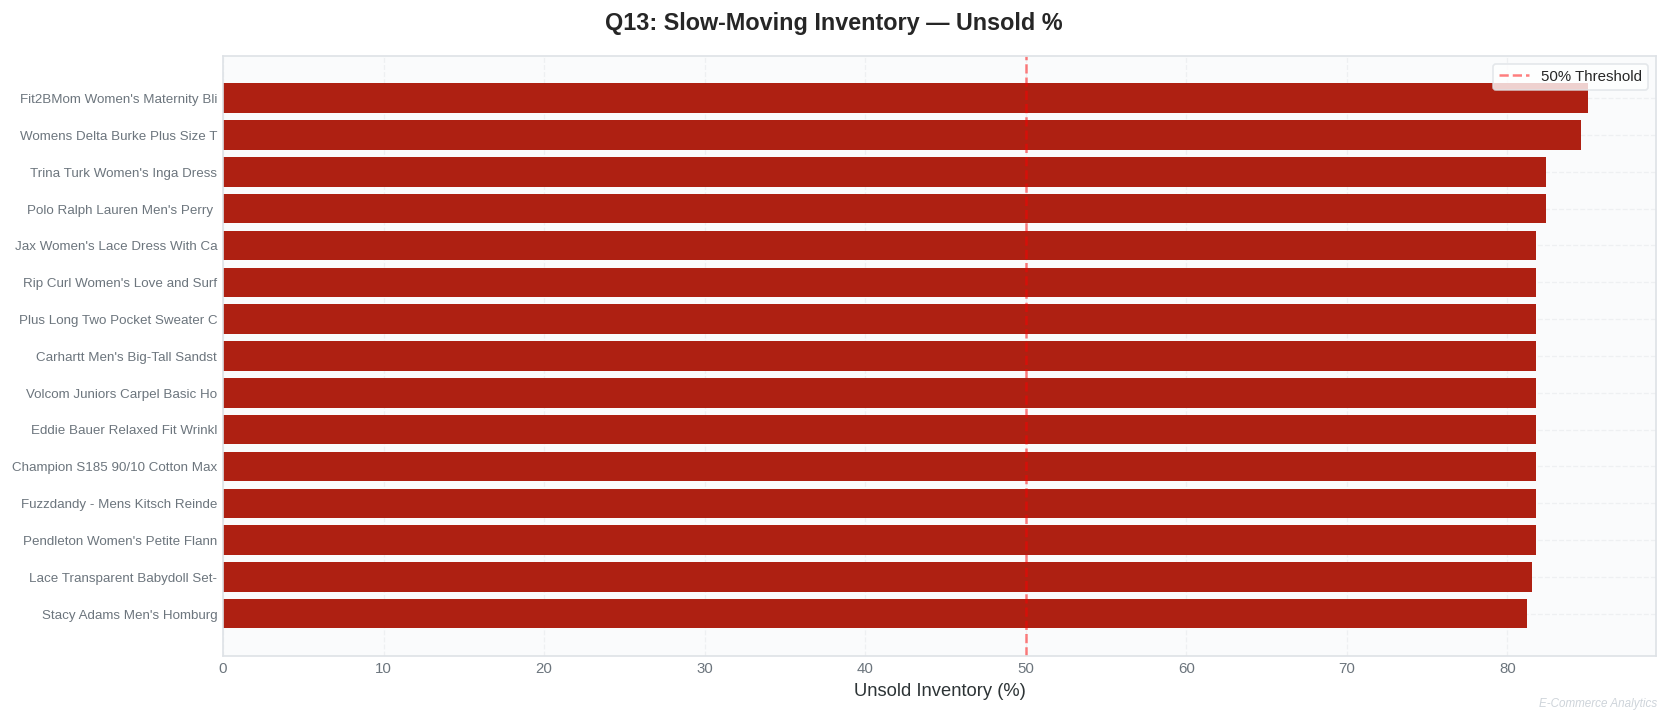

In [19]:
# Q13: SLOW-MOVING INVENTORY
# Business Question: Which products are not selling?

# --- Analysis ---
inv = inventory.copy()
inv['is_sold'] = inv['sold_at'].notna()
inv['days_to_sell'] = (inv['sold_at'] - inv['created_at']).dt.days

q13 = (inv.groupby(['product_category', 'product_name'])
       .agg(
           total_stock=('id', 'count'),
           sold_count=('is_sold', 'sum'),
           avg_days_to_sell=('days_to_sell', 'mean')
       ).reset_index())

q13['unsold_count'] = q13['total_stock'] - q13['sold_count']
q13['unsold_pct'] = (q13['unsold_count'] / q13['total_stock'] * 100).round(1)
q13 = q13[q13['total_stock'] >= 10].sort_values('unsold_pct', ascending=False).head(15)

display(style_table(q13[['product_category', 'product_name', 'total_stock',
                         'sold_count', 'unsold_pct', 'avg_days_to_sell']].round(1),
                    "Q13: Slow-Moving Inventory (Top 15)"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 6))
fig.suptitle('Q13: Slow-Moving Inventory — Unsold %', fontsize=14, fontweight='bold')

colors_inv = [COLORS['highlight'] if x > 70 else COLORS['accent'] if x > 40 else COLORS['success']
              for x in q13['unsold_pct']]
bars = ax.barh(range(len(q13)), q13['unsold_pct'], color=colors_inv)
ax.set_yticks(range(len(q13)))
ax.set_yticklabels([n[:30] for n in q13['product_name']], fontsize=8)
ax.set_xlabel('Unsold Inventory (%)')
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% Threshold')
ax.legend()
ax.invert_yaxis()

plt.tight_layout()
add_watermark(fig)
plt.show()

,category,price_bracket,units_sold,avg_price,total_revenue
0,Accessories,Under $20,3145,11.930000,37522.950000
1,Accessories,$20-50,2362,30.790000,72727.920000
2,Accessories,$50-100,889,77.420000,68825.160000
3,Accessories,$100-200,773,138.920000,107381.770000
4,Accessories,$200+,108,243.170000,26262.190000
5,Active,Under $20,1468,14.760000,21660.520000
6,Active,$20-50,3415,33.540000,114551.860000
7,Active,$50-100,1410,68.710000,96883.100000
8,Active,$100-200,356,132.690000,47237.700000
9,Active,$200+,149,457.930000,68230.980000


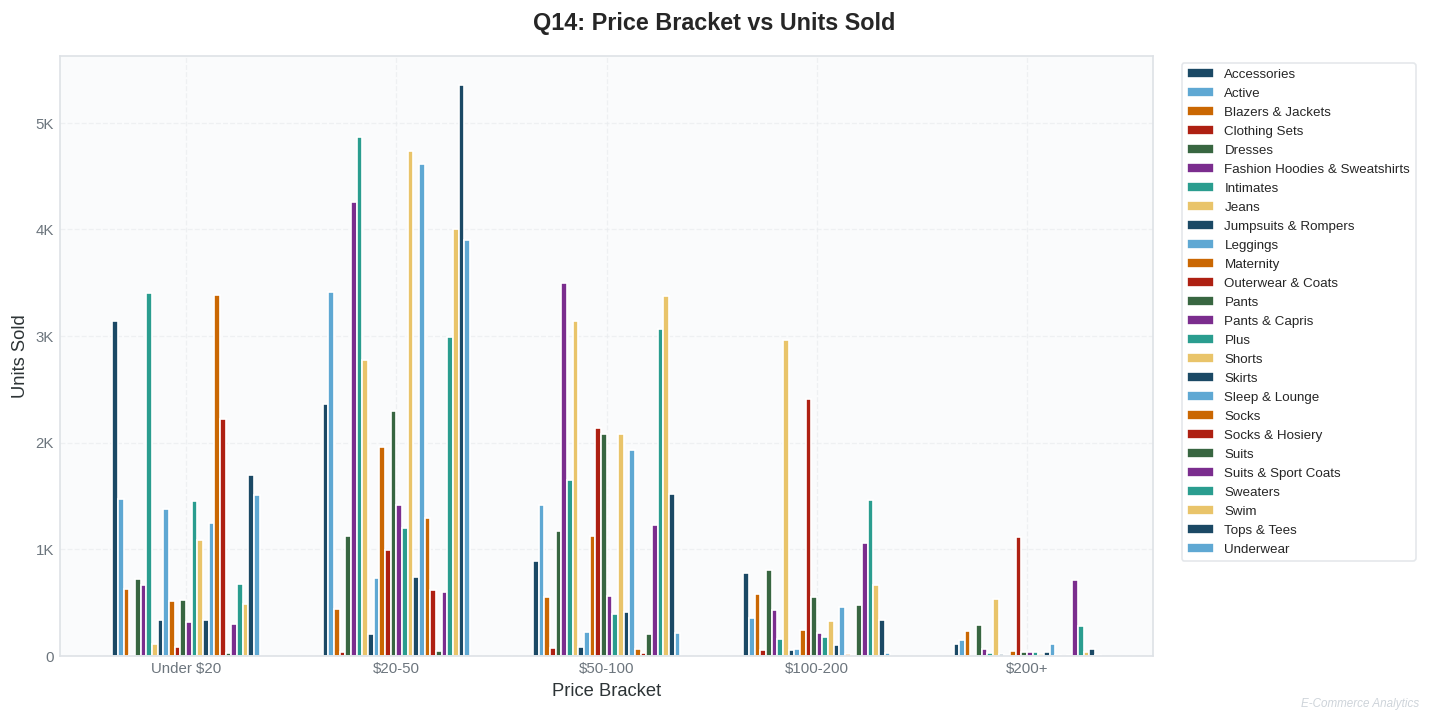

In [20]:

# Q14: PRICE ELASTICITY PROXY
# Business Question: How does price affect sales volume?

# --- Analysis ---
df_valid_copy = df_valid.copy()
df_valid_copy['price_bracket'] = pd.cut(
    df_valid_copy['retail_price'],
    bins=[0, 20, 50, 100, 200, float('inf')],
    labels=['Under $20', '$20-50', '$50-100', '$100-200', '$200+']
)

q14 = (df_valid_copy.groupby(['category', 'price_bracket'], observed=True)
       .agg(units_sold=('id', 'count'), avg_price=('sale_price', 'mean'),
            total_revenue=('sale_price', 'sum'))
       .round(2).reset_index())

display(style_table(q14.head(15), "Q14: Price Bracket vs Volume by Category"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(12, 6))
fig.suptitle('Q14: Price Bracket vs Units Sold', fontsize=14, fontweight='bold')

pivot_price = q14.pivot(index='price_bracket', columns='category',
                         values='units_sold').fillna(0)
pivot_price.plot(kind='bar', ax=ax, color=PALETTE_8[:len(pivot_price.columns)],
                 edgecolor='white', width=0.7)
ax.set_ylabel('Units Sold')
ax.set_xlabel('Price Bracket')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_number))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
add_watermark(fig)
plt.show()

,category,brand,total_orders,returned,return_rate_pct
5361,Tops & Tees,Blue Banana,24,8,33.330000
3777,Skirts,Ed Garments,23,7,30.430000
5535,Tops & Tees,MJ Soffe,24,7,29.170000
2777,Pants,Jonathan Quale,23,6,26.090000
4223,Socks,Extra Wide Sock Company,31,8,25.810000
2514,Outerwear & Coats,Jessica Simpson,39,10,25.640000
934,Dresses,Julian Taylor,32,8,25.000000
1297,Fashion Hoodies & Sweatshirts,Nike,20,5,25.000000
4999,Sweaters,Tipsy Elves,28,7,25.000000
2716,Pants,Cianni,40,10,25.000000


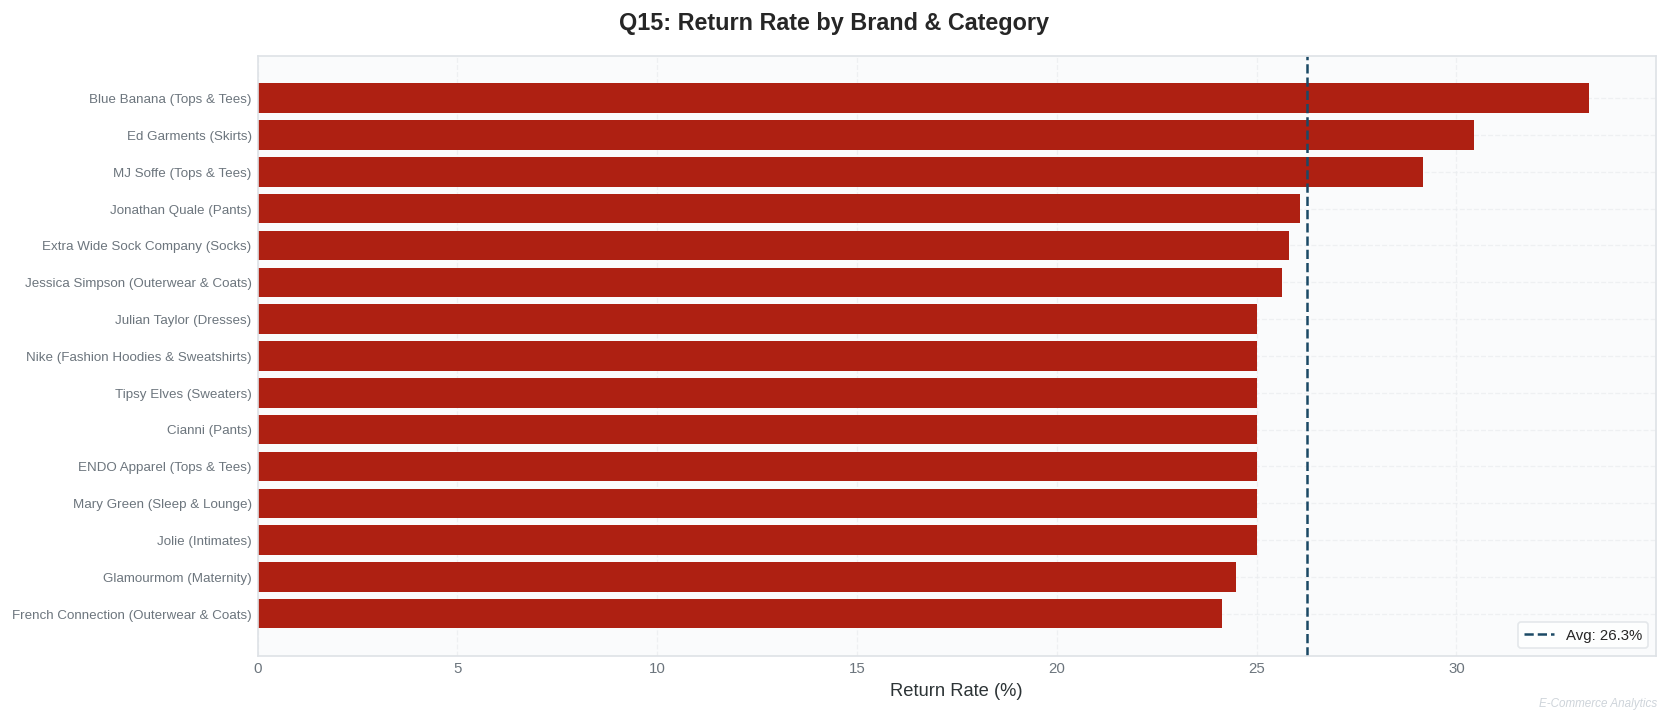

In [21]:

# Q15: RETURN RATE BY CATEGORY & BRAND
# Business Question: Which products have the highest return rates?

# --- Analysis ---
q15 = (df.groupby(['category', 'brand'])
       .agg(
           total_orders=('order_id', 'nunique'),
           returned=('status', lambda x: (x == 'Returned').sum())
       ).reset_index())

q15['return_rate_pct'] = (q15['returned'] / q15['total_orders'] * 100).round(2)
q15 = q15[q15['total_orders'] >= 20].sort_values('return_rate_pct', ascending=False).head(15)

display(style_table(q15, "Q15: Highest Return Rates by Brand & Category"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 6))
fig.suptitle('Q15: Return Rate by Brand & Category', fontsize=14, fontweight='bold')

q15['label'] = q15['brand'] + ' (' + q15['category'] + ')'
colors_ret = [COLORS['highlight'] if x > 10 else COLORS['accent'] if x > 5 else COLORS['success']
              for x in q15['return_rate_pct']]
bars = ax.barh(range(len(q15)), q15['return_rate_pct'], color=colors_ret)
ax.set_yticks(range(len(q15)))
ax.set_yticklabels(q15['label'], fontsize=8)
ax.set_xlabel('Return Rate (%)')
ax.axvline(x=q15['return_rate_pct'].mean(), color=COLORS['primary'],
           linestyle='--', label=f"Avg: {q15['return_rate_pct'].mean():.1f}%")
ax.legend()
ax.invert_yaxis()

plt.tight_layout()
add_watermark(fig)
plt.show()

## **SECTION 4: FUNNEL & EVENTS**

,step,users,conversion_from_prev,overall_conversion
0,home,63197,100.000000,100.000000
1,department,80044,126.700000,126.700000
2,product,80044,100.000000,126.700000
3,cart,80044,100.000000,126.700000
4,purchase,80044,100.000000,126.700000


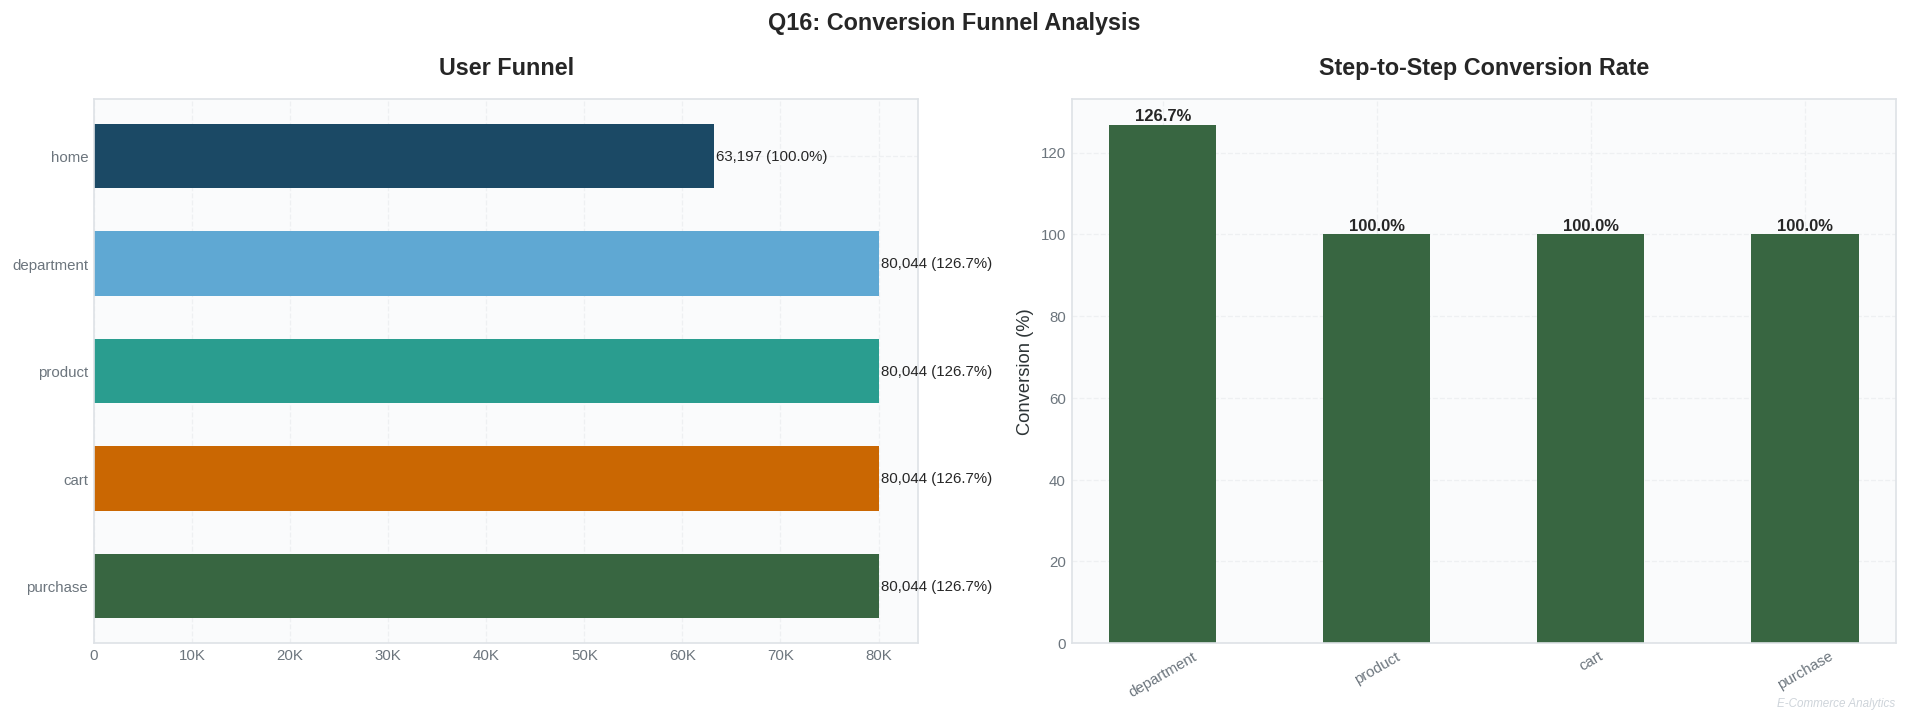

In [22]:

# Q16: CONVERSION FUNNEL
# Business Question: Where do users drop off in the purchase journey?

# --- Analysis ---
funnel_steps = ['home', 'department', 'product', 'cart', 'purchase']
funnel_data = []

for step in funnel_steps:
    users_count = events[events['event_type'] == step]['user_id'].nunique()
    funnel_data.append({'step': step, 'users': users_count})

funnel_df = pd.DataFrame(funnel_data)
funnel_df['conversion_from_prev'] = (funnel_df['users'] / funnel_df['users'].shift(1) * 100).round(1)
funnel_df['overall_conversion'] = (funnel_df['users'] / funnel_df['users'].iloc[0] * 100).round(1)
funnel_df['conversion_from_prev'].iloc[0] = 100.0

display(style_table(funnel_df, "Q16: Conversion Funnel"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Q16: Conversion Funnel Analysis', fontsize=14, fontweight='bold')

# Funnel bar
colors_funnel = [COLORS['primary'], COLORS['secondary'], COLORS['teal'],
                 COLORS['accent'], COLORS['success']]
bars = ax1.barh(funnel_df['step'].iloc[::-1], funnel_df['users'].iloc[::-1],
                color=colors_funnel[::-1], height=0.6)
for bar, val, pct in zip(bars, funnel_df['users'].iloc[::-1],
                          funnel_df['overall_conversion'].iloc[::-1]):
    ax1.text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2,
             f'{val:,} ({pct}%)', va='center', fontsize=9)
ax1.set_title('User Funnel')
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(format_number))

# Step-to-step conversion
ax2.bar(funnel_df['step'].iloc[1:], funnel_df['conversion_from_prev'].iloc[1:],
        color=[COLORS['success'] if x > 50 else COLORS['accent'] if x > 20 else COLORS['highlight']
               for x in funnel_df['conversion_from_prev'].iloc[1:]], width=0.5)
ax2.set_title('Step-to-Step Conversion Rate')
ax2.set_ylabel('Conversion (%)')
ax2.tick_params(axis='x', rotation=30)
for i, v in enumerate(funnel_df['conversion_from_prev'].iloc[1:]):
    ax2.text(i, v + 1, f'{v}%', ha='center', fontweight='bold')

plt.tight_layout()
add_watermark(fig)
plt.show()

,duration_bucket,sessions,avg_events,pct
0,Bounce (0s),129120,1.000000,19.100000
1,Under 1 min,4838,2.100000,0.700000
2,1-5 min,47322,3.700000,7.000000
3,5-15 min,146268,4.000000,21.600000
4,15+ min,349806,4.300000,51.600000


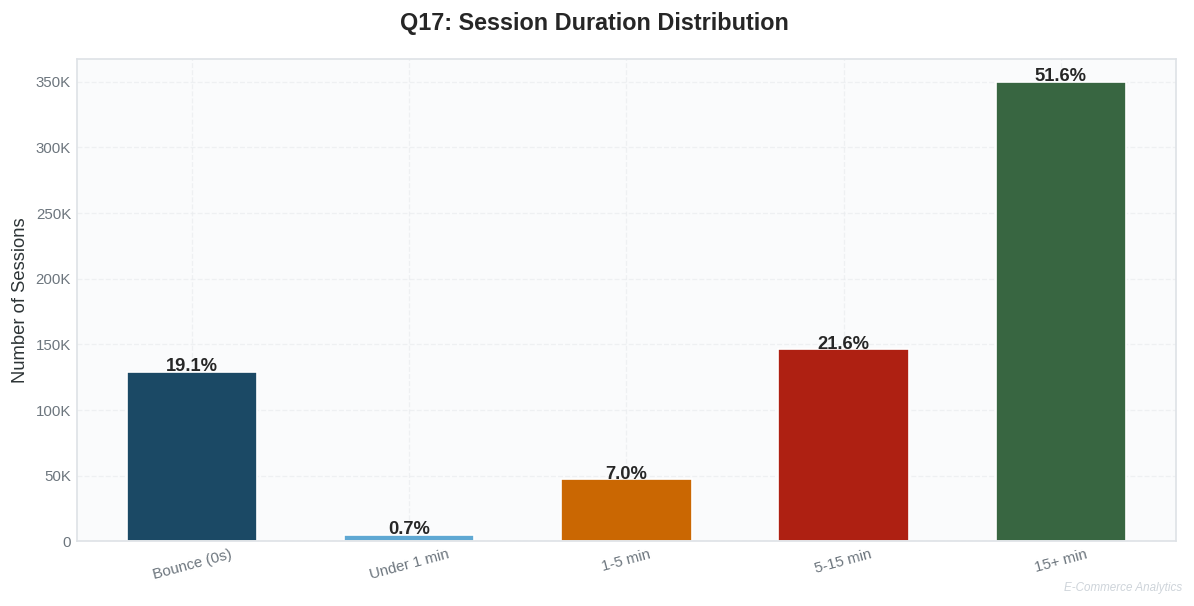

In [23]:

# Q17: SESSION DURATION ANALYSIS
# Business Question: How long do users stay on the site?

# --- Analysis ---
session_stats = (events.groupby('session_id')
                 .agg(
                     user_id=('user_id', 'first'),
                     event_count=('id', 'count'),
                     duration_sec=('created_at', lambda x: (x.max() - x.min()).total_seconds())
                 ).reset_index())

session_stats['duration_bucket'] = pd.cut(
    session_stats['duration_sec'],
    bins=[-1, 0, 60, 300, 900, float('inf')],
    labels=['Bounce (0s)', 'Under 1 min', '1-5 min', '5-15 min', '15+ min']
)

q17 = (session_stats.groupby('duration_bucket', observed=True)
       .agg(sessions=('session_id', 'count'), avg_events=('event_count', 'mean'))
       .round(1).reset_index())
q17['pct'] = (q17['sessions'] / q17['sessions'].sum() * 100).round(1)

display(style_table(q17, "Q17: Session Duration Distribution"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Q17: Session Duration Distribution', fontsize=14, fontweight='bold')

bars = ax.bar(q17['duration_bucket'].astype(str), q17['sessions'],
              color=PALETTE_8[:5], width=0.6, edgecolor='white')
for bar, pct in zip(bars, q17['pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'{pct}%', ha='center', fontweight='bold', fontsize=11)
ax.set_ylabel('Number of Sessions')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_number))
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
add_watermark(fig)
plt.show()

,traffic_source,total_sessions,bounces,bounce_rate_pct
3,Organic,34301,6306,18.400000
0,Adwords,205010,37609,18.300000
1,Email,306313,56096,18.300000
4,YouTube,68202,12432,18.200000
2,Facebook,67933,12273,18.100000


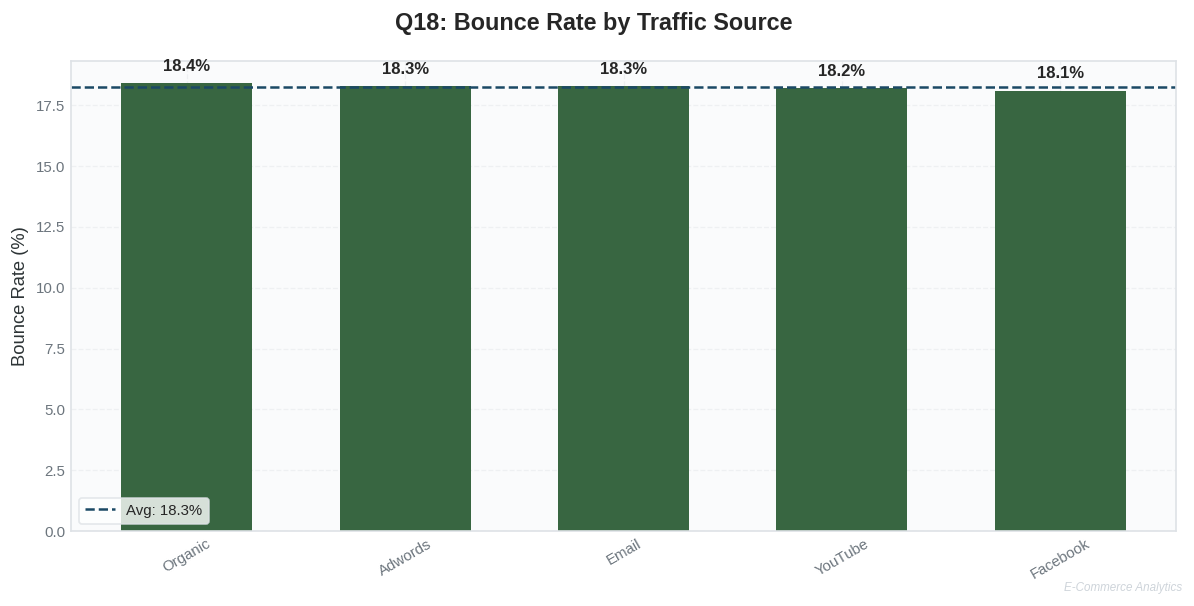

In [24]:

# Q18: BOUNCE RATE BY TRAFFIC SOURCE
# Business Question: Which traffic sources have highest bounce rates?

# --- Analysis ---
session_traffic = (events.groupby(['session_id', 'traffic_source'])
                   .size().reset_index(name='event_count'))

session_traffic['is_bounce'] = session_traffic['event_count'] == 1

q18 = (session_traffic.groupby('traffic_source')
       .agg(total_sessions=('session_id', 'count'),
            bounces=('is_bounce', 'sum'))
       .reset_index())
q18['bounce_rate_pct'] = (q18['bounces'] / q18['total_sessions'] * 100).round(1)
q18 = q18.sort_values('bounce_rate_pct', ascending=False)

display(style_table(q18, "Q18: Bounce Rate by Traffic Source"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Q18: Bounce Rate by Traffic Source', fontsize=14, fontweight='bold')

colors_bounce = [COLORS['highlight'] if x > 50 else COLORS['accent'] if x > 30 else COLORS['success']
                 for x in q18['bounce_rate_pct']]
bars = ax.bar(q18['traffic_source'], q18['bounce_rate_pct'], color=colors_bounce, width=0.6)
ax.axhline(y=q18['bounce_rate_pct'].mean(), color=COLORS['primary'],
           linestyle='--', label=f"Avg: {q18['bounce_rate_pct'].mean():.1f}%")
ax.set_ylabel('Bounce Rate (%)')
ax.legend()
ax.tick_params(axis='x', rotation=30)
for bar, val in zip(bars, q18['bounce_rate_pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val}%', ha='center', fontweight='bold')

plt.tight_layout()
add_watermark(fig)
plt.show()

,traffic_source,total_users,converted_users,attributed_revenue,conversion_rate
1,Email,36034,61761,3674852.820000,171.400000
0,Adwords,24052,40767,2427108.200000,169.500000
2,Facebook,8022,13618,820855.760000,169.760000
4,YouTube,7935,13578,808620.520000,171.120000
3,Organic,4001,6713,395899.410000,167.780000


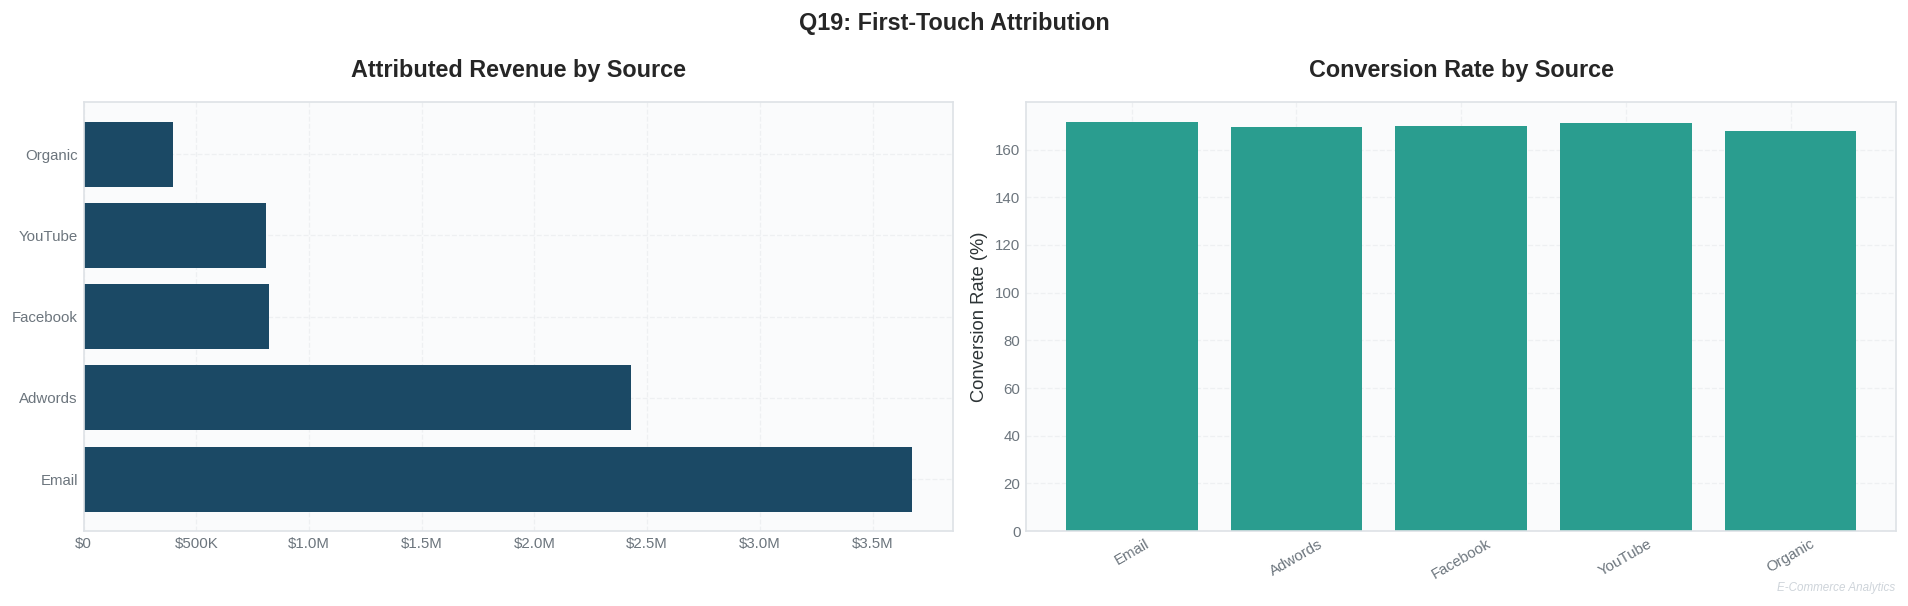

In [25]:

# Q19: FIRST-TOUCH ATTRIBUTION
# Business Question: Which traffic source drives the most revenue?

# --- Analysis ---
first_touch = (events.sort_values('created_at')
               .drop_duplicates(subset='user_id', keep='first')
               [['user_id', 'traffic_source']])

attr = (first_touch.merge(df_valid[['user_id', 'sale_price']], on='user_id', how='left')
        .groupby('traffic_source')
        .agg(
            total_users=('user_id', 'nunique'),
            converted_users=('sale_price', 'count'),
            attributed_revenue=('sale_price', 'sum')
        ).reset_index())

attr['conversion_rate'] = (attr['converted_users'] / attr['total_users'] * 100).round(2)
attr['attributed_revenue'] = attr['attributed_revenue'].round(2)
attr = attr.sort_values('attributed_revenue', ascending=False)

display(style_table(attr, "Q19: First-Touch Attribution by Traffic Source"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Q19: First-Touch Attribution', fontsize=14, fontweight='bold')

ax1.barh(attr['traffic_source'], attr['attributed_revenue'], color=COLORS['primary'])
ax1.set_title('Attributed Revenue by Source')
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))

ax2.bar(attr['traffic_source'], attr['conversion_rate'], color=COLORS['teal'])
ax2.set_title('Conversion Rate by Source')
ax2.set_ylabel('Conversion Rate (%)')
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
add_watermark(fig)
plt.show()

,path,frequency
37,department → product → cart,455459
64,product → cart → purchase,176415
61,product → cart → department,158946
10,cart → department → product,158945
59,product → cart → cancel,121371
50,home → department → product,84931
28,department → cart → product,4134
65,product → department → cart,4040
15,cart → product → cancel,2069
58,product → cancel → cart,2066


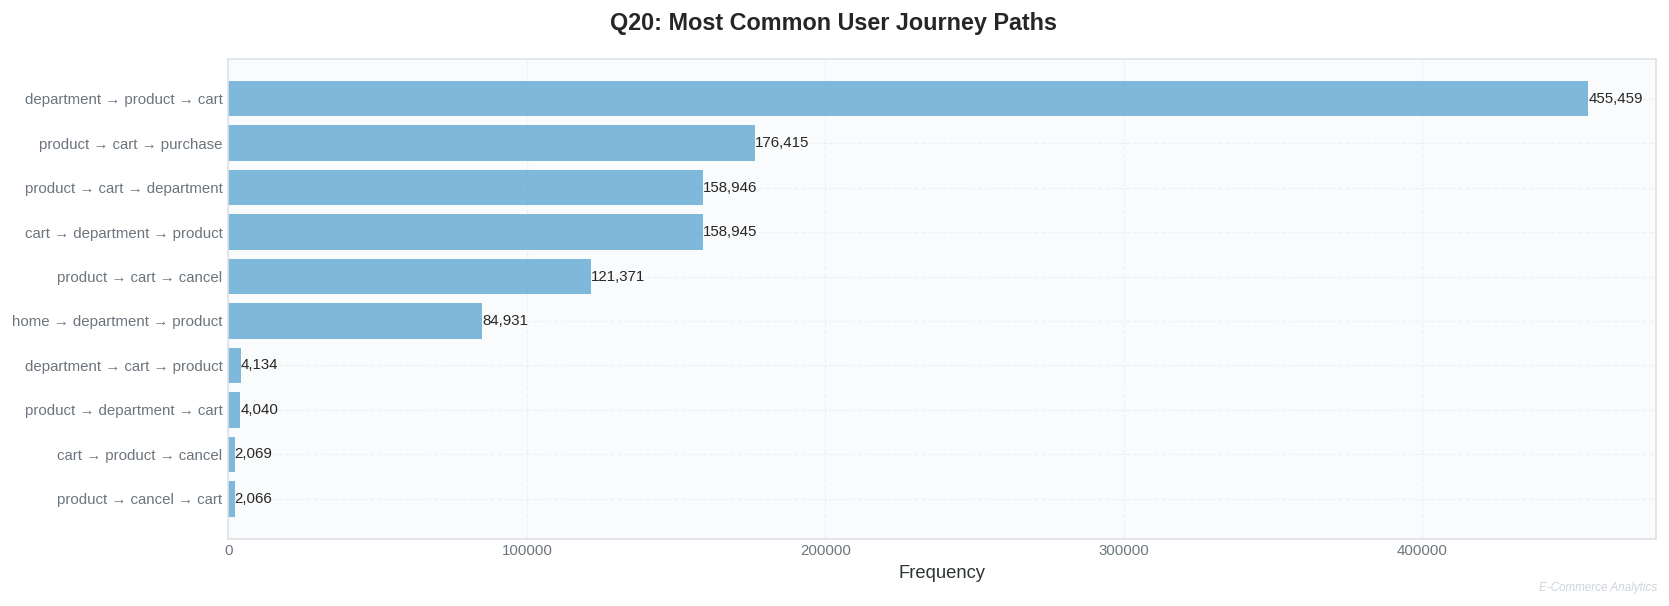

In [26]:

# Q20: EVENT SEQUENCE PATTERN (User Journey)
# Business Question: What are the most common user journeys?

# --- Analysis ---
events_sorted = events.sort_values(['session_id', 'created_at'])
events_sorted['step_2'] = events_sorted.groupby('session_id')['event_type'].shift(-1)
events_sorted['step_3'] = events_sorted.groupby('session_id')['event_type'].shift(-2)

sequences = (events_sorted.dropna(subset=['step_2', 'step_3'])
             .groupby(['event_type', 'step_2', 'step_3'])
             .size().reset_index(name='frequency')
             .sort_values('frequency', ascending=False).head(10))

sequences['path'] = sequences['event_type'] + ' → ' + sequences['step_2'] + ' → ' + sequences['step_3']

display(style_table(sequences[['path', 'frequency']], "Q20: Top 10 Event Sequences"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 5))
fig.suptitle('Q20: Most Common User Journey Paths', fontsize=14, fontweight='bold')

bars = ax.barh(sequences['path'].iloc[::-1], sequences['frequency'].iloc[::-1],
               color=COLORS['secondary'], alpha=0.8)
ax.set_xlabel('Frequency')
for bar, val in zip(bars, sequences['frequency'].iloc[::-1]):
    ax.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)

plt.tight_layout()
add_watermark(fig)
plt.show()

##  SECTION 5: GAP & STREAK

✅ Removed NaT dates. Rows remaining: 121,907



,user_id,streak_start,streak_end,streak_length
85605,80378,2024-01-14,2024-01-19,6
69561,65333,2023-11-16,2023-11-20,5
17889,16811,2022-09-27,2022-10-01,5
67281,63157,2024-01-11,2024-01-15,5
58019,54571,2023-11-17,2023-11-21,5
103031,96772,2024-01-14,2024-01-18,5
15025,14123,2023-12-01,2023-12-05,5
2693,2528,2022-11-27,2022-12-01,5
71391,67014,2023-11-14,2023-11-18,5
8470,7973,2022-10-12,2022-10-15,4


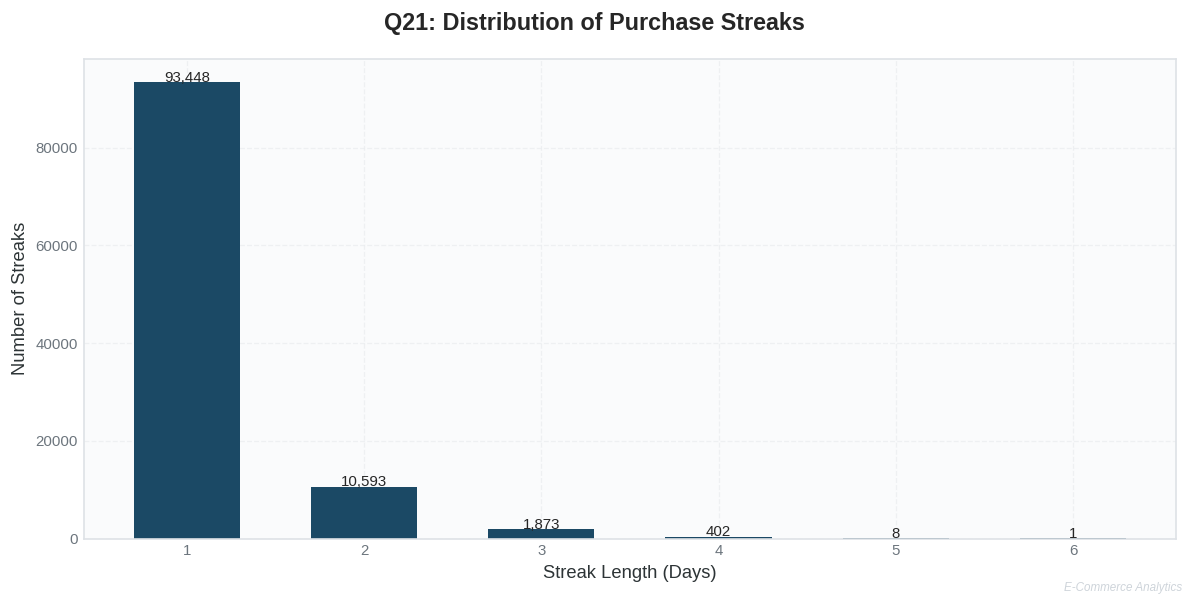

In [28]:

# Q21: CONSECUTIVE PURCHASE DAY STREAKS (FIXED)
# Business Question: Which customers buy on consecutive days?

# --- Analysis ---
purchase_days = (df_valid[['user_id', 'date']].drop_duplicates()
                 .sort_values(['user_id', 'date']))

# --- FIX: Drop NaT/None dates BEFORE toordinal() ---
purchase_days = purchase_days.dropna(subset=['date']).copy()
print(f"✅ Removed NaT dates. Rows remaining: {len(purchase_days):,}\n")

purchase_days['rank'] = purchase_days.groupby('user_id').cumcount()
purchase_days['date_num'] = purchase_days['date'].apply(lambda x: x.toordinal())
purchase_days['streak_group'] = purchase_days['date_num'] - purchase_days['rank']

streaks = (purchase_days.groupby(['user_id', 'streak_group'])
           .agg(streak_start=('date', 'min'), streak_end=('date', 'max'),
                streak_length=('date', 'count'))
           .reset_index())

long_streaks = (streaks[streaks['streak_length'] >= 2]
                .sort_values('streak_length', ascending=False).head(15))

display(style_table(long_streaks[['user_id', 'streak_start', 'streak_end', 'streak_length']],
                    "Q21: Longest Purchase Streaks"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Q21: Distribution of Purchase Streaks', fontsize=14, fontweight='bold')

streak_dist = (streaks[streaks['streak_length'] <= 10]['streak_length']
               .value_counts().sort_index())

bars = ax.bar(streak_dist.index, streak_dist.values, color=COLORS['primary'], width=0.6)
ax.set_xlabel('Streak Length (Days)')
ax.set_ylabel('Number of Streaks')
for bar, val in zip(bars, streak_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{val:,}', ha='center', fontsize=9)

plt.tight_layout()
add_watermark(fig)
plt.show()

,user_id,order_id,created_at,prev_order,gap_days
573,612,767,2024-01-03 02:11:06+00:00,2019-03-25 03:21:56+00:00,1744.0
78538,83462,104526,2023-11-18 02:01:24+00:00,2019-05-06 04:01:38+00:00,1656.0
50110,53347,66774,2023-10-28 10:58:03+00:00,2019-04-21 09:02:28+00:00,1651.0
48454,51589,64572,2023-10-24 03:36:39+00:00,2019-04-22 03:46:14+00:00,1645.0
30617,32648,40783,2023-11-15 18:38:44+00:00,2019-05-31 17:50:56+00:00,1629.0
69753,73959,92722,2023-12-22 15:15:23+00:00,2019-08-02 13:39:17+00:00,1603.0
93862,99759,124926,2023-08-16 09:09:19+00:00,2019-03-29 09:03:18+00:00,1601.0
29073,31032,38748,2023-11-13 08:58:49+00:00,2019-07-10 08:38:56+00:00,1587.0
73456,77958,97689,2024-01-06 09:54:53+00:00,2019-09-08 11:37:46+00:00,1580.0
57893,61468,77048,2023-08-09 05:09:45+00:00,2019-05-06 06:28:06+00:00,1555.0


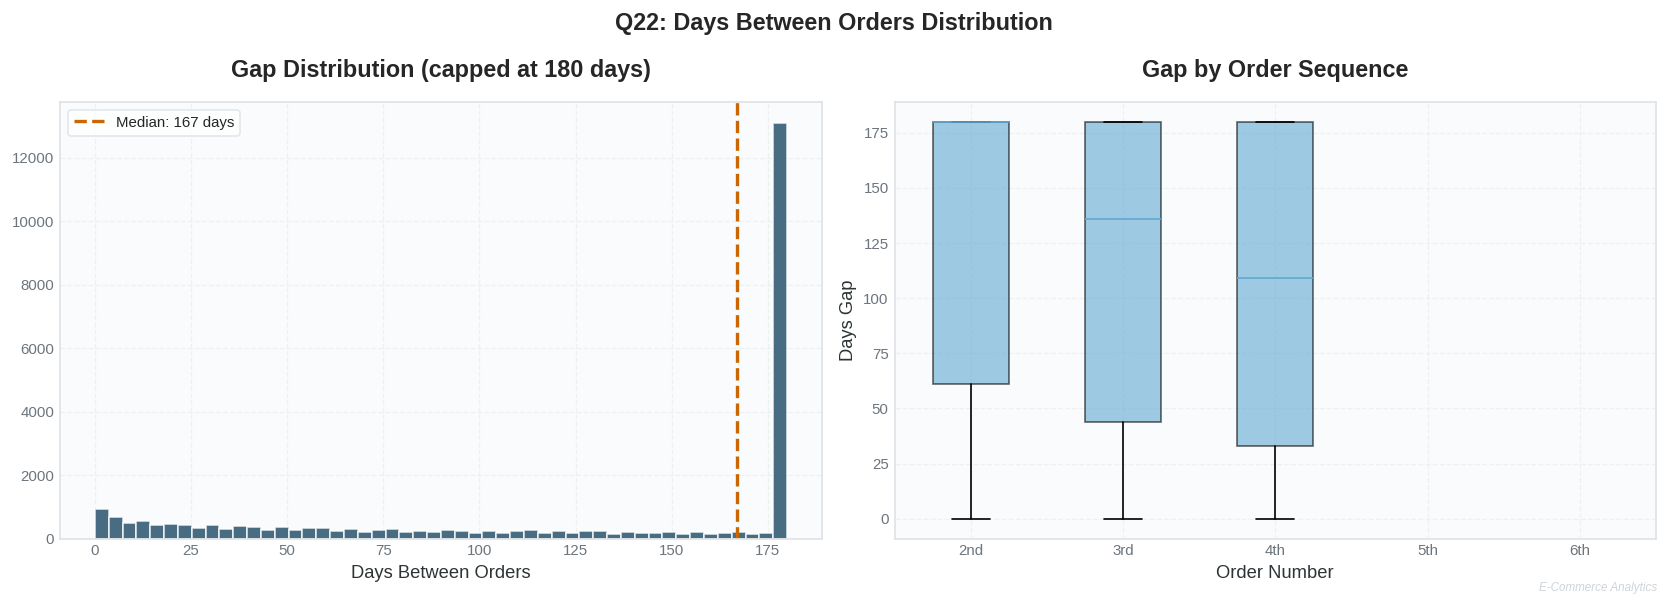

In [29]:

# Q22: ORDER GAP ANALYSIS
# Business Question: How long between repeat purchases?

# --- Analysis ---
user_orders = (df_valid.groupby(['user_id', 'order_id'])['created_at']
               .min().reset_index().sort_values(['user_id', 'created_at']))

user_orders['prev_order'] = user_orders.groupby('user_id')['created_at'].shift(1)
user_orders['gap_days'] = (user_orders['created_at'] - user_orders['prev_order']).dt.days

q22 = user_orders.dropna(subset=['gap_days'])

display(style_table(q22[['user_id', 'order_id', 'created_at', 'prev_order', 'gap_days']]
                    .sort_values('gap_days', ascending=False).head(10).astype(str),
                    "Q22: Largest Order Gaps"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Q22: Days Between Orders Distribution', fontsize=14, fontweight='bold')

ax1.hist(q22['gap_days'].clip(upper=180), bins=50, color=COLORS['primary'],
         edgecolor='white', alpha=0.8)
ax1.axvline(q22['gap_days'].median(), color=COLORS['accent'],
            linewidth=2, linestyle='--', label=f"Median: {q22['gap_days'].median():.0f} days")
ax1.set_title('Gap Distribution (capped at 180 days)')
ax1.set_xlabel('Days Between Orders')
ax1.legend()

# Box plot by order number
q22['order_seq'] = q22.groupby('user_id').cumcount() + 2
box_data = [q22[q22['order_seq'] == n]['gap_days'].clip(upper=180) for n in range(2, 7)]
ax2.boxplot(box_data, patch_artist=True,
            boxprops=dict(facecolor=COLORS['secondary'], alpha=0.6))
ax2.set_xticklabels(['2nd', '3rd', '4th', '5th', '6th'])
ax2.set_title('Gap by Order Sequence')
ax2.set_xlabel('Order Number')
ax2.set_ylabel('Days Gap')

plt.tight_layout()
add_watermark(fig)
plt.show()

,start,end,months
streak_group,,,
1,2019-02,2019-10,9
14,2023-05,2023-12,8
8,2021-08,2022-01,6
4,2020-09,2021-01,5
3,2020-04,2020-07,4
9,2022-03,2022-05,3
2,2019-12,2020-02,3
12,2022-12,2023-01,2
10,2022-07,2022-08,2


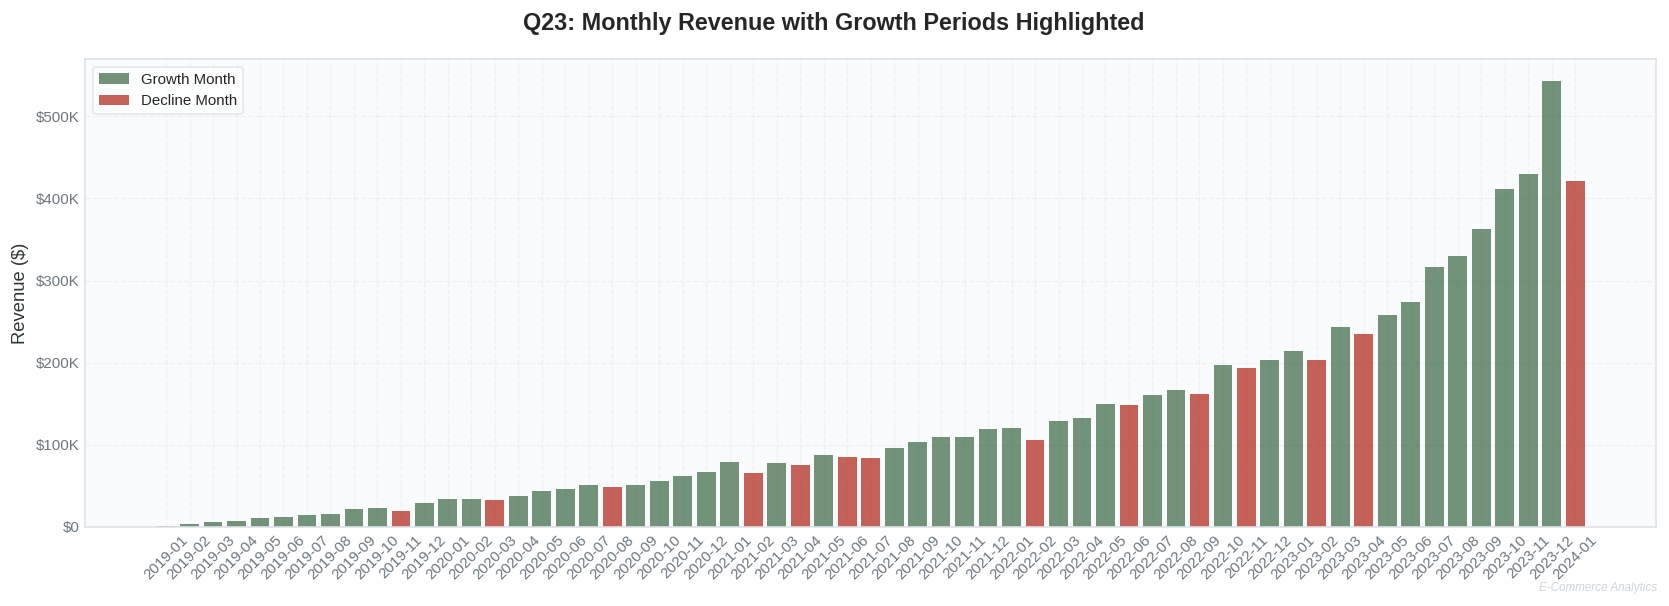

In [30]:

# Q23: CONSECUTIVE MONTHS OF REVENUE GROWTH
# Business Question: What is the longest growth streak?

# --- Analysis ---
monthly = (df_valid.groupby('year_month')['sale_price']
           .sum().reset_index(name='revenue').sort_values('year_month'))

monthly['is_growth'] = monthly['revenue'] > monthly['revenue'].shift(1)
monthly['streak_group'] = (~monthly['is_growth']).cumsum()

growth_streaks = (monthly[monthly['is_growth']]
                  .groupby('streak_group')
                  .agg(start=('year_month', 'first'), end=('year_month', 'last'),
                       months=('year_month', 'count'))
                  .sort_values('months', ascending=False))

display(style_table(growth_streaks.head(10), "Q23: Longest Revenue Growth Streaks"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 5))
fig.suptitle('Q23: Monthly Revenue with Growth Periods Highlighted', fontsize=14, fontweight='bold')

colors_months = [COLORS['success'] if g else COLORS['highlight'] for g in monthly['is_growth'].fillna(False)]
ax.bar(monthly['year_month'], monthly['revenue'], color=colors_months, alpha=0.7)
ax.set_ylabel('Revenue ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax.tick_params(axis='x', rotation=45)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=COLORS['success'], alpha=0.7, label='Growth Month'),
                   Patch(facecolor=COLORS['highlight'], alpha=0.7, label='Decline Month')]
ax.legend(handles=legend_elements)

plt.tight_layout()
add_watermark(fig)
plt.show()

,gap_type,inactive_gaps,unique_customers,avg_gap
0,3-6 Months,4824,4504,133.000000
1,6-12 Months,5795,5391,261.400000
2,12+ Months,7114,6785,649.400000


,user_id,created_at,next_order,gap_days
572,612,2019-03-25 03:21:56+00:00,2024-01-03 02:11:06+00:00,1744.0
78537,83462,2019-05-06 04:01:38+00:00,2023-11-18 02:01:24+00:00,1656.0
50111,53347,2019-04-21 09:02:28+00:00,2023-10-28 10:58:03+00:00,1651.0
48455,51589,2019-04-22 03:46:14+00:00,2023-10-24 03:36:39+00:00,1645.0
30618,32648,2019-05-31 17:50:56+00:00,2023-11-15 18:38:44+00:00,1629.0
69754,73959,2019-08-02 13:39:17+00:00,2023-12-22 15:15:23+00:00,1603.0
93863,99759,2019-03-29 09:03:18+00:00,2023-08-16 09:09:19+00:00,1601.0
29072,31032,2019-07-10 08:38:56+00:00,2023-11-13 08:58:49+00:00,1587.0
73455,77958,2019-09-08 11:37:46+00:00,2024-01-06 09:54:53+00:00,1580.0
57892,61468,2019-05-06 06:28:06+00:00,2023-08-09 05:09:45+00:00,1555.0


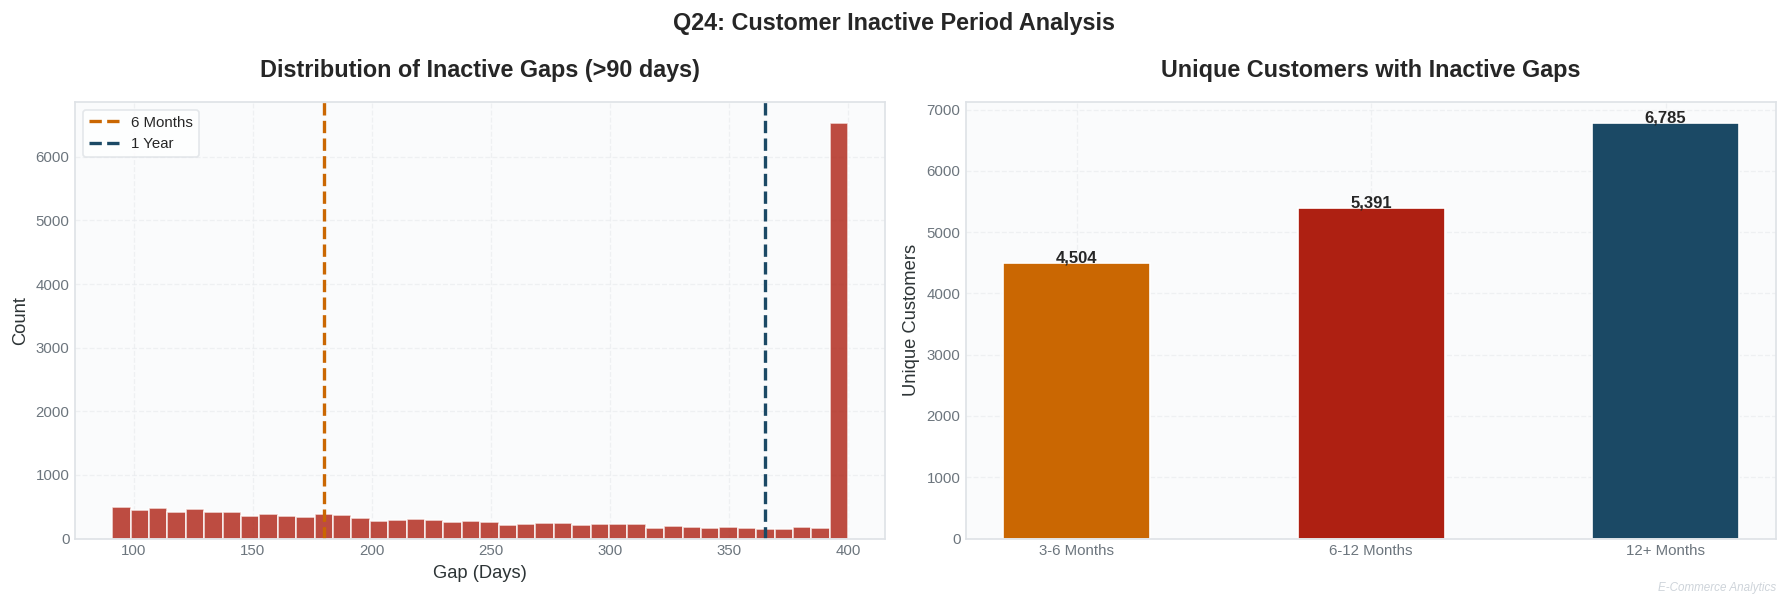

In [31]:
# Q24: CUSTOMER INACTIVE PERIODS
# Business Question: Which customers had long gaps between orders?

# --- Analysis ---
user_order_dates = (df_valid.groupby(['user_id', 'order_id'])['created_at']
                    .min().reset_index()
                    .sort_values(['user_id', 'created_at']))

user_order_dates = user_order_dates.dropna(subset=['created_at']).copy()

user_order_dates['next_order'] = (
    user_order_dates.groupby('user_id')['created_at'].shift(-1)
)
user_order_dates['gap_days'] = (
    user_order_dates['next_order'] - user_order_dates['created_at']
).dt.days

inactive = user_order_dates[user_order_dates['gap_days'] > 90].copy()
inactive['gap_type'] = pd.cut(
    inactive['gap_days'],
    bins=[90, 180, 365, float('inf')],
    labels=['3-6 Months', '6-12 Months', '12+ Months']
)

q24_summary = (inactive.groupby('gap_type', observed=True)
               .agg(inactive_gaps=('gap_days', 'count'),
                    unique_customers=('user_id', 'nunique'),
                    avg_gap=('gap_days', 'mean'))
               .round(1).reset_index())

display(style_table(q24_summary, "Q24: Inactive Period Summary (>90 days)"))
display(style_table(
    inactive[['user_id', 'created_at', 'next_order', 'gap_days']]
    .sort_values('gap_days', ascending=False).head(10).astype(str),
    "Q24: Top 10 Longest Inactive Gaps"
))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Q24: Customer Inactive Period Analysis', fontsize=14, fontweight='bold')

# Gap distribution
ax1.hist(inactive['gap_days'].clip(upper=400), bins=40,
         color=COLORS['highlight'], edgecolor='white', alpha=0.8)
ax1.axvline(180, color=COLORS['accent'], linewidth=2, linestyle='--', label='6 Months')
ax1.axvline(365, color=COLORS['primary'], linewidth=2, linestyle='--', label='1 Year')
ax1.set_title('Distribution of Inactive Gaps (>90 days)')
ax1.set_xlabel('Gap (Days)')
ax1.set_ylabel('Count')
ax1.legend()

# By gap type
gap_colors = [COLORS['accent'], COLORS['highlight'], COLORS['primary']]
bars = ax2.bar(q24_summary['gap_type'].astype(str), q24_summary['unique_customers'],
               color=gap_colors, width=0.5, edgecolor='white')
ax2.set_title('Unique Customers with Inactive Gaps')
ax2.set_ylabel('Unique Customers')
for bar, val in zip(bars, q24_summary['unique_customers']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             f'{val:,}', ha='center', fontweight='bold')

plt.tight_layout()
add_watermark(fig)
plt.show()

,date,dau,rolling_7d,rolling_30d,dow_change
1836,2024-01-12,626,567.000000,476.000000,17.900000
1837,2024-01-13,654,584.000000,484.000000,22.900000
1838,2024-01-14,639,600.000000,491.000000,20.100000
1839,2024-01-15,650,614.000000,499.000000,18.600000
1840,2024-01-16,286,578.000000,495.000000,-46.900000
1841,2024-01-17,218,527.000000,488.000000,-62.000000
1842,2024-01-18,142,459.000000,479.000000,-77.000000
1843,2024-01-19,80,381.000000,468.000000,-87.200000
1844,2024-01-20,17,290.000000,455.000000,-97.400000
1845,2024-01-21,8,200.000000,442.000000,-98.700000


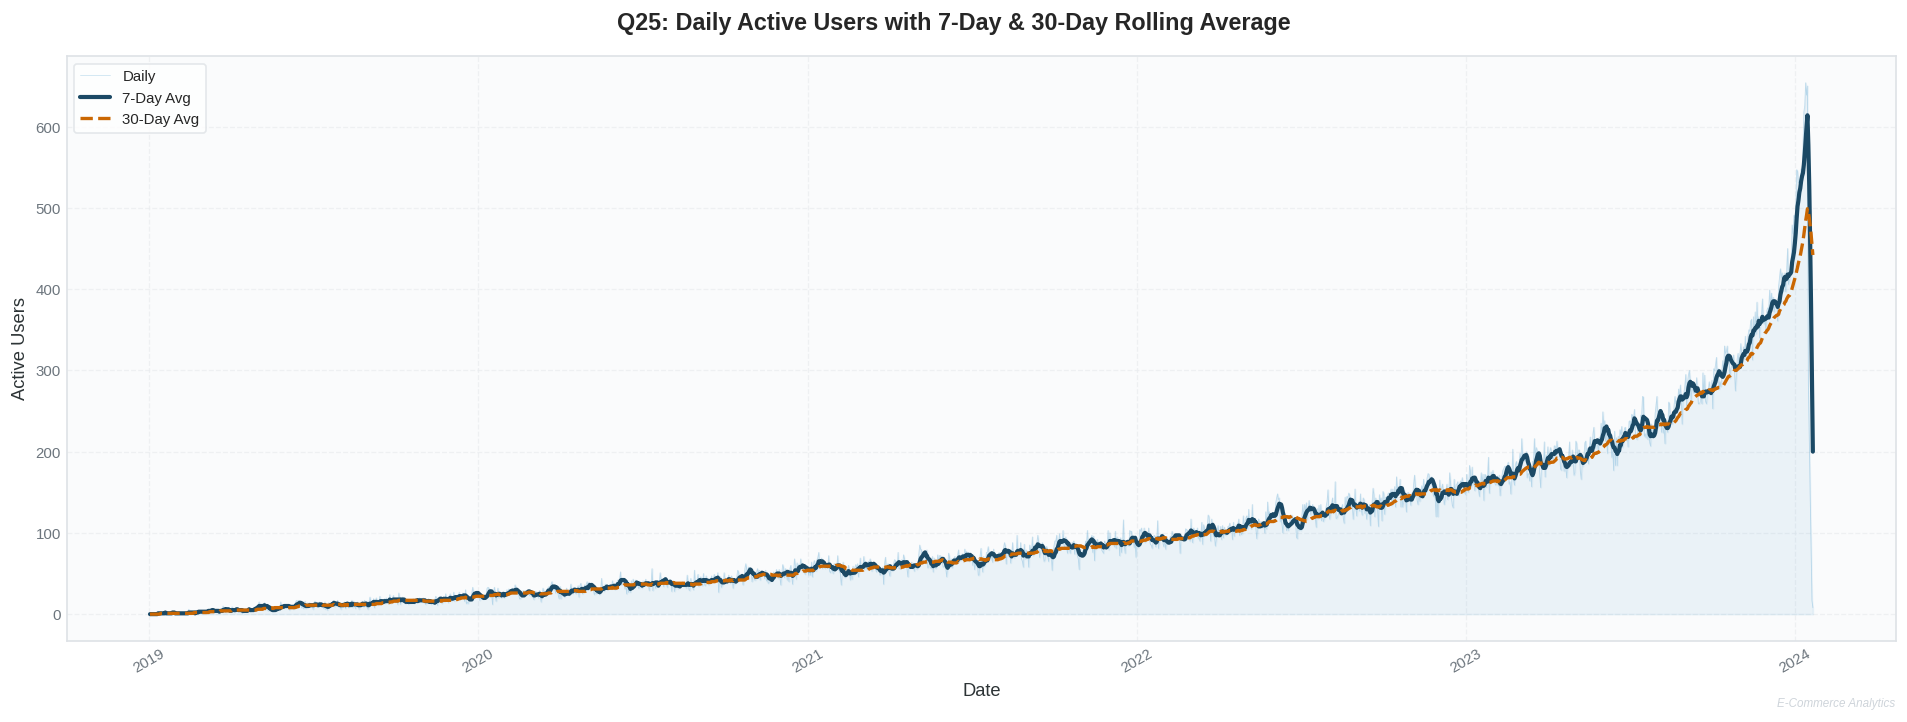

In [32]:
# Q25: DAILY ACTIVE USERS — 7-DAY ROLLING AVERAGE
# Business Question: How does daily engagement trend over time?

# --- Analysis ---
dau = (events.dropna(subset=['created_at'])
       .groupby(events['created_at'].dt.date)['user_id']
       .nunique().reset_index(name='dau'))
dau.columns = ['date', 'dau']
dau = dau.sort_values('date')

dau['rolling_7d'] = dau['dau'].rolling(7, min_periods=1).mean().round(0)
dau['rolling_30d'] = dau['dau'].rolling(30, min_periods=1).mean().round(0)
dau['dow_change'] = dau['dau'].pct_change(7).mul(100).round(1)

display(style_table(dau.tail(10), "Q25: DAU with Rolling Averages (Last 10 Days)"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(16, 6))
fig.suptitle('Q25: Daily Active Users with 7-Day & 30-Day Rolling Average',
             fontsize=14, fontweight='bold')

ax.fill_between(dau['date'], dau['dau'], alpha=0.1, color=COLORS['secondary'])
ax.plot(dau['date'], dau['dau'], color=COLORS['secondary'], alpha=0.3,
        linewidth=0.5, label='Daily')
ax.plot(dau['date'], dau['rolling_7d'], color=COLORS['primary'],
        linewidth=2.5, label='7-Day Avg')
ax.plot(dau['date'], dau['rolling_30d'], color=COLORS['accent'],
        linewidth=2, linestyle='--', label='30-Day Avg')

ax.set_ylabel('Active Users')
ax.set_xlabel('Date')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_number))
ax.legend(loc='upper left')
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
add_watermark(fig)
plt.show()

## **SECTION 6: RANKING & WINDOW FUNCTIONS**

,user_id,total_revenue,percentile_rank,percentile_bucket
53829,81262,1738.969982,100.000000,99
6644,10012,1438.209999,100.000000,99
13131,19736,1405.619991,100.000000,99
62383,94183,1395.990002,100.000000,99
18805,28392,1341.489998,99.990000,99
15054,22656,1335.970003,99.990000,99
53447,80671,1319.270004,99.990000,99
14392,21671,1312.570004,99.990000,99
3900,5836,1299.949989,99.990000,99
4613,6878,1296.059998,99.990000,99


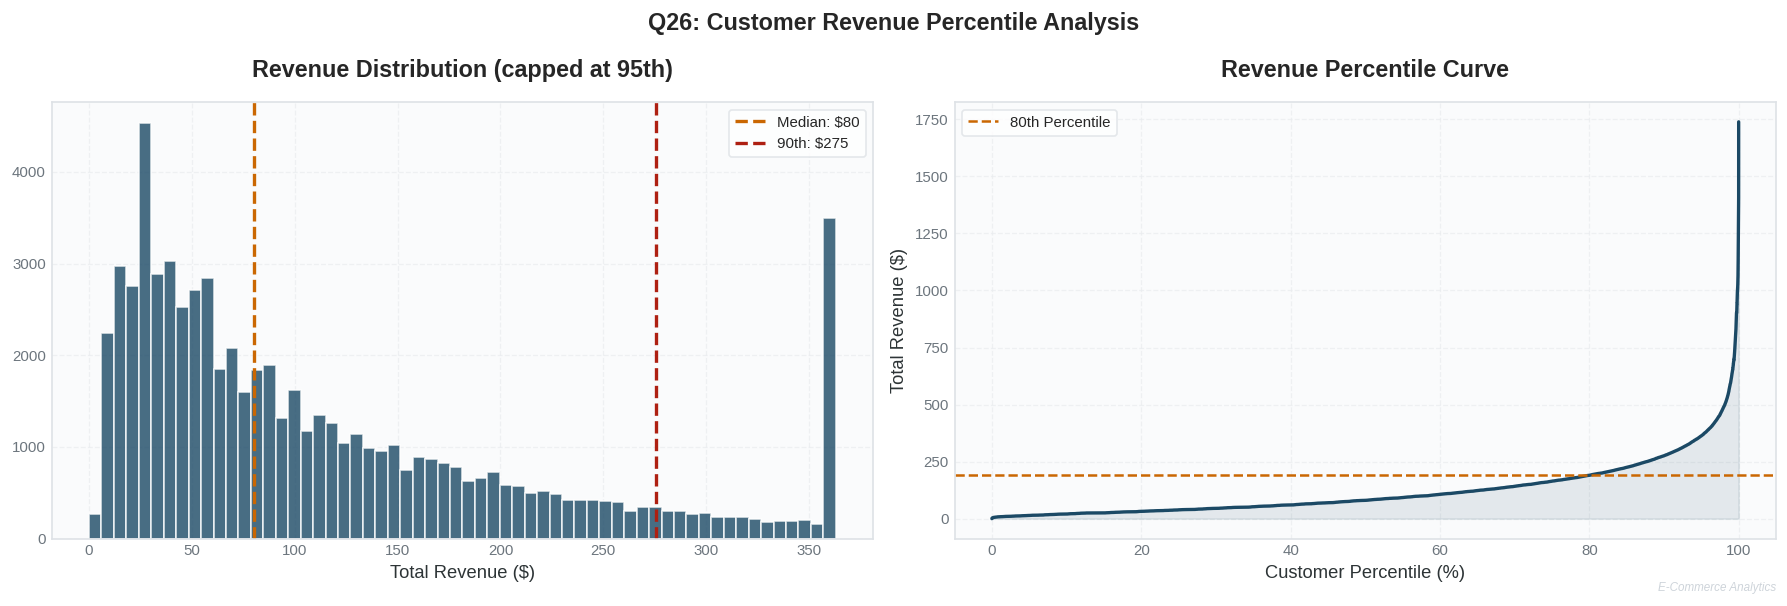

In [33]:
# Q26: REVENUE PERCENTILE ANALYSIS
# Business Question: Where do top spenders sit in the distribution?

# --- Analysis ---
cust_rev = (df_valid.groupby('user_id')['sale_price']
            .sum().reset_index(name='total_revenue'))

cust_rev['percentile_rank'] = (cust_rev['total_revenue']
                               .rank(pct=True).mul(100).round(2))
cust_rev['percentile_bucket'] = pd.qcut(
    cust_rev['total_revenue'], 100, labels=False, duplicates='drop'
) + 1

display(style_table(
    cust_rev.sort_values('total_revenue', ascending=False).head(10),
    "Q26: Top 10 Customers by Revenue Percentile"
))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Q26: Customer Revenue Percentile Analysis', fontsize=14, fontweight='bold')

# Distribution
ax1.hist(cust_rev['total_revenue'].clip(
    upper=cust_rev['total_revenue'].quantile(0.95)),
    bins=60, color=COLORS['primary'], edgecolor='white', alpha=0.8)
ax1.axvline(cust_rev['total_revenue'].median(), color=COLORS['accent'],
            linewidth=2, linestyle='--',
            label=f"Median: ${cust_rev['total_revenue'].median():.0f}")
ax1.axvline(cust_rev['total_revenue'].quantile(0.90), color=COLORS['highlight'],
            linewidth=2, linestyle='--',
            label=f"90th: ${cust_rev['total_revenue'].quantile(0.90):.0f}")
ax1.set_title('Revenue Distribution (capped at 95th)')
ax1.set_xlabel('Total Revenue ($)')
ax1.legend()

# Percentile curve
pct_data = cust_rev.sort_values('total_revenue')
pct_data['cum_pct'] = np.arange(1, len(pct_data) + 1) / len(pct_data) * 100
ax2.plot(pct_data['cum_pct'], pct_data['total_revenue'],
         color=COLORS['primary'], linewidth=2)
ax2.fill_between(pct_data['cum_pct'], pct_data['total_revenue'],
                 alpha=0.1, color=COLORS['primary'])
ax2.axhline(cust_rev['total_revenue'].quantile(0.80), color=COLORS['accent'],
            linestyle='--', label='80th Percentile')
ax2.set_title('Revenue Percentile Curve')
ax2.set_xlabel('Customer Percentile (%)')
ax2.set_ylabel('Total Revenue ($)')
ax2.legend()

plt.tight_layout()
add_watermark(fig)
plt.show()

,date,revenue,ma_7d,ma_30d
1813,2024-01-12,27538.010000,24254.340000,20552.130000
1814,2024-01-13,27084.240000,25250.860000,20833.700000
1815,2024-01-14,31412.290000,26796.980000,21314.240000
1816,2024-01-15,35590.920000,28395.110000,21917.430000
1817,2024-01-16,15622.270000,27166.500000,21820.830000
1818,2024-01-17,11354.920000,25168.270000,21549.820000
1819,2024-01-18,8106.790000,22387.060000,21188.780000
1820,2024-01-19,3384.620000,18936.580000,20664.170000
1821,2024-01-20,1499.510000,15281.620000,20135.060000
1822,2024-01-21,872.930000,10918.850000,19540.110000


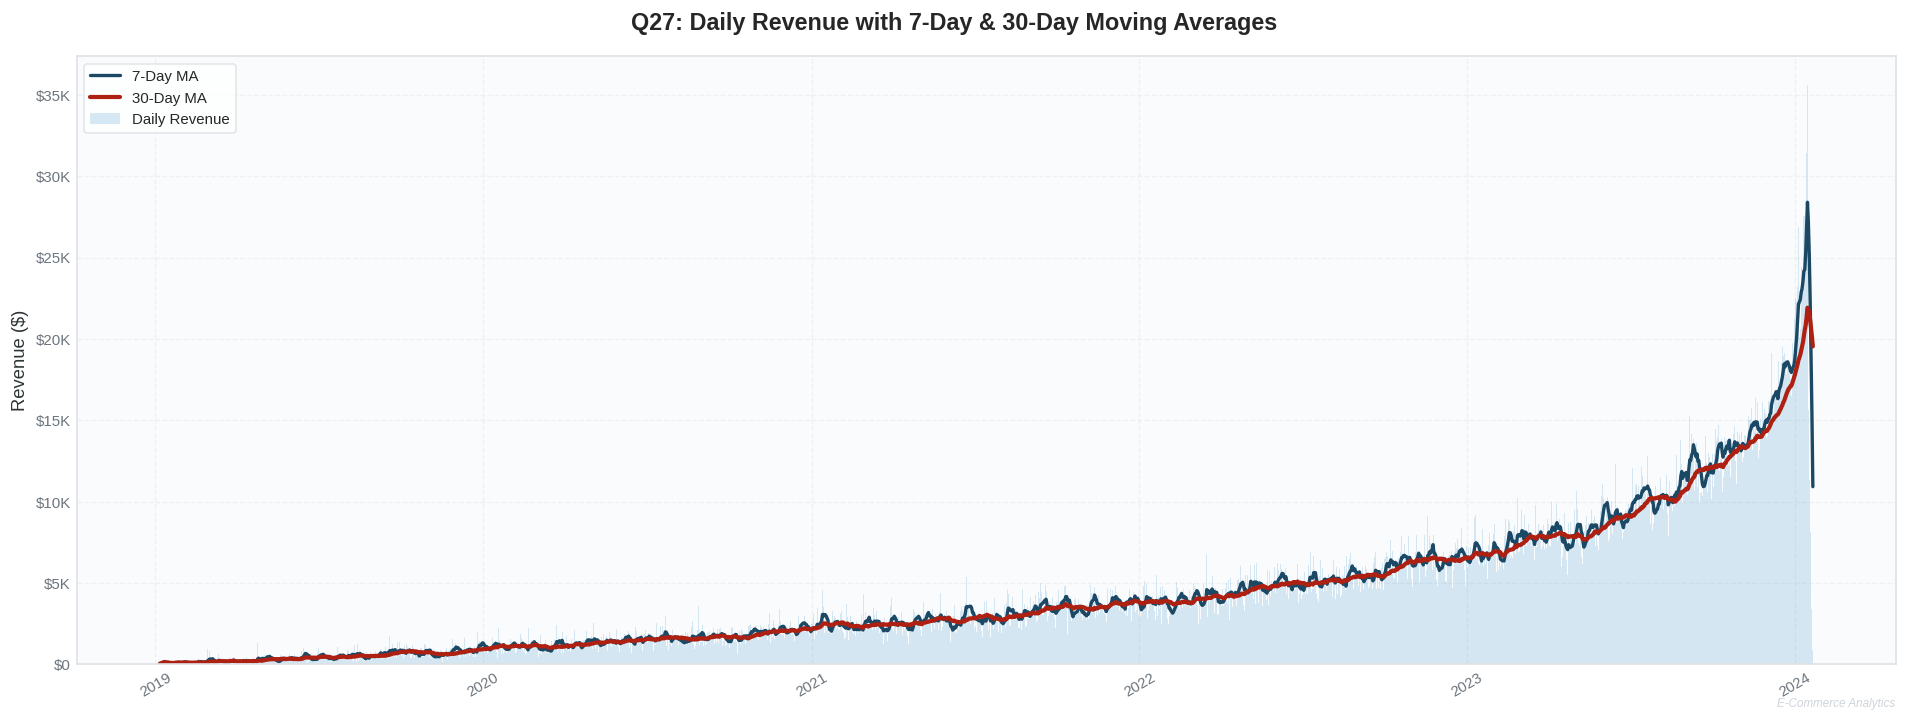

In [34]:
# Q27: MOVING AVERAGE REVENUE
# Business Question: What is the smoothed revenue trend?

# --- Analysis ---
daily_rev = (df_valid.groupby(df_valid['created_at'].dt.date)['sale_price']
             .sum().reset_index(name='revenue'))
daily_rev.columns = ['date', 'revenue']
daily_rev = daily_rev.sort_values('date')

daily_rev['ma_7d'] = daily_rev['revenue'].rolling(7, min_periods=1).mean().round(2)
daily_rev['ma_30d'] = daily_rev['revenue'].rolling(30, min_periods=1).mean().round(2)
daily_rev['revenue'] = daily_rev['revenue'].round(2)

display(style_table(daily_rev.tail(10), "Q27: Daily Revenue with Moving Averages"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(16, 6))
fig.suptitle('Q27: Daily Revenue with 7-Day & 30-Day Moving Averages',
             fontsize=14, fontweight='bold')

ax.bar(daily_rev['date'], daily_rev['revenue'],
       color=COLORS['secondary'], alpha=0.25, width=1, label='Daily Revenue')
ax.plot(daily_rev['date'], daily_rev['ma_7d'],
        color=COLORS['primary'], linewidth=2, label='7-Day MA')
ax.plot(daily_rev['date'], daily_rev['ma_30d'],
        color=COLORS['highlight'], linewidth=2.5, label='30-Day MA')

ax.set_ylabel('Revenue ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax.legend(loc='upper left')
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
add_watermark(fig)
plt.show()

,brand,total_revenue,rank_gap,rank_dense,row_num
447,Calvin Klein,154952.610000,1,1,1
699,Diesel,153819.550000,2,2,2
29,7 For All Mankind,140861.490000,3,3,3
465,Carhartt,140738.030000,4,4,4
2482,True Religion,134265.900000,5,5,5
2439,Tommy Hilfiger,96610.980000,6,6,6
2391,The North Face,83943.830000,7,7,7
2579,Volcom,78578.740000,8,8,8
1935,Quiksilver,76960.600000,9,9,9
565,Columbia,76706.880000,10,10,10


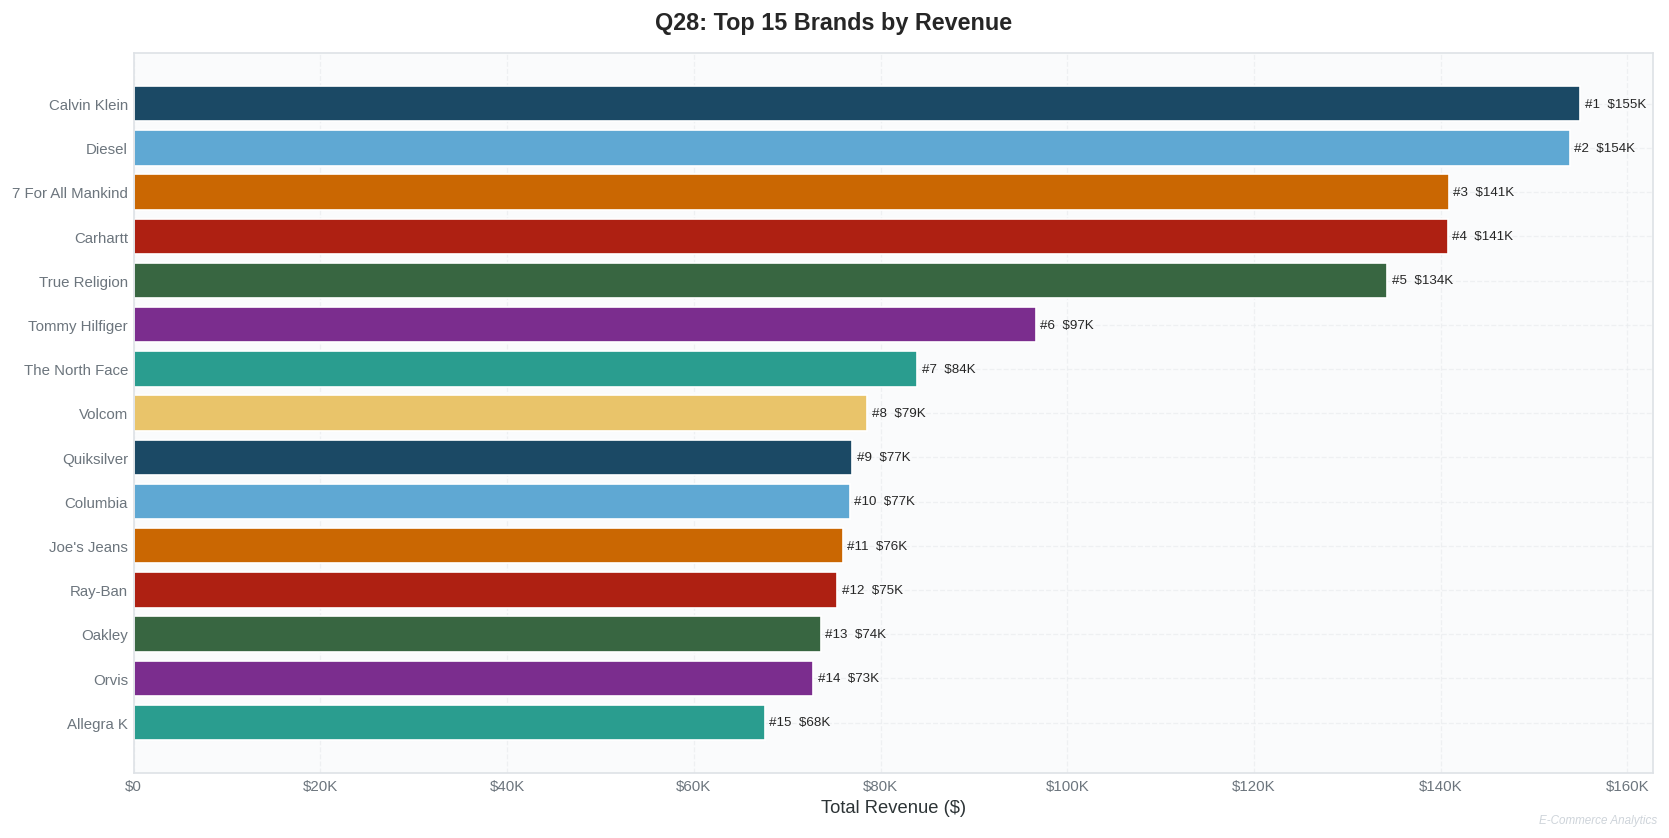

In [35]:
# Q28: DENSE RANK — BRAND REVENUE RANKING
# Business Question: How do brands rank without gaps?

# --- Analysis ---
brand_rev = (df_valid.groupby('brand')['sale_price']
             .sum().reset_index(name='total_revenue')
             .sort_values('total_revenue', ascending=False))

brand_rev['rank_gap'] = brand_rev['total_revenue'].rank(ascending=False, method='min').astype(int)
brand_rev['rank_dense'] = brand_rev['total_revenue'].rank(ascending=False, method='dense').astype(int)
brand_rev['row_num'] = range(1, len(brand_rev) + 1)
brand_rev['total_revenue'] = brand_rev['total_revenue'].round(2)

display(style_table(brand_rev.head(15), "Q28: Brand Revenue Ranking (RANK vs DENSE_RANK)"))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 7))
fig.suptitle('Q28: Top 15 Brands by Revenue', fontsize=14, fontweight='bold')

top15 = brand_rev.head(15)
bars = ax.barh(range(len(top15)), top15['total_revenue'],
               color=PALETTE_8[:len(top15)] * 2, edgecolor='white')
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['brand'], fontsize=9)
ax.set_xlabel('Total Revenue ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax.invert_yaxis()

for bar, rank, val in zip(bars, top15['rank_dense'], top15['total_revenue']):
    ax.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
            f'#{rank}  ${val/1000:.0f}K', va='center', fontsize=8)

plt.tight_layout()
add_watermark(fig)
plt.show()

,category,year_month,revenue,prev_month_rev,mom_change_pct
51,Accessories,2023-04,9064.550000,9713.640000,-6.680000
52,Accessories,2023-05,10295.380000,9064.550000,13.580000
53,Accessories,2023-06,10112.550000,10295.380000,-1.780000
54,Accessories,2023-07,12461.070000,10112.550000,23.220000
55,Accessories,2023-08,11861.290000,12461.070000,-4.810000
56,Accessories,2023-09,12036.930000,11861.290000,1.480000
57,Accessories,2023-10,15992.330000,12036.930000,32.860000
58,Accessories,2023-11,16969.610000,15992.330000,6.110000
59,Accessories,2023-12,19577.940000,16969.610000,15.370000
60,Accessories,2024-01,13797.490000,19577.940000,-29.530000


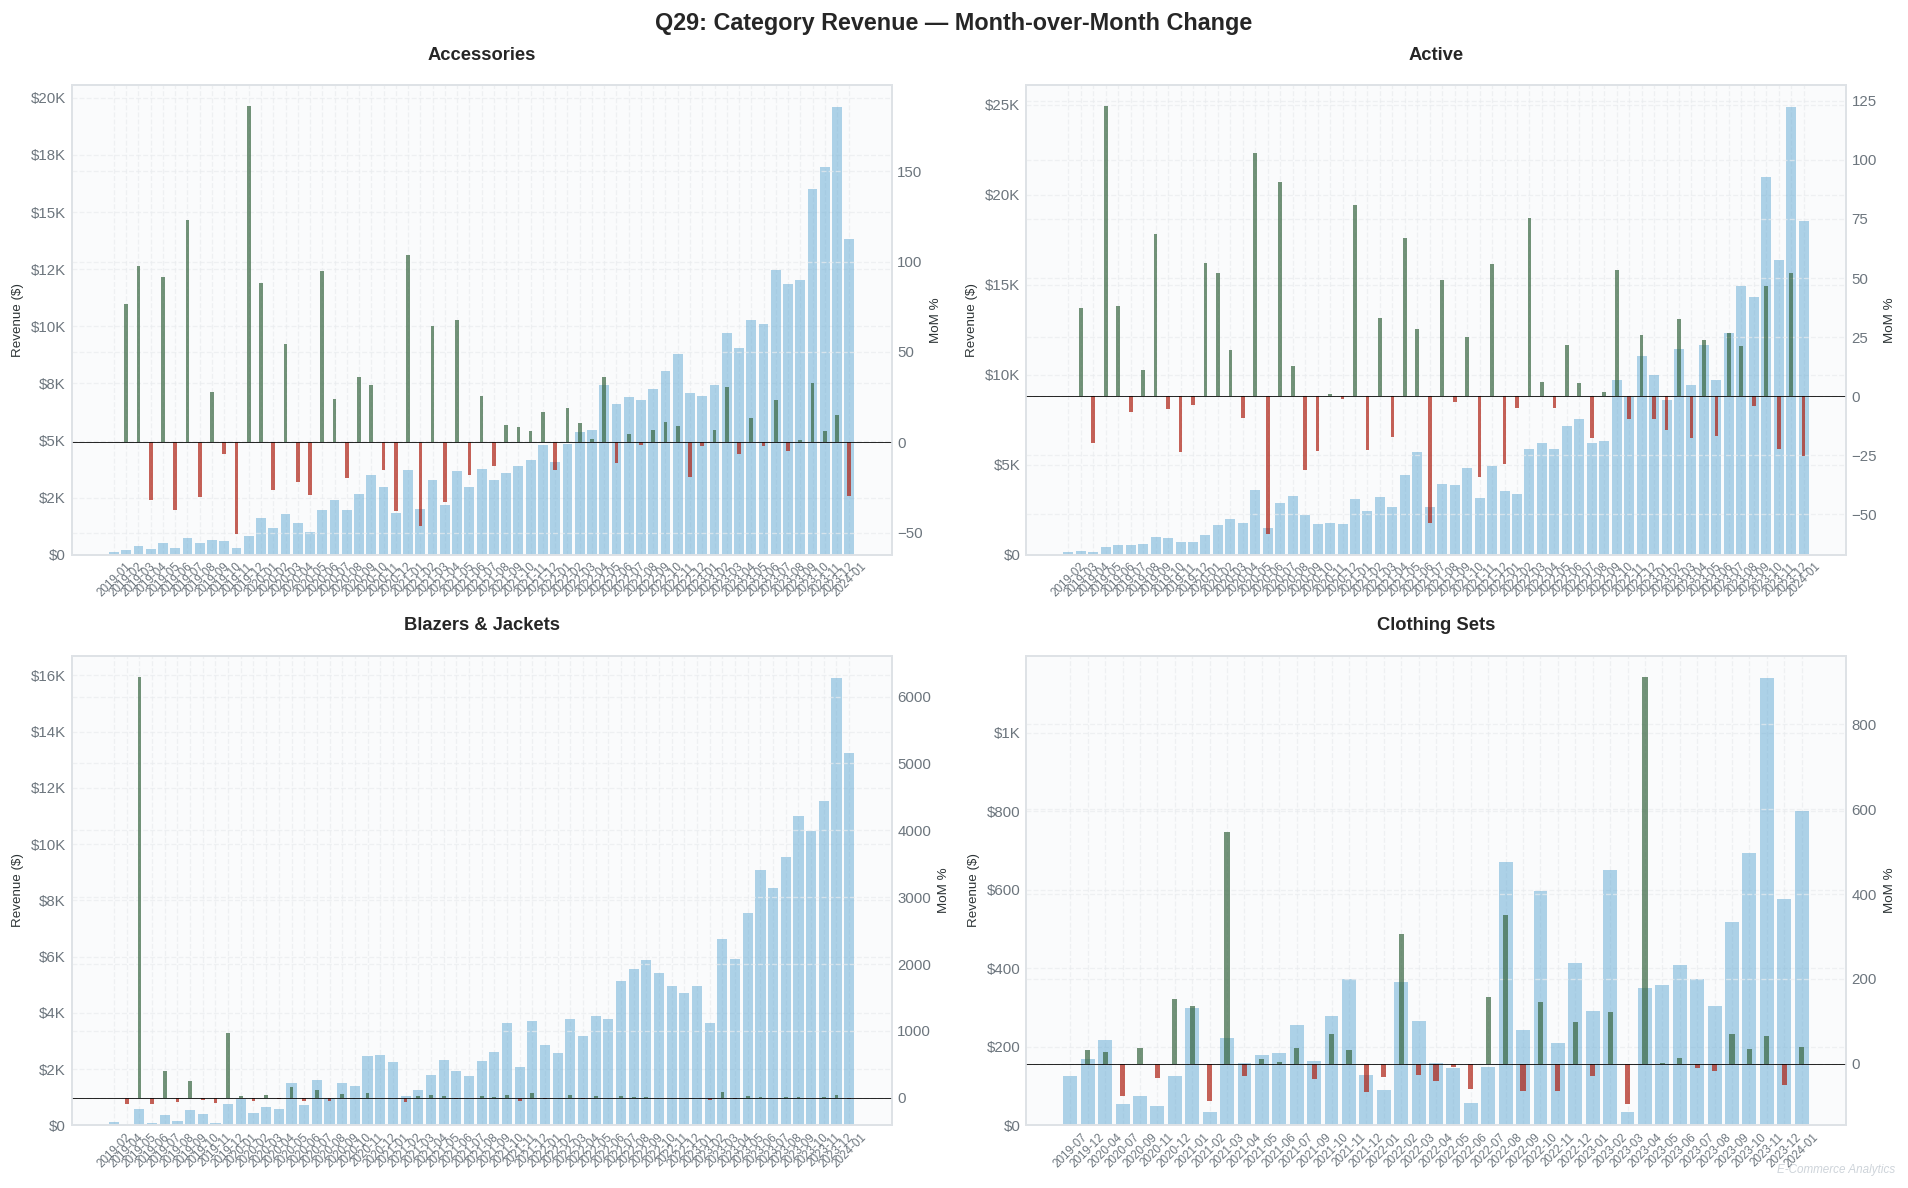

In [36]:
# Q29: LAG/LEAD — CATEGORY REVENUE COMPARISON
# Business Question: How does each category compare to previous month?

# --- Analysis ---
cat_monthly = (df_valid.groupby(['category', 'year_month'])['sale_price']
               .sum().reset_index(name='revenue')
               .sort_values(['category', 'year_month']))

cat_monthly['prev_month_rev'] = cat_monthly.groupby('category')['revenue'].shift(1)
cat_monthly['next_month_rev'] = cat_monthly.groupby('category')['revenue'].shift(-1)
cat_monthly['mom_change_pct'] = (
    (cat_monthly['revenue'] - cat_monthly['prev_month_rev'])
    / cat_monthly['prev_month_rev'] * 100
).round(2)

cat_monthly['revenue'] = cat_monthly['revenue'].round(2)
cat_monthly['prev_month_rev'] = cat_monthly['prev_month_rev'].round(2)

# Show one category as example
sample_cat = cat_monthly['category'].value_counts().index[0]
display(style_table(
    cat_monthly[cat_monthly['category'] == sample_cat]
    [['category', 'year_month', 'revenue', 'prev_month_rev', 'mom_change_pct']].tail(10),
    f"Q29: MoM Comparison — {sample_cat}"
))

# --- Visualization ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Q29: Category Revenue — Month-over-Month Change', fontsize=14, fontweight='bold')

categories = cat_monthly['category'].unique()[:4]
for idx, cat in enumerate(categories):
    ax = axes[idx // 2][idx % 2]
    cat_data = cat_monthly[cat_monthly['category'] == cat]

    ax.bar(cat_data['year_month'], cat_data['revenue'],
           color=COLORS['secondary'], alpha=0.5, label='Revenue')
    ax_twin = ax.twinx()
    valid = cat_data.dropna(subset=['mom_change_pct'])
    colors_mom = [COLORS['success'] if x >= 0 else COLORS['highlight']
                  for x in valid['mom_change_pct']]
    ax_twin.bar(valid['year_month'], valid['mom_change_pct'],
                color=colors_mom, alpha=0.7, width=0.3, label='MoM %')
    ax_twin.axhline(y=0, color='black', linewidth=0.5)

    ax.set_title(cat, fontsize=11)
    ax.set_ylabel('Revenue ($)', fontsize=8)
    ax_twin.set_ylabel('MoM %', fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
    ax.tick_params(axis='x', rotation=45, labelsize=7)

plt.tight_layout()
add_watermark(fig)
plt.show()

,spending_quartile,customer_count,min_spent,max_spent,avg_spent,avg_orders
0,Q1-Low,16568,0.020000,38.590000,23.040000,1.030000
1,Q2-Medium,16608,38.590000,80.000000,57.490000,1.190000
2,Q3-High,16514,80.010000,164.190000,117.140000,1.500000
3,Q4-VIP,16564,164.200000,1738.970000,293.190000,1.960000


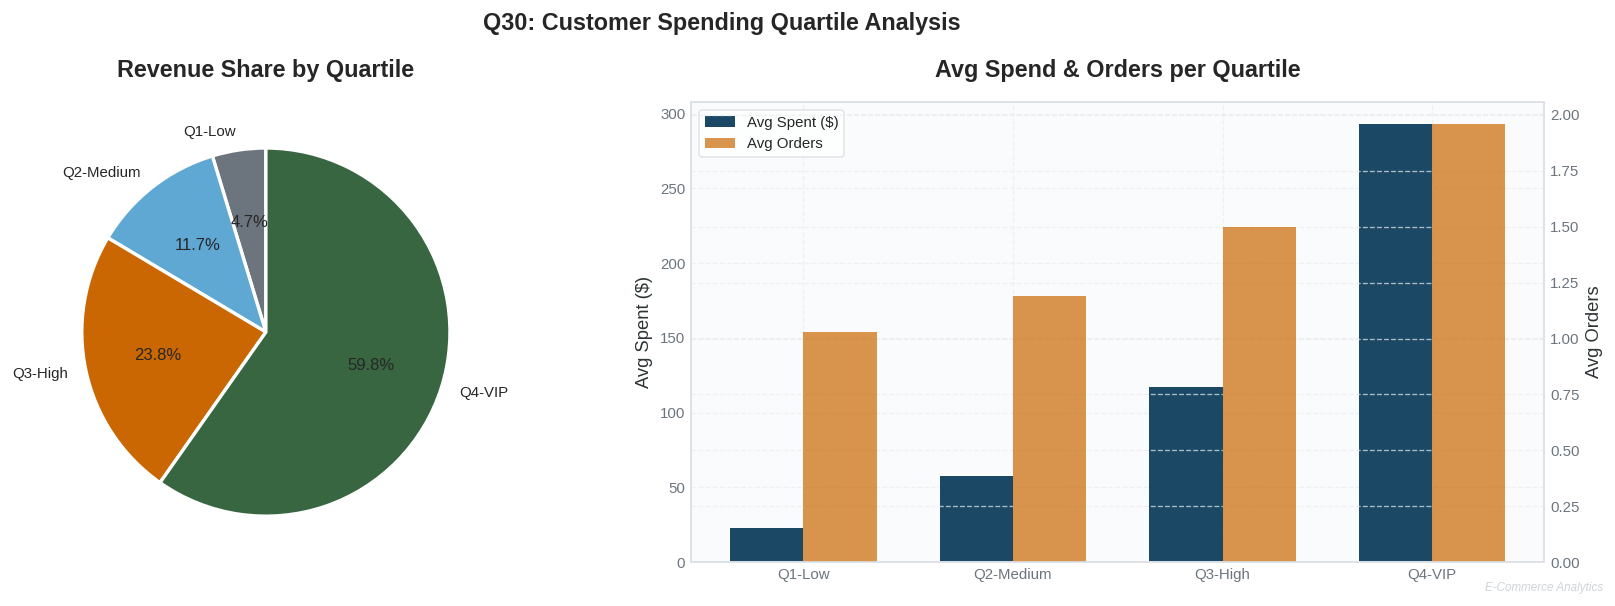

In [37]:

# Q30: NTILE — CUSTOMER SPENDING QUARTILES
# Business Question: How do customer segments differ by spending?

# --- Analysis ---
cust_metrics = (df_valid.groupby('user_id')
                .agg(
                    order_count=('order_id', 'nunique'),
                    total_spent=('sale_price', 'sum'),
                    avg_order_value=('sale_price', 'mean')
                ).reset_index())

cust_metrics['spending_quartile'] = pd.qcut(
    cust_metrics['total_spent'], 4,
    labels=['Q1-Low', 'Q2-Medium', 'Q3-High', 'Q4-VIP'],
    duplicates='drop'
)

q30 = (cust_metrics.groupby('spending_quartile', observed=True)
       .agg(
           customer_count=('user_id', 'count'),
           min_spent=('total_spent', 'min'),
           max_spent=('total_spent', 'max'),
           avg_spent=('total_spent', 'mean'),
           avg_orders=('order_count', 'mean')
       ).round(2).reset_index())

display(style_table(q30, "Q30: Customer Spending Quartiles"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Q30: Customer Spending Quartile Analysis', fontsize=14, fontweight='bold')

# Revenue share per quartile
quartile_rev = (cust_metrics.groupby('spending_quartile', observed=True)['total_spent']
                .sum().sort_index())
q_colors = [COLORS['neutral'], COLORS['secondary'], COLORS['accent'], COLORS['success']]
ax1.pie(quartile_rev.values, labels=quartile_rev.index.astype(str),
        autopct='%1.1f%%', colors=q_colors, startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax1.set_title('Revenue Share by Quartile')

# Avg spend & orders
x = np.arange(len(q30))
width = 0.35
bars1 = ax2.bar(x - width/2, q30['avg_spent'], width,
                label='Avg Spent ($)', color=COLORS['primary'])
ax2_twin = ax2.twinx()
bars2 = ax2_twin.bar(x + width/2, q30['avg_orders'], width,
                     label='Avg Orders', color=COLORS['accent'], alpha=0.7)
ax2.set_xticks(x)
ax2.set_xticklabels(q30['spending_quartile'].astype(str))
ax2.set_ylabel('Avg Spent ($)')
ax2_twin.set_ylabel('Avg Orders')
ax2.set_title('Avg Spend & Orders per Quartile')

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
add_watermark(fig)
plt.show()

## **SECTION 7: ADVANCED BUSINESS**

⚠️ Not enough years of data for YoY comparison.


,year,month,revenue
49,2023.000000,637,203363.650000
50,2023.000000,638,243450.680000
51,2023.000000,639,235181.110000
52,2023.000000,640,258402.760000
53,2023.000000,641,273995.970000
54,2023.000000,642,316434.330000
55,2023.000000,643,330334.930000
56,2023.000000,644,362257.050000
57,2023.000000,645,411154.370000
58,2023.000000,646,429962.240000


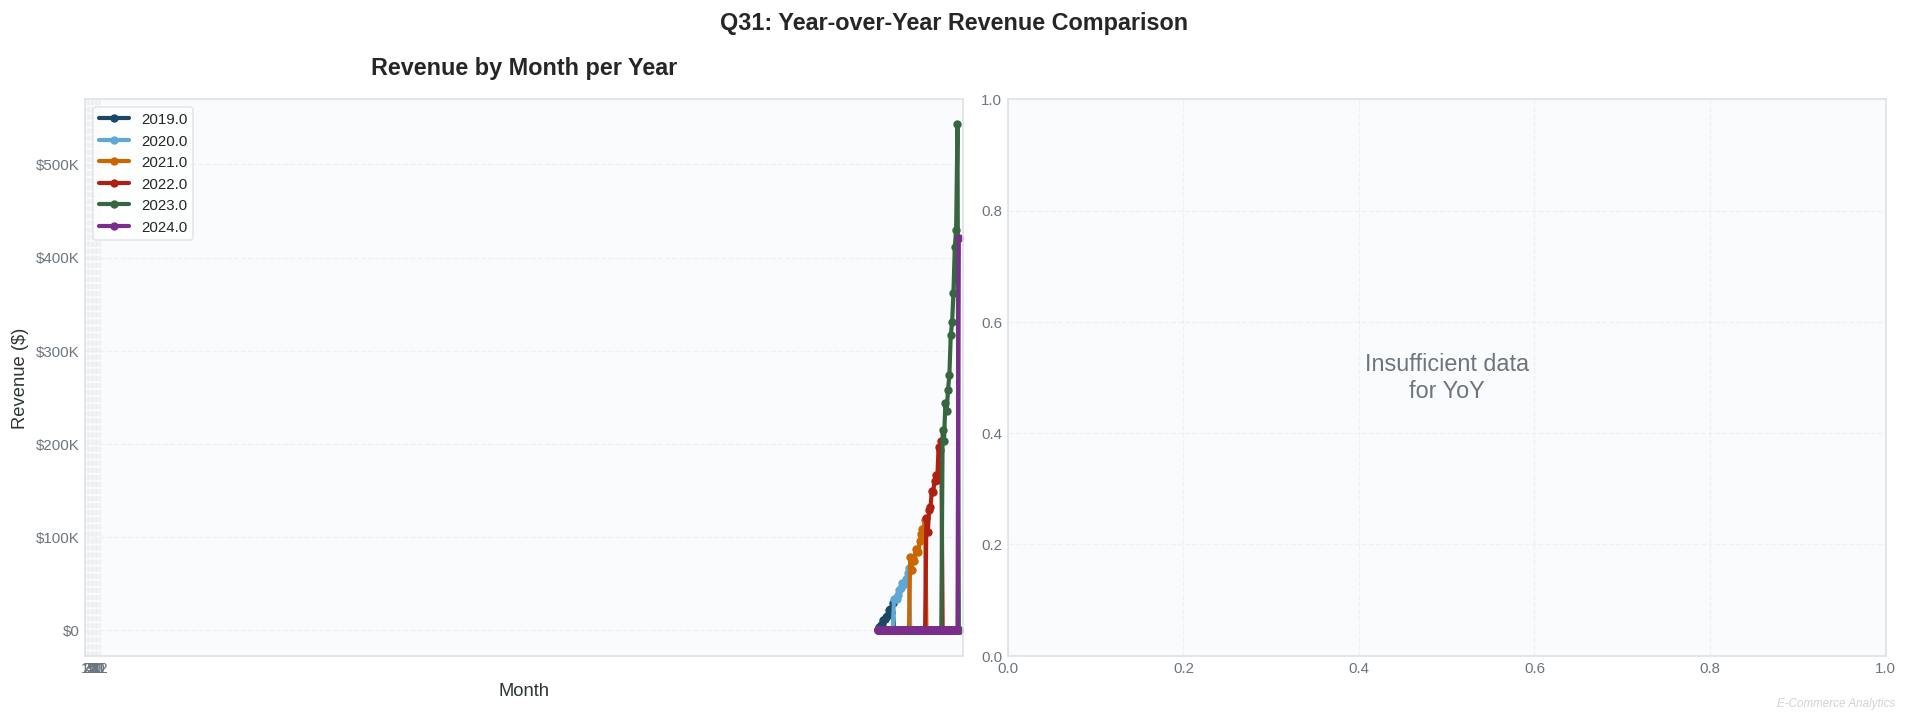

In [38]:
# Q31: YEAR-OVER-YEAR REVENUE COMPARISON
# Business Question: How does this year compare to last year?

# --- Analysis ---
yearly_monthly = (df_valid.groupby(['year', 'month'])['sale_price']
                  .sum().reset_index(name='revenue'))
yearly_monthly['month'] = yearly_monthly['month'].astype(int)
yearly_monthly['revenue'] = yearly_monthly['revenue'].round(2)

# Pivot: rows = month, columns = year
yoy_pivot = yearly_monthly.pivot(index='month', columns='year',
                                  values='revenue').fillna(0)

# Calculate YoY for consecutive years
years = sorted(yoy_pivot.columns)
yoy_results = []
for i in range(1, len(years)):
    prev_yr, curr_yr = years[i-1], years[i]
    for m in range(1, 13):
        if m in yoy_pivot.index:
            prev_rev = yoy_pivot.loc[m, prev_yr] if prev_yr in yoy_pivot.columns else 0
            curr_rev = yoy_pivot.loc[m, curr_yr] if curr_yr in yoy_pivot.columns else 0
            if prev_rev > 0:
                yoy_results.append({
                    'month': m,
                    'prev_year': prev_yr,
                    'prev_revenue': round(prev_rev, 2),
                    'curr_year': curr_yr,
                    'curr_revenue': round(curr_rev, 2),
                    'yoy_growth_pct': round((curr_rev - prev_rev) / prev_rev * 100, 2)
                })

yoy_df = pd.DataFrame(yoy_results)
if len(yoy_df) > 0:
    display(style_table(yoy_df.head(12), "Q31: Year-over-Year Monthly Comparison"))
else:
    print("⚠️ Not enough years of data for YoY comparison.")
    display(style_table(yearly_monthly.tail(12), "Q31: Monthly Revenue (Available Data)"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Q31: Year-over-Year Revenue Comparison', fontsize=14, fontweight='bold')

# Line chart by year
for i, yr in enumerate(years):
    if yr in yoy_pivot.columns:
        ax1.plot(yoy_pivot.index, yoy_pivot[yr],
                 color=PALETTE_8[i % len(PALETTE_8)],
                 linewidth=2.5, marker='o', markersize=4, label=str(yr))
ax1.set_xlabel('Month')
ax1.set_ylabel('Revenue ($)')
ax1.set_xticks(range(1, 13))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency))
ax1.set_title('Revenue by Month per Year')
ax1.legend()

# YoY growth bar
if len(yoy_df) > 0:
    latest_yoy = yoy_df[yoy_df['curr_year'] == years[-1]]
    colors_yoy = [COLORS['success'] if x >= 0 else COLORS['highlight']
                  for x in latest_yoy['yoy_growth_pct']]
    ax2.bar(latest_yoy['month'], latest_yoy['yoy_growth_pct'], color=colors_yoy)
    ax2.axhline(y=0, color='black', linewidth=0.8)
    ax2.set_xlabel('Month')
    ax2.set_ylabel('YoY Growth (%)')
    ax2.set_xticks(range(1, 13))
    ax2.set_title(f'YoY Growth: {years[-1]} vs {years[-2]}')
else:
    ax2.text(0.5, 0.5, 'Insufficient data\nfor YoY', ha='center', va='center',
             fontsize=14, color=COLORS['neutral'])

plt.tight_layout()
add_watermark(fig)
plt.show()

📊 PARETO INSIGHT:
   11845 products (43.8% of all) drive approximately 80% of revenue
   Total products: 27,043



,name,revenue,product_rank,total_products,total_revenue,cumulative_revenue,cumulative_rev_pct,cumulative_prod_pct,pareto_class
23513,The North Face Apex Bionic Soft Shell Jacket - Men's,19866.000000,1,27043,8126820.748586,19866.000000,0.240000,0.000000,Top 80% Revenue
17417,NIKE WOMEN'S PRO COMPRESSION SPORTS BRA *Outstanding Support and Comfort*,13545.000000,2,27043,8126820.748586,33411.000000,0.410000,0.010000,Top 80% Revenue
23512,The North Face Apex Bionic Mens Soft Shell Ski Jacket 2013,12642.000000,3,27043,8126820.748586,46053.000000,0.570000,0.010000,Top 80% Revenue
5419,Canada Goose Women's Solaris,11815.000000,4,27043,8126820.748586,57868.000000,0.710000,0.010000,Top 80% Revenue
5412,Canada Goose Men's The Chateau Jacket,11410.000000,5,27043,8126820.748586,69278.000000,0.850000,0.020000,Top 80% Revenue
23517,The North Face Denali Down Womens Jacket 2013,9933.000000,6,27043,8126820.748586,79211.000000,0.970000,0.020000,Top 80% Revenue
5418,Canada Goose Women's Mystique,9750.000000,7,27043,8126820.748586,88961.000000,1.090000,0.030000,Top 80% Revenue
23525,The North Face Nuptse 2 Jacket Deep Water Blue Mens,8127.000000,8,27043,8126820.748586,97088.000000,1.190000,0.030000,Top 80% Revenue
7981,Diesel Men's Shioner Skinny Straight Leg Jean,6991.600000,9,27043,8126820.748586,104079.599976,1.280000,0.030000,Top 80% Revenue
24369,True Religion Men's Ricky Straight Jean,6839.600000,10,27043,8126820.748586,110919.200073,1.360000,0.040000,Top 80% Revenue


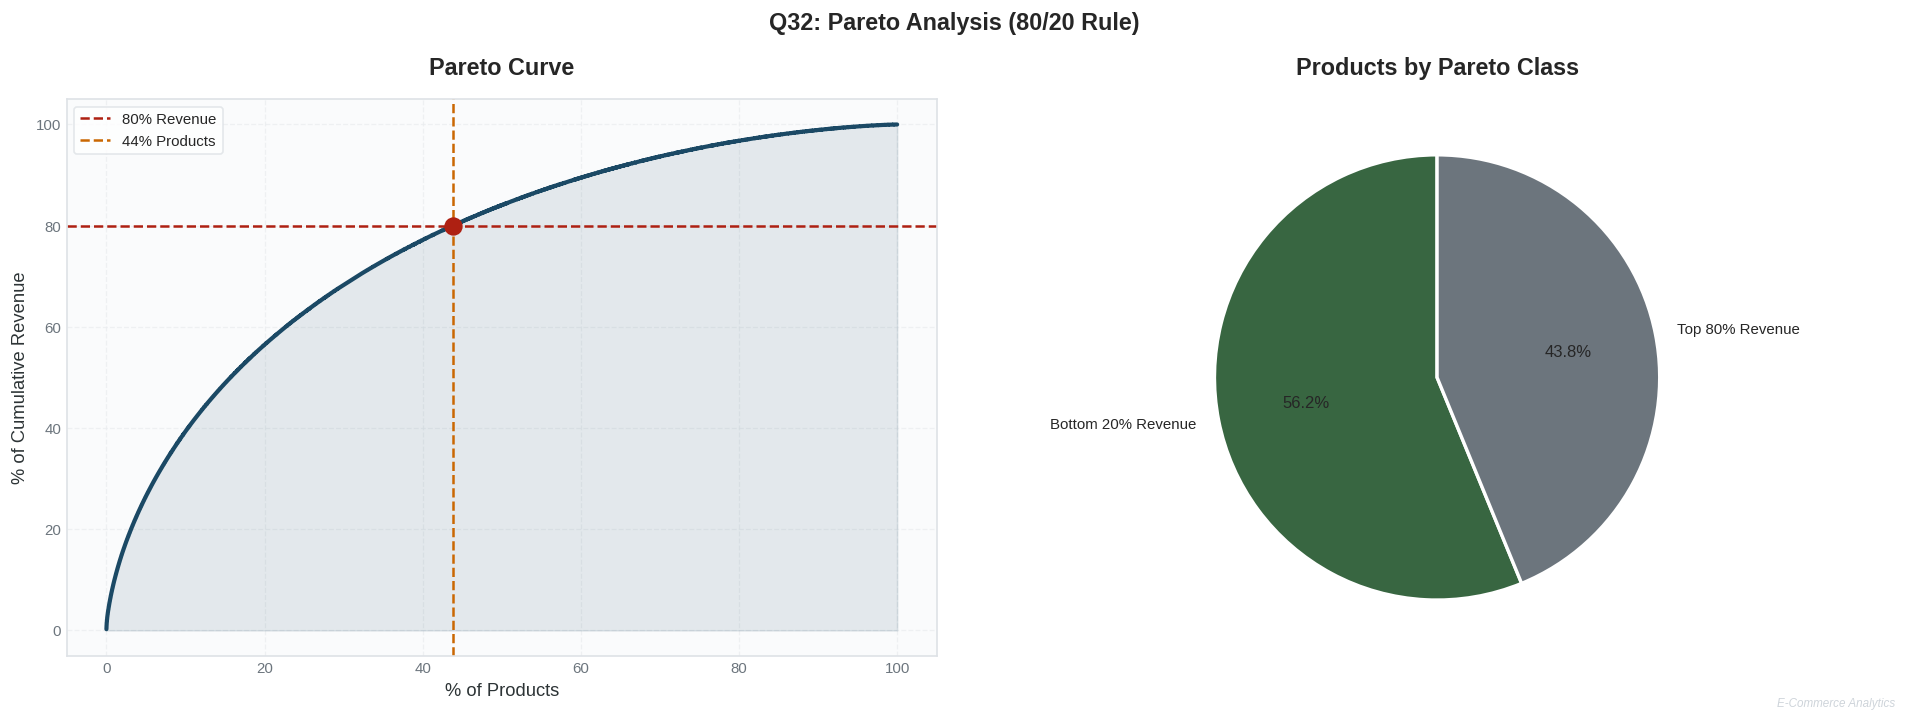

In [40]:
# Q32: PARETO ANALYSIS (80/20 RULE)
# Business Question: Do 20% of products drive 80% of revenue?

# --- Analysis ---
prod_rev = (df_valid.groupby('name')['sale_price']
            .sum().reset_index(name='revenue')
            .sort_values('revenue', ascending=False))

prod_rev['product_rank'] = range(1, len(prod_rev) + 1)
prod_rev['total_products'] = len(prod_rev)
prod_rev['total_revenue'] = prod_rev['revenue'].sum()
prod_rev['cumulative_revenue'] = prod_rev['revenue'].cumsum()
prod_rev['cumulative_rev_pct'] = (
    prod_rev['cumulative_revenue'] / prod_rev['total_revenue'] * 100
).round(2)
prod_rev['cumulative_prod_pct'] = (
    prod_rev['product_rank'] / prod_rev['total_products'] * 100
).round(2)
prod_rev['pareto_class'] = np.where(
    prod_rev['cumulative_rev_pct'] <= 80, 'Top 80% Revenue', 'Bottom 20% Revenue'
)
prod_rev['revenue'] = prod_rev['revenue'].round(2)

# Key stat
products_for_80 = prod_rev.loc[
    prod_rev['cumulative_rev_pct'] <= 80, 'product_rank'
].max()

products_for_80 = int(products_for_80) if pd.notna(products_for_80) else 0

pct_products = products_for_80 / len(prod_rev) * 100

print("📊 PARETO INSIGHT:")
print(f"   {products_for_80} products ({pct_products:.1f}% of all) drive approximately 80% of revenue")
print(f"   Total products: {len(prod_rev):,}\n")

display(style_table(prod_rev.head(10), "Q32: Top 10 Products — Pareto Analysis"))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Q32: Pareto Analysis (80/20 Rule)', fontsize=14, fontweight='bold')

# Cumulative curve
ax1.plot(prod_rev['cumulative_prod_pct'], prod_rev['cumulative_rev_pct'],
         color=COLORS['primary'], linewidth=2.5)
ax1.fill_between(prod_rev['cumulative_prod_pct'], prod_rev['cumulative_rev_pct'],
                 alpha=0.1, color=COLORS['primary'])
ax1.axhline(y=80, color=COLORS['highlight'], linestyle='--', linewidth=1.5, label='80% Revenue')
ax1.axvline(x=pct_products, color=COLORS['accent'], linestyle='--', linewidth=1.5,
            label=f'{pct_products:.0f}% Products')
ax1.plot(pct_products, 80, 'o', color=COLORS['highlight'], markersize=10, zorder=5)
ax1.set_xlabel('% of Products')
ax1.set_ylabel('% of Cumulative Revenue')
ax1.set_title('Pareto Curve')
ax1.legend()

# Pareto class breakdown
pareto_counts = prod_rev['pareto_class'].value_counts()
ax2.pie(pareto_counts.values, labels=pareto_counts.index,
        autopct='%1.1f%%', colors=[COLORS['success'], COLORS['neutral']],
        startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Products by Pareto Class')

plt.tight_layout()
add_watermark(fig)
plt.show()

,category_a,category_b,pair_count,support_pct,confidence_a_to_b,confidence_b_to_a
153,Jeans,Tops & Tees,566,0.600000,6.160000,6.510000
103,Fashion Hoodies & Sweatshirts,Jeans,538,0.570000,6.220000,5.850000
146,Jeans,Sleep & Lounge,523,0.560000,5.690000,6.440000
144,Jeans,Shorts,525,0.560000,5.710000,6.560000
120,Fashion Hoodies & Sweatshirts,Tops & Tees,528,0.560000,6.100000,6.080000
271,Sweaters,Tops & Tees,515,0.550000,6.260000,5.930000
151,Jeans,Sweaters,504,0.540000,5.480000,6.120000
152,Jeans,Swim,501,0.530000,5.450000,6.030000
86,Dresses,Intimates,500,0.530000,12.480000,5.280000
273,Swim,Tops & Tees,490,0.520000,5.900000,5.640000


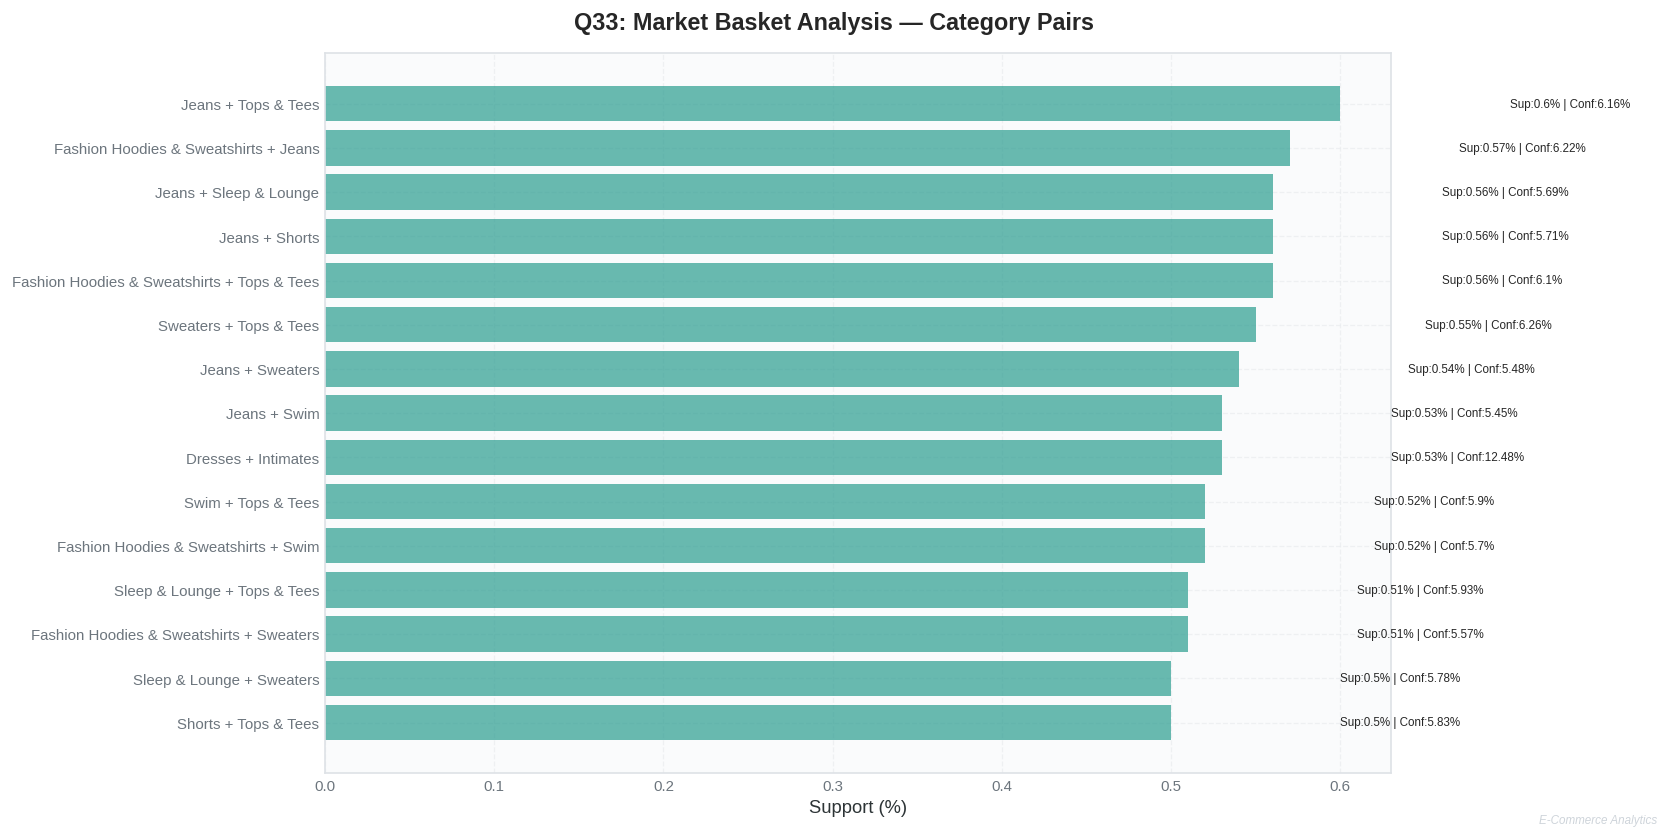

In [45]:

# Q33: MARKET BASKET ANALYSIS
# Business Question: Which categories are frequently bought together?

# --- Analysis ---
order_cats = df_valid[['order_id', 'category']].drop_duplicates()
total_orders = order_cats['order_id'].nunique()

# Self-join for pairs
pairs = order_cats.merge(order_cats, on='order_id', suffixes=('_a', '_b'))
pairs = pairs[pairs['category_a'] < pairs['category_b']]

pair_counts = (pairs.groupby(['category_a', 'category_b'])
               .size().reset_index(name='pair_count'))

# Single category counts
single_counts = order_cats.groupby('category')['order_id'].nunique().reset_index()
single_counts.columns = ['category', 'cat_count']

# Merge for support & confidence
# Merge for support & confidence (FIXED)
basket = pair_counts.merge(single_counts, left_on='category_a', right_on='category')
basket = basket.drop(columns=['category']).rename(columns={'cat_count': 'cat_count_a'})

basket = basket.merge(single_counts, left_on='category_b', right_on='category')
basket = basket.drop(columns=['category']).rename(columns={'cat_count': 'cat_count_b'})

basket['support_pct'] = (basket['pair_count'] / total_orders * 100).round(2)
basket['confidence_a_to_b'] = (basket['pair_count'] / basket['cat_count_a'] * 100).round(2)
basket['confidence_b_to_a'] = (basket['pair_count'] / basket['cat_count_b'] * 100).round(2)
basket = basket.sort_values('support_pct', ascending=False).head(15)

display(style_table(
    basket[['category_a', 'category_b', 'pair_count',
            'support_pct', 'confidence_a_to_b', 'confidence_b_to_a']],
    "Q33: Market Basket — Category Association Rules"
))

# --- Visualization ---
fig, ax = plt.subplots(figsize=(14, 7))
fig.suptitle('Q33: Market Basket Analysis — Category Pairs', fontsize=14, fontweight='bold')

basket['label'] = basket['category_a'] + ' + ' + basket['category_b']
y_pos = range(len(basket))

# Support bars
bars = ax.barh(y_pos, basket['support_pct'], color=COLORS['teal'], alpha=0.7, label='Support %')
ax.set_yticks(y_pos)
ax.set_yticklabels(basket['label'], fontsize=9)
ax.set_xlabel('Support (%)')
ax.invert_yaxis()

for bar, sup, conf in zip(bars, basket['support_pct'], basket['confidence_a_to_b']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'Sup:{sup}% | Conf:{conf}%', va='center', fontsize=7)

plt.tight_layout()
add_watermark(fig)
plt.show()

,country,state,total_orders,unique_customers,total_revenue,avg_order_value,revenue_per_customer
45,China,Guangdong,4959,3557,432429.200000,59.910000,121.570000
176,United Kingdom,England,3796,2671,338709.430000,61.140000,126.810000
184,United States,California,3464,2461,301338.600000,59.880000,122.450000
64,China,Shanghai,2414,1667,201709.980000,58.600000,121.000000
223,United States,Texas,2300,1625,197938.880000,59.230000,121.810000
70,China,Zhejiang,2051,1442,184136.010000,60.190000,127.690000
41,China,Beijing,1965,1382,178508.140000,61.360000,129.170000
49,China,Hebei,2005,1398,171064.760000,58.150000,122.360000
37,Brasil,São Paulo,2010,1394,168458.900000,59.170000,120.850000
55,China,Jiangsu,1775,1253,154812.100000,58.820000,123.550000


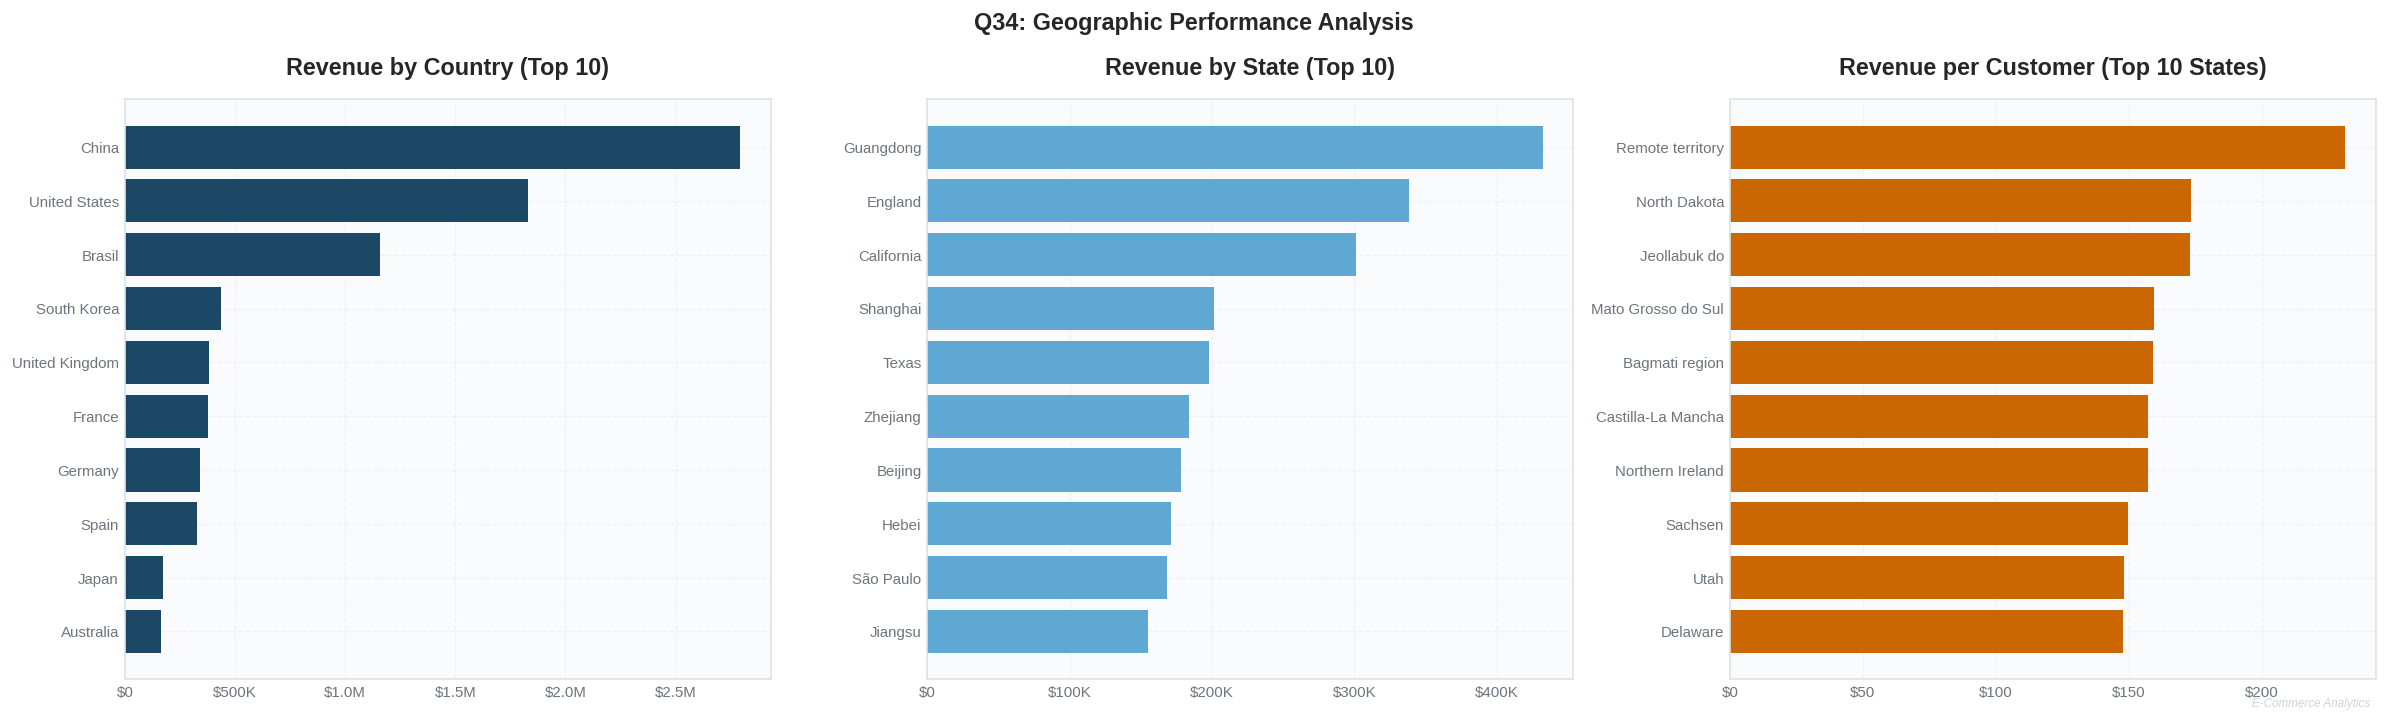

In [42]:

# Q34: GEOGRAPHIC PERFORMANCE
# Business Question: Which regions drive the most revenue?

# --- Analysis ---
geo = (df_valid.merge(users[['id', 'country', 'state', 'city']],
                       left_on='user_id', right_on='id', how='left', suffixes=('', '_u'))
       .groupby(['country', 'state'])
       .agg(
           total_orders=('order_id', 'nunique'),
           unique_customers=('user_id', 'nunique'),
           total_revenue=('sale_price', 'sum'),
           avg_order_value=('sale_price', 'mean')
       ).reset_index())

geo['revenue_per_customer'] = (geo['total_revenue'] / geo['unique_customers']).round(2)
geo['total_revenue'] = geo['total_revenue'].round(2)
geo['avg_order_value'] = geo['avg_order_value'].round(2)
geo = geo[geo['total_orders'] >= 20].sort_values('total_revenue', ascending=False)

display(style_table(geo.head(15), "Q34: Top 15 Regions by Revenue"))

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Q34: Geographic Performance Analysis', fontsize=14, fontweight='bold')

# By Country
country_rev = geo.groupby('country')['total_revenue'].sum().sort_values(ascending=True).tail(10)
axes[0].barh(country_rev.index, country_rev.values, color=COLORS['primary'])
axes[0].set_title('Revenue by Country (Top 10)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))

# Top States
top_states = geo.head(10)
axes[1].barh(top_states['state'].iloc[::-1], top_states['total_revenue'].iloc[::-1],
             color=COLORS['secondary'])
axes[1].set_title('Revenue by State (Top 10)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))

# Revenue per Customer
top_rpc = geo.nlargest(10, 'revenue_per_customer')
axes[2].barh(top_rpc['state'].iloc[::-1], top_rpc['revenue_per_customer'].iloc[::-1],
             color=COLORS['accent'])
axes[2].set_title('Revenue per Customer (Top 10 States)')
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(format_currency))

plt.tight_layout()
add_watermark(fig)
plt.show()

,delivery_bucket,order_count,avg_ship_hours,avg_transit_hours,avg_total_hours,sla_breach,pct_of_orders,sla_breach_pct
0,Within 2 Days,4067,16.200000,16.000000,32.200000,0,13.300000,0.000000
1,3-5 Days,17325,34.400000,51.700000,86.100000,0,56.600000,0.000000
2,5-10 Days,9197,47.700000,96.300000,144.000000,977,30.100000,10.600000


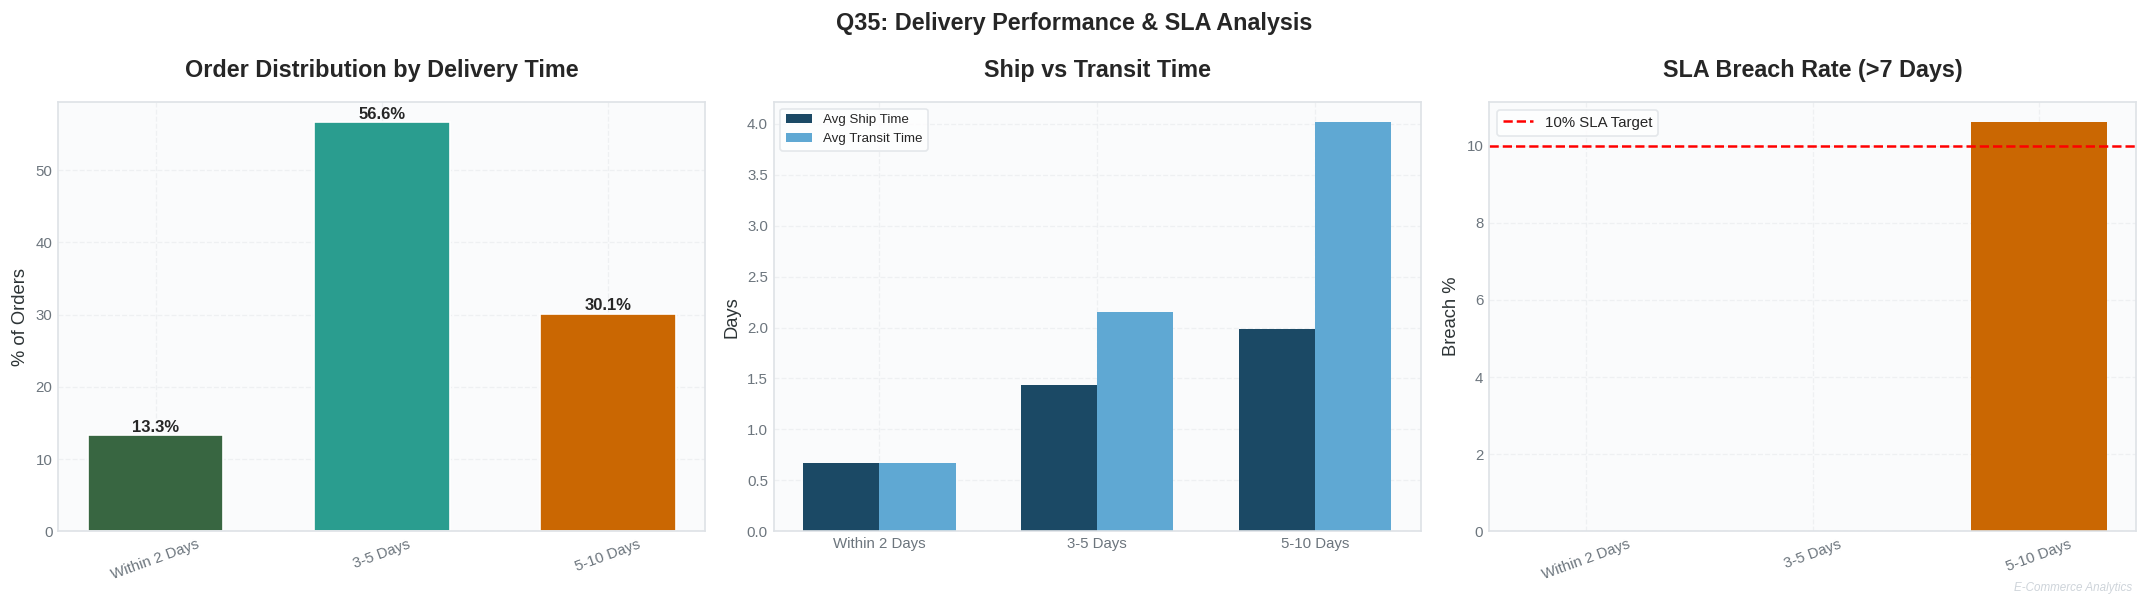

In [46]:

# Q35: DELIVERY PERFORMANCE & SLA BREACH
# Business Question: How fast are orders delivered? Are we breaching SLA?

# --- Analysis ---
delivery = orders.dropna(subset=['created_at', 'shipped_at', 'delivered_at']).copy()
delivery = delivery[delivery['status'] == 'Complete']

delivery['hours_to_ship'] = (delivery['shipped_at'] - delivery['created_at']).dt.total_seconds() / 3600
delivery['hours_in_transit'] = (delivery['delivered_at'] - delivery['shipped_at']).dt.total_seconds() / 3600
delivery['total_delivery_hours'] = (delivery['delivered_at'] - delivery['created_at']).dt.total_seconds() / 3600

delivery['delivery_bucket'] = pd.cut(
    delivery['total_delivery_hours'],
    bins=[-1, 48, 120, 240, float('inf')],
    labels=['Within 2 Days', '3-5 Days', '5-10 Days', 'Over 10 Days']
)

q35 = (delivery.groupby('delivery_bucket', observed=True)
       .agg(
           order_count=('order_id', 'count'),
           avg_ship_hours=('hours_to_ship', 'mean'),
           avg_transit_hours=('hours_in_transit', 'mean'),
           avg_total_hours=('total_delivery_hours', 'mean'),
           sla_breach=('total_delivery_hours', lambda x: (x > 168).sum())  # >7 days
       ).round(1).reset_index())

q35['pct_of_orders'] = (q35['order_count'] / q35['order_count'].sum() * 100).round(1)
q35['sla_breach_pct'] = (q35['sla_breach'] / q35['order_count'] * 100).round(1)

display(style_table(q35, "Q35: Delivery Performance & SLA Breach"))

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Q35: Delivery Performance & SLA Analysis', fontsize=14, fontweight='bold')

# Delivery bucket distribution
del_colors = [COLORS['success'], COLORS['teal'], COLORS['accent'], COLORS['highlight']]
bars = axes[0].bar(q35['delivery_bucket'].astype(str), q35['pct_of_orders'],
                   color=del_colors, width=0.6, edgecolor='white')
axes[0].set_title('Order Distribution by Delivery Time')
axes[0].set_ylabel('% of Orders')
axes[0].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, q35['pct_of_orders']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val}%', ha='center', fontweight='bold')

# Ship vs Transit breakdown
x = np.arange(len(q35))
width = 0.35
axes[1].bar(x - width/2, q35['avg_ship_hours']/24, width,
            label='Avg Ship Time', color=COLORS['primary'])
axes[1].bar(x + width/2, q35['avg_transit_hours']/24, width,
            label='Avg Transit Time', color=COLORS['secondary'])
axes[1].set_xticks(x)
axes[1].set_xticklabels(q35['delivery_bucket'].astype(str), fontsize=9)
axes[1].set_ylabel('Days')
axes[1].set_title('Ship vs Transit Time')
axes[1].legend(fontsize=8)

# SLA Breach
sla_colors = [COLORS['success'] if x < 5 else COLORS['accent'] if x < 20 else COLORS['highlight']
              for x in q35['sla_breach_pct']]
bars = axes[2].bar(q35['delivery_bucket'].astype(str), q35['sla_breach_pct'],
                   color=sla_colors, width=0.6)
axes[2].axhline(y=10, color='red', linestyle='--', label='10% SLA Target')
axes[2].set_title('SLA Breach Rate (>7 Days)')
axes[2].set_ylabel('Breach %')
axes[2].legend()
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
add_watermark(fig)
plt.show()

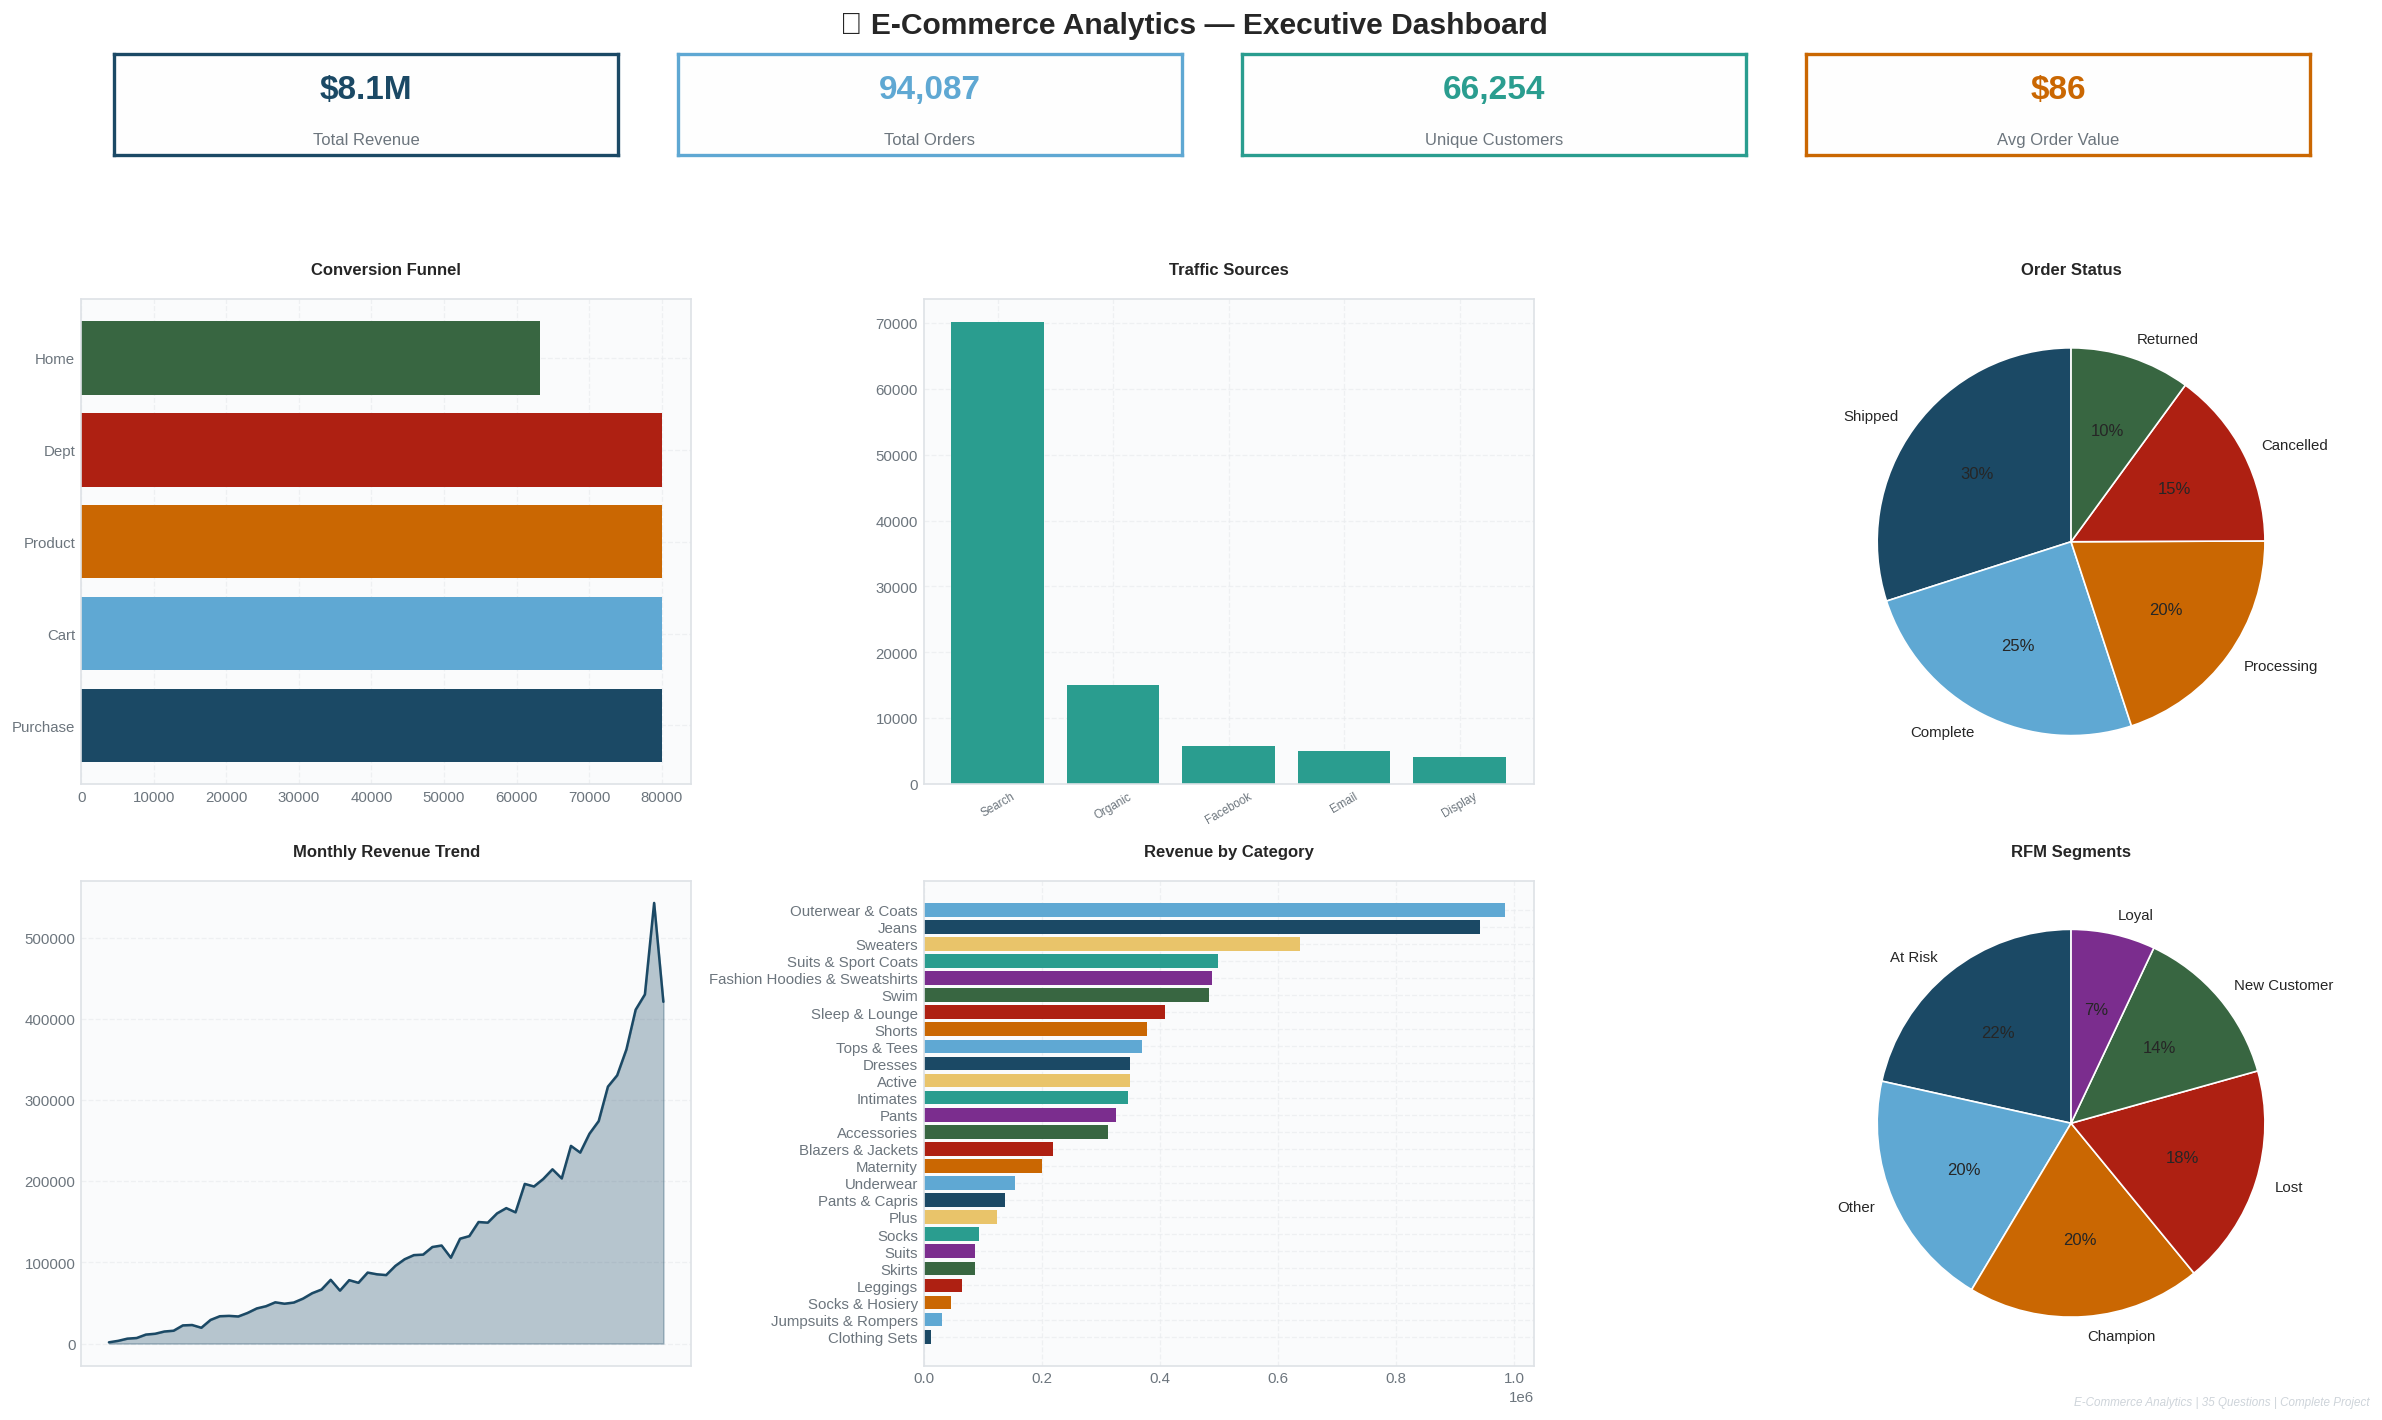


🎉 PROJECT COMPLETE!
  ✅ 35 Business Questions Answered
  ✅ 8 Analysis Sections Covered
  ✅ Professional Visualizations Generated
  ✅ Executive Dashboard Created
  📁 Dashboard saved as: executive_dashboard.png


In [44]:
# ============================================================
# 🎯 FINAL PROJECT SUMMARY DASHBOARD
# ============================================================

fig = plt.figure(figsize=(20, 12))
fig.suptitle('📊 E-Commerce Analytics — Executive Dashboard',
             fontsize=18, fontweight='bold', y=0.98)

# KPI Cards
total_rev = df_valid['sale_price'].sum()
total_orders = df_valid['order_id'].nunique()
total_customers = df_valid['user_id'].nunique()
avg_aov = df_valid.groupby('order_id')['sale_price'].sum().mean()

kpis = [
    ('Total Revenue', f'${total_rev/1e6:.1f}M', COLORS['primary']),
    ('Total Orders', f'{total_orders:,}', COLORS['secondary']),
    ('Unique Customers', f'{total_customers:,}', COLORS['teal']),
    ('Avg Order Value', f'${avg_aov:.0f}', COLORS['accent']),
]

for i, (label, value, color) in enumerate(kpis):
    ax = fig.add_axes([0.05 + i*0.235, 0.88, 0.21, 0.07])
    ax.text(0.5, 0.65, value, ha='center', va='center',
            fontsize=20, fontweight='bold', color=color)
    ax.text(0.5, 0.15, label, ha='center', va='center',
            fontsize=10, color=COLORS['neutral'])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    for spine in ax.spines.values():
        spine.set_color(color); spine.set_linewidth(2)
    ax.set_xticks([]); ax.set_yticks([])
    ax.patch.set_alpha(0.05)

# Mini charts
# 1. Monthly Revenue
ax1 = fig.add_subplot(2, 3, 4)
monthly = df_valid.groupby('year_month')['sale_price'].sum()
ax1.fill_between(range(len(monthly)), monthly.values, color=COLORS['primary'], alpha=0.3)
ax1.plot(range(len(monthly)), monthly.values, color=COLORS['primary'], linewidth=1.5)
ax1.set_title('Monthly Revenue Trend', fontsize=10)
ax1.set_xticks([])

# 2. Category Revenue
ax2 = fig.add_subplot(2, 3, 5)
cat = df_valid.groupby('category')['sale_price'].sum().sort_values(ascending=True)
ax2.barh(cat.index, cat.values, color=PALETTE_8[:len(cat)])
ax2.set_title('Revenue by Category', fontsize=10)

# 3. Customer Segments
ax3 = fig.add_subplot(2, 3, 6)
seg = rfm['segment'].value_counts()
ax3.pie(seg.values, labels=seg.index, autopct='%1.0f%%',
        colors=PALETTE_8[:len(seg)], startangle=90,
        wedgeprops={'edgecolor': 'white'})
ax3.set_title('RFM Segments', fontsize=10)

# 4. Funnel
ax4 = fig.add_subplot(2, 3, 1)
funnel_vals = [events[events['event_type']==s]['user_id'].nunique()
               for s in ['home', 'department', 'product', 'cart', 'purchase']]
ax4.barh(['Home', 'Dept', 'Product', 'Cart', 'Purchase'][::-1],
         funnel_vals[::-1], color=PALETTE_8[:5])
ax4.set_title('Conversion Funnel', fontsize=10)

# 5. Traffic Sources
ax5 = fig.add_subplot(2, 3, 2)
traffic = users['traffic_source'].value_counts()
ax5.bar(traffic.index, traffic.values, color=COLORS['teal'])
ax5.set_title('Traffic Sources', fontsize=10)
ax5.tick_params(axis='x', rotation=30, labelsize=7)

# 6. Return Rate
ax6 = fig.add_subplot(2, 3, 3)
status = order_items['status'].value_counts()
ax6.pie(status.values, labels=status.index, autopct='%1.0f%%',
        colors=PALETTE_8[:len(status)], startangle=90,
        wedgeprops={'edgecolor': 'white'})
ax6.set_title('Order Status', fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.85])
add_watermark(fig, "E-Commerce Analytics | 35 Questions | Complete Project")
plt.savefig('executive_dashboard.png', dpi=200, bbox_inches='tight')
plt.show()

print("\n" + "=" * 60)
print("🎉 PROJECT COMPLETE!")
print("=" * 60)
print(f"  ✅ 35 Business Questions Answered")
print(f"  ✅ 8 Analysis Sections Covered")
print(f"  ✅ Professional Visualizations Generated")
print(f"  ✅ Executive Dashboard Created")
print(f"  📁 Dashboard saved as: executive_dashboard.png")
print("=" * 60)